# 01 Exploratory data analysis (training block only)

One notebook for the whole EDA: a profile of the raw table, the descriptive overview behind
`reports/eda_findings.md`, and the checks behind the feature and column choices.

**Data.** The training block is the validated `data/processed/cleaned.parquet` (built by
`python -m src.clean_data`; the same values as `joined.parquet`), loaded through `src/eda.py`. Blocks follow
`src/split.py`: train = the first 472,432 rows by time, then validation and test.

**Scope rule:** all label-based analysis uses the **training block only**. The validation block is used **without
its labels**, mainly in Section 11 to measure shift, and also for customer overlap (5.1, 5.2) and the over-time plots
(7.1). The test block (last 10%) is never touched.

Sections:
1. Overview and class balance
2. The features: column groups, first rows, categorical values, descriptive statistics
3. Missingness, including the V-column blocks
4. Fraud over time
5. Customer structure (label clustering, implications for CV)
6. Categorical features vs fraud
7. Numeric features vs fraud
8. Behavioural feature preview (past-only)
9. Domain-knowledge hypotheses: supported or not?
10. Redundancy among C and D columns
11. Shift between training and validation blocks (no labels)
12. Findings to carry into the report
13. Proposed columns to exclude from model inputs

**Files written.** Running the notebook regenerates `reports/eda/` (CSV tables and `summary.json`) and
`reports/eda_findings.md` through `src/eda.py`, and saves the seven figures that report links to
(`reports/figures/eda_*.png`, gitignored). Everything else is shown inline only. The per-column profile and the
original V-column proposal (`reports/data_profile.md`, `config/features.yaml`) are written by
`python -m src.data_profile`, not by this notebook.

In [1]:
import contextlib
import io
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Find the repo root (the folder that contains src/), whether the notebook runs from the root or from notebooks/
ROOT = Path.cwd()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import eda as eda_report
from src.data import load_joined
from src.split import holdout_indices

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
BLUE, RED = "#4C72B0", "#C44E52"

FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    """Save a figure that reports/eda_findings.md links to, then show it."""
    fig.savefig(FIGURES / f"eda_{name}.png", dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()

In [2]:
# Training block from cleaned.parquet. src/eda.py also writes reports/eda/ and reports/eda_findings.md here.
with contextlib.redirect_stdout(io.StringIO()):
    tr, tables, summary = eda_report.run()

# Validation block (labels removed on purpose), using the same split function as the models
full = load_joined()
train_idx, val_idx, _ = holdout_indices(full)
assert len(tr) == len(train_idx) == 472_432
assert (tr["TransactionID"].to_numpy() == full["TransactionID"].to_numpy()[train_idx]).all()
va = full.iloc[val_idx].drop(columns="isFraud").copy()
del full

OVERALL = tr["isFraud"].mean()
print(f"training block: {len(tr):,} rows, days {tr.TransactionDay.min()}-{tr.TransactionDay.max()}, fraud rate {OVERALL:.4f}")
print(f"validation block (unlabelled here): {len(va):,} rows, days {va.TransactionDay.min()}-{va.TransactionDay.max()}")

training block: 472,432 rows, days 1-141, fraud rate 0.0351
validation block (unlabelled here): 59,054 rows, days 141-161


In [3]:
# Helpers used throughout

def wilson(k, n, z=1.96):
    """95% Wilson interval for a proportion k/n."""
    k = np.asarray(k, float); n = np.asarray(n, float)
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half

def rate_table(frame, key, top=None, min_n=0):
    """Fraud rate per value of `key` (a column name or a Series), with counts and a 95% CI. NaN is its own group."""
    s = frame[key] if isinstance(key, str) else key
    s = s.astype(object).where(s.notna(), "(missing)")
    g = frame["isFraud"].groupby(s.values).agg(n="size", fraud="sum")
    g = g[g["n"] >= min_n].sort_values("n", ascending=False)
    if top:
        g = g.head(top)
    g["rate"] = g["fraud"] / g["n"]
    g["lo"], g["hi"] = wilson(g["fraud"], g["n"])
    return g

def plot_rate(tab, title, ax):
    """Horizontal bars of fraud rate with CI; the label shows n so small groups are obvious."""
    tab = tab.iloc[::-1]
    labels = [f"{i}  (n={n:,})" for i, n in zip(tab.index, tab["n"])]
    err = np.vstack([tab["rate"] - tab["lo"], tab["hi"] - tab["rate"]])
    ax.barh(labels, tab["rate"], xerr=err, color="#4C72B0", ecolor="grey", capsize=2)
    ax.axvline(OVERALL, ls="--", color="#C44E52", label=f"overall {OVERALL:.3f}")
    ax.set_title(title); ax.set_xlabel("fraud rate"); ax.legend(loc="lower right", fontsize=8)

def rate_by_quantile(frame, s, q=10):
    """Fraud rate across quantile bins of a numeric Series (ties may merge bins). NaN is shown separately."""
    bins = pd.qcut(s, q=q, duplicates="drop")
    tab = rate_table(frame, bins.astype(str).where(s.notna()))
    order = [str(c) for c in bins.cat.categories if str(c) in tab.index]
    if "(missing)" in tab.index:
        order.append("(missing)")
    return tab.loc[order]

In [4]:
def value_rates(key, values, frame=None):
    """Fraud rate for chosen values of a column, plus each value's share of all fraud in the block.
    `key` is a column name or a Series aligned with `frame`."""
    frame = tr if frame is None else frame
    s = frame[key] if isinstance(key, str) else key
    t = rate_table(frame, s)
    t = t.loc[[v for v in values if v in t.index]]
    t["share of all fraud"] = t["fraud"] / frame["isFraud"].sum()
    return t[["n", "fraud", "rate", "lo", "hi", "share of all fraud"]]

## 1. Overview and class balance

In [5]:
print(f"rows: {len(tr):,}, columns: {tr.shape[1]}")
print(f"fraud rows: {int(tr.isFraud.sum()):,} ({OVERALL:.2%})")
print(f"rows with identity record: {tr.has_identity.mean():.1%}")
print()
print("column dtypes:")
print(tr.dtypes.astype(str).value_counts().to_string())

rows: 472,432, columns: 436
fraud rows: 16,599 (3.51%)
rows with identity record: 25.5%

column dtypes:
float32     400
category     31
int32         2
int8          2
int16         1


**Class balance.** No sampling or balancing is applied anywhere in the project.

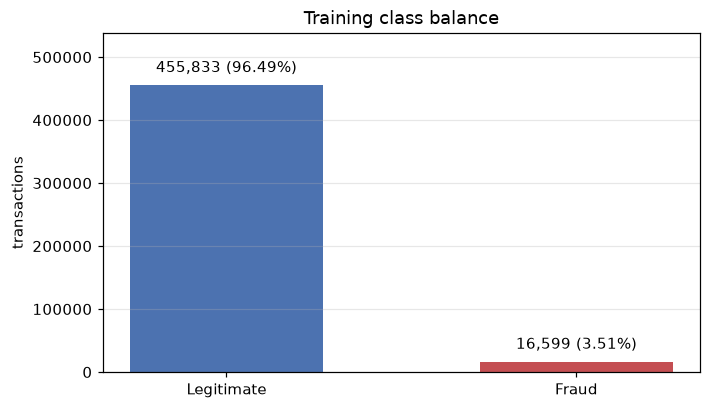

In [6]:
balance = tables["class_balance"].set_index("group").loc[["0", "1"]]
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(["Legitimate", "Fraud"], balance["rows"], color=[BLUE, RED], width=0.55)
ax.bar_label(bars, labels=[f"{n:,} ({n / len(tr):.2%})" for n in balance["rows"]], padding=6)
ax.set_ylim(0, balance["rows"].max() * 1.18)
ax.set_ylabel("transactions"); ax.set_title("Training class balance"); ax.grid(axis="x")
save(fig, "class_balance")

**What this shows.** 3.5% of training transactions are fraud (16,599 of 472,432). Accuracy would hide how well a
model finds the minority class, so the project uses PR-AUC as the main metric. About a quarter of rows have an
identity record.

## 2. The features

Before looking at fraud, a quick look at what is actually in the table. The 436 columns fall into a few groups. Most are masked by Vesta, so for many of them we only know roughly what they represent; the descriptions below follow Vesta's data description.

In [7]:
COL_GROUPS = [
    ("ID and time", r"TransactionID|TransactionDT|TransactionDay", "row ID; seconds from an unknown start; day number (added in src/data.py)"),
    ("Target", r"isFraud", "1 = fraud"),
    ("Amount and product", r"TransactionAmt|ProductCD", "payment amount in USD; product code"),
    ("Card", r"card[1-6]", "card details: card4 = network, card6 = debit/credit, the rest masked"),
    ("Address", r"addr[12]", "addr1 = billing region, addr2 = billing country (masked)"),
    ("Distance", r"dist[12]", "masked distances, e.g. between addresses"),
    ("Email", r"[PR]_emaildomain", "purchaser and recipient email domains"),
    ("C (counts)", r"C\d+", "counts, e.g. how many addresses are linked to the card (masked)"),
    ("D (time deltas)", r"D\d+", "days between events, e.g. days since the previous transaction (masked)"),
    ("M (match flags)", r"M\d", "match checks, e.g. name on card vs address (T/F)"),
    ("V (Vesta features)", r"V\d+", "features engineered by Vesta: ranks, counts and other relations (masked)"),
    ("Identity", r"id_\d+|DeviceType|DeviceInfo|has_identity", "device, browser, OS and network info; only for some rows"),
]

def col_group(c):
    for name, pattern, _ in COL_GROUPS:
        if re.fullmatch(pattern, c):
            return name
    return "other"

groups = pd.Series({c: col_group(c) for c in tr.columns})
group_table = pd.DataFrame([
    {"group": name,
     "n_columns": (groups == name).sum(),
     "columns": ", ".join(groups.index[groups == name][:6]) + (" ..." if (groups == name).sum() > 6 else ""),
     "dtypes": ", ".join(sorted(tr[groups.index[groups == name]].dtypes.astype(str).unique())),
     "avg % missing": round(100 * tr[groups.index[groups == name]].isna().mean().mean(), 1),
     "description": desc}
    for name, _, desc in COL_GROUPS
]).set_index("group")
assert group_table["n_columns"].sum() == tr.shape[1], "some columns are not in a group"
group_table

,n_columns,columns,dtypes,avg % missing,description
group,,,,,
ID and time,3,"TransactionID, TransactionDT, TransactionDay","int16, int32",0.0,row ID; seconds from an unknown start; day num...
Target,1,isFraud,int8,0.0,1 = fraud
Amount and product,2,"TransactionAmt, ProductCD","category, float32",0.0,payment amount in USD; product code
Card,6,"card1, card2, card3, card4, card5, card6","category, float32",0.4,"card details: card4 = network, card6 = debit/c..."
Address,2,"addr1, addr2",float32,11.4,"addr1 = billing region, addr2 = billing countr..."
Distance,2,"dist1, dist2",float32,77.0,"masked distances, e.g. between addresses"
Email,2,"P_emaildomain, R_emaildomain",category,45.8,purchaser and recipient email domains
C (counts),14,"C1, C2, C3, C4, C5, C6 ...",float32,0.0,"counts, e.g. how many addresses are linked to ..."
D (time deltas),15,"D1, D2, D3, D4, D5, D6 ...",float32,58.9,"days between events, e.g. days since the previ..."


### 2.1 First rows

`head()` of every non-V column (V columns shown separately below, since there are 339 of them). Rows are in time order, so these are the earliest transactions.

In [8]:
v_like = [c for c in tr.columns if groups[c] == "V (Vesta features)"]
non_v = [c for c in tr.columns if c not in v_like]
with pd.option_context("display.max_columns", None):
    display(tr[non_v].head())

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,addr1,addr2,dist1,dist2,P_emaildomain,R_emaildomain,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11,C12,C13,C14,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10,D11,D12,D13,D14,D15,M1,M2,M3,M4,M5,M6,M7,M8,M9,id_01,id_02,id_03,id_04,id_05,id_06,id_07,id_08,id_09,id_10,id_11,id_12,id_13,id_14,id_15,id_16,id_17,id_18,id_19,id_20,id_21,id_22,id_23,id_24,id_25,id_26,id_27,id_28,id_29,id_30,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo,TransactionDay,has_identity
0,2987000,0,86400,68.5,W,13926.0,NaN,150.0,discover,142.0,credit,315.0,87.0,19.0,NaN,NaN,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,2.0,0.0,1.0,1.0,14.0,NaN,13.0,NaN,NaN,NaN,NaN,NaN,NaN,13.0,13.0,NaN,NaN,NaN,0.0,T,T,T,M2,F,T,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,0
1,2987001,0,86401,29.0,W,2755.0,404.0,150.0,mastercard,102.0,credit,325.0,87.0,NaN,NaN,gmail.com,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,M0,T,T,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,0
2,2987002,0,86469,59.0,W,4663.0,490.0,150.0,visa,166.0,debit,330.0,87.0,287.0,NaN,outlook.com,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,0.0,315.0,NaN,NaN,NaN,315.0,T,T,T,M0,F,F,F,F,F,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,0
3,2987003,0,86499,50.0,W,18132.0,567.0,150.0,mastercard,117.0,debit,476.0,87.0,NaN,NaN,yahoo.com,NaN,2.0,5.0,0.0,0.0,0.0,4.0,0.0,0.0,1.0,0.0,1.0,0.0,25.0,1.0,112.0,112.0,0.0,94.0,0.0,NaN,NaN,NaN,NaN,84.0,NaN,NaN,NaN,NaN,111.0,NaN,NaN,NaN,M0,T,F,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,0
4,2987004,0,86506,50.0,H,4497.0,514.0,150.0,mastercard,102.0,credit,420.0,87.0,NaN,NaN,gmail.com,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,1.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,70787.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.0,NotFound,NaN,-480.0,New,NotFound,166.0,NaN,542.0,144.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,New,NotFound,Android 7.0,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M,1,1


In [9]:
with pd.option_context("display.max_columns", 30):
    display(tr[v_like].head())

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,...,V325,V326,V327,V328,V329,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,1.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,1.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### 2.2 Categorical features

There are two kinds of categorical columns:

- **Text columns** stored as `category` (ProductCD, card4, card6, email domains, M flags, the text id columns, DeviceType, DeviceInfo).
- **Numeric codes** that are really categories even though they are stored as numbers: `card1`, `card2`, `card3`, `card5`, `addr1`, `addr2`. Their numeric value has no meaning (card1 = 5000 is not "bigger" than card1 = 4000), so they are listed here too.

The table shows the number of distinct values, % missing and the most common values.

In [10]:
CODED_CATS = ["card1", "card2", "card3", "card5", "addr1", "addr2"]
cat_cols = [c for c in tr.columns if isinstance(tr[c].dtype, pd.CategoricalDtype)] + CODED_CATS

def top_values(s, k=5):
    vc = s.value_counts(dropna=True).head(k)
    return ", ".join(f"{v} ({n / len(s):.1%})" for v, n in vc.items())

cat_summary = pd.DataFrame([
    {"column": c, "group": groups[c], "n_unique": tr[c].nunique(), "% missing": round(100 * tr[c].isna().mean(), 1),
     "top 5 values (share of rows)": top_values(tr[c])}
    for c in cat_cols
]).set_index("column")
with pd.option_context("display.max_rows", 100, "display.max_colwidth", 120):
    display(cat_summary)

,group,n_unique,% missing,top 5 values (share of rows)
column,,,,
ProductCD,Amount and product,5,0.0,"W (73.2%), C (11.9%), R (6.8%), H (6.3%), S (1.7%)"
card4,Card,4,0.2,"visa (65.2%), mastercard (31.9%), american express (1.5%), discover (1.1%)"
card6,Card,4,0.2,"debit (74.1%), credit (25.8%), debit or credit (0.0%), charge card (0.0%)"
P_emaildomain,Email,59,15.6,"gmail.com (38.7%), yahoo.com (17.1%), hotmail.com (7.9%), anonymous.com (6.3%), aol.com (4.8%)"
R_emaildomain,Email,60,75.9,"gmail.com (10.0%), hotmail.com (4.9%), anonymous.com (3.7%), yahoo.com (1.9%), aol.com (0.7%)"
M1,M (match flags),2,50.4,"T (49.6%), F (0.0%)"
M2,M (match flags),2,50.4,"T (44.5%), F (5.1%)"
M3,M (match flags),2,50.4,"T (39.1%), F (10.4%)"
M4,M (match flags),3,48.1,"M0 (32.8%), M2 (10.3%), M1 (8.8%)"


Full list of values for the columns with 20 or fewer distinct values, with row counts (missing shown as `NaN`):

In [11]:
for c in cat_summary.index[cat_summary["n_unique"] <= 20]:
    vc = tr[c].value_counts(dropna=False)
    print(f"{c} ({len(vc)} values incl. missing): " + ", ".join(f"{v}={n:,}" for v, n in vc.items()))

ProductCD (5 values incl. missing): W=346,001, C=56,410, R=32,203, H=29,691, S=8,127
card4 (5 values incl. missing): visa=308,141, mastercard=150,862, american express=7,202, discover=5,394, nan=833
card6 (5 values incl. missing): debit=349,843, credit=121,716, nan=828, debit or credit=30, charge card=15
M1 (3 values incl. missing): nan=238,295, T=234,116, F=21
M2 (3 values incl. missing): nan=238,295, T=210,007, F=24,130
M3 (3 values incl. missing): nan=238,295, T=184,780, F=49,357
M4 (4 values incl. missing): nan=227,191, M0=155,071, M2=48,778, M1=41,392
M5 (3 values incl. missing): nan=283,514, F=104,333, T=84,585
M6 (3 values incl. missing): F=179,001, T=152,016, nan=141,415
M7 (3 values incl. missing): nan=299,980, F=149,126, T=23,326
M8 (3 values incl. missing): nan=299,974, F=109,063, T=63,395
M9 (3 values incl. missing): nan=299,974, T=145,732, F=26,726
id_12 (3 values incl. missing): nan=351,968, NotFound=104,387, Found=16,077
id_15 (4 values incl. missing): nan=354,636, Found

### 2.3 Numeric features: descriptive statistics

`describe()` for every numeric column, one table per column group, with % missing and the number of distinct values added. Columns listed in 2.2 as numeric codes are left out, since their mean and std don't mean anything. Summary statistics ignore missing values, so read them together with the % missing column.

In [12]:
SKIP = set(CODED_CATS) | {"TransactionID", "isFraud"}
num_cols = [c for c in tr.columns if pd.api.types.is_numeric_dtype(tr[c]) and c not in SKIP]

def describe_group(cols):
    d = tr[cols].astype("float64").describe().T
    d.insert(0, "% missing", (100 * tr[cols].isna().mean()).round(1))
    d.insert(1, "n_unique", tr[cols].nunique())
    return d.drop(columns="count").round(3)

num_groups = [g for g in group_table.index if any(groups[c] == g for c in num_cols) and g != "V (Vesta features)"]
for g in num_groups:
    cols = [c for c in num_cols if groups[c] == g]
    print(f"--- {g} ({len(cols)} columns)")
    with pd.option_context("display.max_rows", 100):
        display(describe_group(cols))

--- ID and time (2 columns)


,% missing,n_unique,mean,std,min,25%,50%,75%,max
TransactionDT,0.0,457939,5715961.442,3559869.184,86400.0,2310158.25,5592303.5,8745778.5,12192842.0
TransactionDay,0.0,141,65.560,41.202,1.0,26.00,64.0,101.0,141.0


--- Amount and product (1 columns)


,% missing,n_unique,mean,std,min,25%,50%,75%,max
TransactionAmt,0.0,18131,134.401,237.558,0.251,42.95,68.95,125.0,31937.391


--- Distance (2 columns)


,% missing,n_unique,mean,std,min,25%,50%,75%,max
dist1,60.8,2589,121.456,375.523,0.0,3.0,9.0,25.0,10286.0
dist2,93.2,1664,237.775,537.444,0.0,7.0,38.0,219.0,11623.0


... (2 outputs left out)

--- D (time deltas) (15 columns)


,% missing,n_unique,mean,std,min,25%,50%,75%,max
D1,0.2,641,90.642,153.210,0.0,0.000,1.000,116.000,640.000
D2,49.0,641,167.268,173.317,0.0,25.000,97.000,275.000,640.000
D3,46.1,609,28.642,62.405,0.0,1.000,8.000,27.000,731.000
D4,29.6,767,134.975,184.729,-122.0,0.000,22.000,248.000,825.000
D5,53.7,640,42.401,88.287,0.0,1.000,10.000,32.000,801.000
D6,87.6,781,63.981,138.588,-83.0,0.000,0.000,23.000,829.000
D7,93.7,568,44.718,102.504,0.0,0.000,0.000,21.000,801.000
D8,87.0,11359,149.701,235.170,0.0,0.958,41.833,192.542,1707.792
D9,87.0,24,0.560,0.319,0.0,0.208,0.667,0.833,0.958
D10,14.1,777,118.335,176.312,0.0,0.000,12.000,186.000,830.000


--- Identity (24 columns)


,% missing,n_unique,mean,std,min,25%,50%,75%,max
id_01,74.5,71,-9.928,14.176,-100.0,-10.0,-5.0,-5.0,0.0
id_02,75.1,99487,171218.444,153406.105,1.0,69447.5,124418.0,221715.0,999595.0
id_03,88.6,24,0.062,0.615,-13.0,0.0,0.0,0.0,10.0
id_04,88.6,15,-0.060,0.707,-28.0,0.0,0.0,0.0,0.0
id_05,75.8,90,1.728,5.289,-72.0,0.0,0.0,1.0,52.0
id_06,75.8,100,-6.632,16.501,-100.0,-6.0,0.0,0.0,0.0
id_07,99.1,82,13.804,11.321,-46.0,5.0,14.0,22.0,61.0
id_08,99.1,93,-38.854,26.152,-100.0,-49.0,-34.0,-23.0,0.0
id_09,87.0,43,0.099,0.984,-36.0,0.0,0.0,0.0,25.0
id_10,87.0,59,-0.310,2.851,-100.0,0.0,0.0,0.0,0.0


V columns (339 rows). Many are counts with a small number of distinct values, and several have very large maximums compared with their 75th percentile, i.e. long right tails.

In [13]:
with pd.option_context("display.max_rows", 400):
    display(describe_group(v_like))

,% missing,n_unique,mean,std,min,25%,50%,75%,max
V1,52.1,2,1.000,0.008,0.0,1.0,1.0,1.000,1.000
V2,52.1,7,1.040,0.219,0.0,1.0,1.0,1.000,6.000
V3,52.1,7,1.071,0.300,0.0,1.0,1.0,1.000,6.000
V4,52.1,6,0.841,0.435,0.0,1.0,1.0,1.000,5.000
V5,52.1,7,0.872,0.471,0.0,1.0,1.0,1.000,6.000
V6,52.1,7,1.041,0.221,0.0,1.0,1.0,1.000,6.000
V7,52.1,8,1.067,0.285,0.0,1.0,1.0,1.000,7.000
V8,52.1,7,1.024,0.166,0.0,1.0,1.0,1.000,6.000
V9,52.1,7,1.037,0.207,0.0,1.0,1.0,1.000,6.000
V10,52.1,5,0.462,0.519,0.0,0.0,0.0,1.000,4.000


## 3. Missingness

A lot of this table is empty, so missingness gets its own section. Four questions: how much is missing, which column groups are affected, whether columns go missing together in blocks, and whether being missing is itself related to fraud.

**Identity record**. The following code chunk investigates how many data from the training set has an identity record. It appears that about 25.50% of training data has a corresponding identity. Out of these the transactions with an identity record, 7.55% are fraudulent, while it is only 2.13% among transactions without an identity record.

In [26]:
print(f"Proportion of transactions in the training set with an identity record {tr['has_identity'].mean() * 100}%")
print(f"Proportion of fraudulent transactions among training transactions with an identity record {tr[tr['has_identity'] == 1]['isFraud'].mean() * 100}%")
print(f"Proportion of fraudulent transactions among training transactions without an identity record {tr[tr['has_identity'] == 0]['isFraud'].mean() * 100}%")

Proportion of transactions in the training set with an identity record 25.498696108646325%
Proportion of fraudulent transactions among training transactions with an identity record 7.553293930136805%
Proportion of fraudulent transactions among training transactions without an identity record 2.130875534139467%


**By column group.** Average and range of the missing rate within each group, plus how many columns in the group are more than 50% / 90% missing.

In [15]:
col_miss = tr.drop(columns=["isFraud"]).isna().mean()
grp = groups.drop("isFraud")
miss_by_group = col_miss.groupby(grp).agg(n_columns="size", mean="mean", min="min", max="max")
miss_by_group["cols > 50% missing"] = (col_miss > 0.5).groupby(grp).sum()
miss_by_group["cols > 90% missing"] = (col_miss > 0.9).groupby(grp).sum()
miss_by_group[["mean", "min", "max"]] = (100 * miss_by_group[["mean", "min", "max"]]).round(1)
miss_by_group.rename(columns={"mean": "mean %", "min": "min %", "max": "max %"}).sort_values("mean %", ascending=False)

,n_columns,mean %,min %,max %,cols > 50% missing,cols > 90% missing
Identity,41,81.7,0.0,99.2,40,10
Distance,2,77.0,60.8,93.2,2,1
D (time deltas),15,58.9,0.2,93.7,9,1
M (match flags),9,53.3,29.9,63.5,7,0
Email,2,45.8,15.6,75.9,1,0
V (Vesta features),339,43.0,0.0,85.2,170,0
Address,2,11.4,11.4,11.4,0,0
Card,6,0.4,0.0,1.5,0,0
Amount and product,2,0.0,0.0,0.0,0,0
C (counts),14,0.0,0.0,0.0,0,0


**Most-missing non-V columns.** V columns are covered by the block analysis further down.

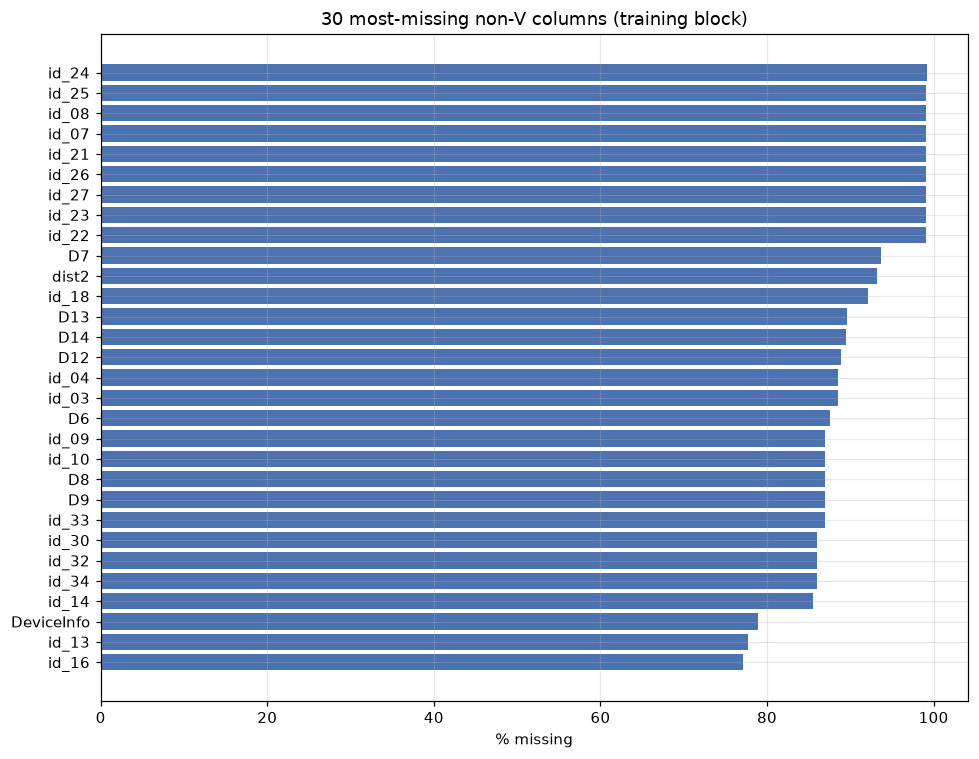

In [16]:
top_miss = col_miss[[c for c in col_miss.index if groups[c] != "V (Vesta features)"]].sort_values(ascending=False).head(30)
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top_miss.index[::-1], 100 * top_miss.values[::-1], color="#4C72B0")
ax.set_xlabel("% missing"); ax.set_title("30 most-missing non-V columns (training block)")
fig.tight_layout(); save(fig, "missingness")

**Missing values per row.** If fraud rows tend to have more (or fewer) empty fields, the count of missing values is a signal on its own.

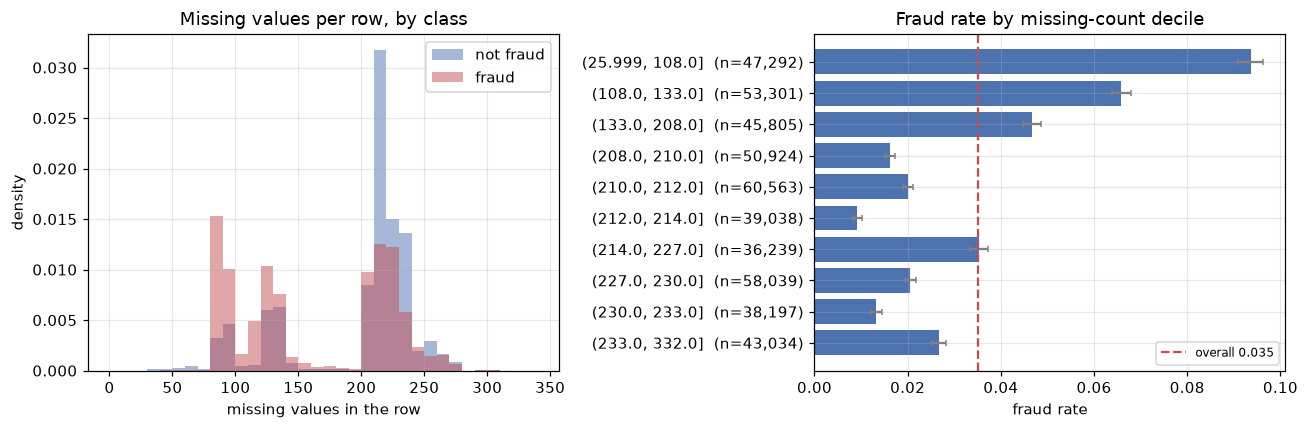

In [17]:
row_miss = tr.drop(columns=["isFraud"]).isna().sum(axis=1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bins = np.arange(0, row_miss.max() + 10, 10)
for label, colr in [(0, "#4C72B0"), (1, "#C44E52")]:
    axes[0].hist(row_miss[tr.isFraud == label], bins=bins, density=True, alpha=0.5, color=colr,
                 label="fraud" if label else "not fraud")
axes[0].set_xlabel("missing values in the row"); axes[0].set_ylabel("density"); axes[0].legend()
axes[0].set_title("Missing values per row, by class")
plot_rate(rate_by_quantile(tr, row_miss, 10), "Fraud rate by missing-count decile", axes[1])
fig.tight_layout(); plt.show()

**Missingness over time.** If the missing rate of a column group changes across the six months (e.g. identity data collected more often later on), models trained on early data will see a different pattern at validation time.

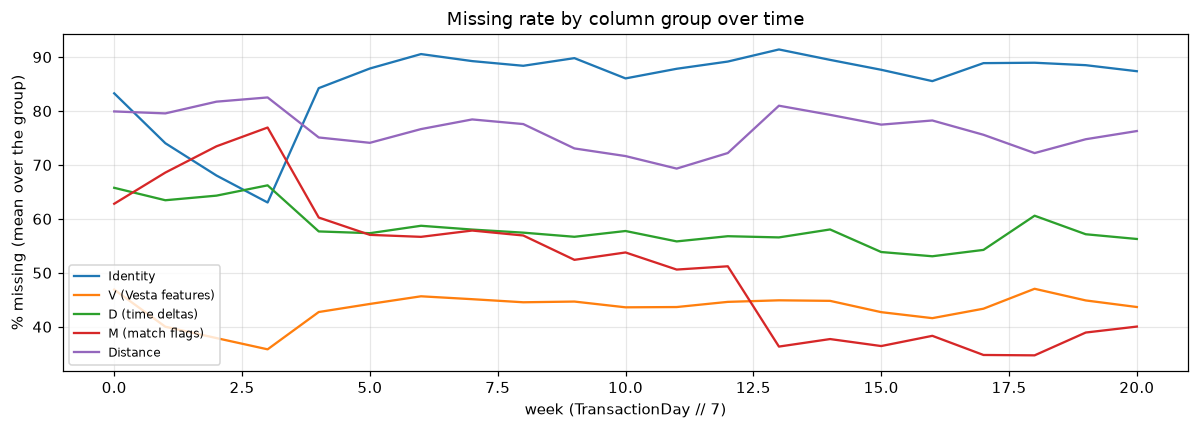

In [18]:
week = tr["TransactionDay"] // 7
fig, ax = plt.subplots(figsize=(11, 4))
for g in ["Identity", "V (Vesta features)", "D (time deltas)", "M (match flags)", "Distance"]:
    cols = [c for c in tr.columns if groups[c] == g and c != "has_identity"]
    ax.plot(tr[cols].isna().mean(axis=1).groupby(week).mean() * 100, label=g)
ax.set_xlabel("week (TransactionDay // 7)"); ax.set_ylabel("% missing (mean over the group)")
ax.set_title("Missing rate by column group over time"); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

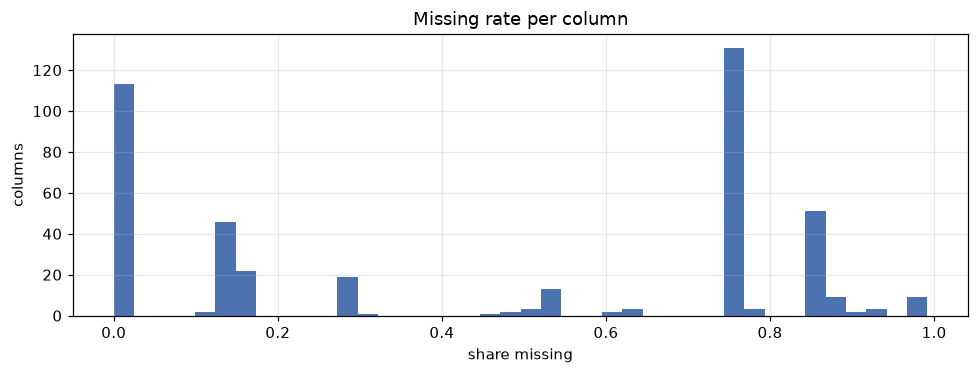

columns with no missing values: 21
columns more than 90% missing: 12


In [19]:
miss = tr.drop(columns=["isFraud"]).isna().mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(miss, bins=40, color="#4C72B0")
ax.set_xlabel("share missing"); ax.set_ylabel("columns"); ax.set_title("Missing rate per column")
fig.tight_layout(); plt.show()

print(f"columns with no missing values: {(miss == 0).sum()}")
print(f"columns more than 90% missing: {(miss > 0.9).sum()}")

**Blocks.** Grouping V columns by their number of missing values shows the block structure. The same count
doesn't guarantee the same rows, so `same rows` checks that every column in a block is missing on exactly the same
rows: all 14 blocks are.

In [20]:
v_cols = [c for c in tr.columns if c.startswith("V")]
v_na = tr[v_cols].isna().sum()
blocks = (v_na.groupby(v_na).apply(lambda s: list(s.index))
          .rename("columns").to_frame())
blocks["n_cols"] = blocks["columns"].str.len()
blocks["share_missing"] = blocks.index / len(tr)
blocks["first..last"] = blocks["columns"].map(lambda c: f"{c[0]}..{c[-1]}")
blocks["same rows"] = blocks["columns"].map(lambda c: bool(tr[c].isna().eq(tr[c[0]].isna(), axis=0).all().all()))
blocks[["n_cols", "share_missing", "same rows", "first..last"]].sort_values("share_missing")

,n_cols,share_missing,same rows,first..last
12,32,0.000025,True,V279..V321
97,43,0.000205,True,V95..V137
936,11,0.001981,True,V281..V315
66427,23,0.140606,True,V12..V34
66890,22,0.141587,True,V53..V74
77793,20,0.164665,True,V75..V94
139809,18,0.295935,True,V35..V52
245973,11,0.520653,True,V1..V11
354412,16,0.750186,True,V220..V272
355767,19,0.753054,True,V169..V210


**Which other columns share each block's missing pattern?** If a V block goes missing on (almost) the same rows as a D or M column, the block was probably computed from the same underlying record. That supports pruning V columns block by block, and it means one missing-pattern feature per block carries the same information as many per-column flags.

In [21]:
non_v = [c for c in tr.columns if not c.startswith("V") and c != "isFraud"]
na_other = tr[non_v].isna()
na_other = na_other.loc[:, na_other.any()]          # only columns that are ever missing

def same_pattern(cols, min_agree=0.99):
    # non-V columns whose missing/present pattern agrees with the block's on at least 99% of rows
    m = tr[cols[0]].isna().to_numpy()
    agree = (na_other.to_numpy() == m[:, None]).mean(axis=0)
    hits = pd.Series(agree, index=na_other.columns)
    hits = hits[hits >= min_agree].sort_values(ascending=False)
    return ", ".join(f"{c} ({a:.1%})" for c, a in hits.items()) or "-"

# blocks that are almost never missing trivially "agree" with every other rarely-missing column, so skip them
blocks["non-V columns with (almost) the same missing rows"] = [
    same_pattern(cols) if share >= 0.01 else "(rarely missing)"
    for cols, share in zip(blocks["columns"], blocks["share_missing"])]
with pd.option_context("display.max_colwidth", 110):
    display(blocks[["n_cols", "share_missing", "first..last", "non-V columns with (almost) the same missing rows"]]
            .sort_values("share_missing"))

# rows where the block and its matching D column disagree on missing vs present
for v, d in [("V1", "D11"), ("V12", "D10"), ("V35", "D4"), ("V75", "D15")]:
    print(f"{v} block vs {d}: missing state differs on {int((tr[v].isna() != tr[d].isna()).sum())} rows")


,n_cols,share_missing,first..last,non-V columns with (almost) the same missing rows
12,32,0.000025,V279..V321,(rarely missing)
97,43,0.000205,V95..V137,(rarely missing)
936,11,0.001981,V281..V315,(rarely missing)
66427,23,0.140606,V12..V34,D10 (100.0%)
66890,22,0.141587,V53..V74,-
77793,20,0.164665,V75..V94,D15 (100.0%)
139809,18,0.295935,V35..V52,D4 (100.0%)
245973,11,0.520653,V1..V11,D11 (100.0%)
354412,16,0.750186,V220..V272,"id_01 (99.4%), id_12 (99.4%), id_11 (99.2%), id_15 (99.2%), id_28 (99.2%), id_29 (99.2%), id_35 (99.2%), i..."
355767,19,0.753054,V169..V210,"id_35 (99.8%), id_38 (99.8%), id_37 (99.8%), id_11 (99.8%), id_36 (99.8%), id_15 (99.8%), id_28 (99.8%), i..."


V1 block vs D11: missing state differs on 0 rows
V12 block vs D10: missing state differs on 36 rows
V35 block vs D4: missing state differs on 35 rows
V75 block vs D15: missing state differs on 28 rows


**Missing vs present.** For every column that is between 1% and 99% missing, compare the fraud rate when missing and when present. One representative column per missing-count group is kept, so a single block does not fill the list.

In [22]:
cand = miss[(miss > 0.01) & (miss < 0.99)]
rep = cand.groupby(cand.round(6)).apply(lambda s: s.index[0])
rows = []
for col in rep:
    m = tr[col].isna()
    rows.append({"column": col, "share_missing": m.mean(),
                 "rate_if_missing": tr.loc[m, "isFraud"].mean(),
                 "rate_if_present": tr.loc[~m, "isFraud"].mean()})
mvp = pd.DataFrame(rows)
mvp["ratio_present_to_missing"] = mvp["rate_if_present"] / mvp["rate_if_missing"]
mvp.sort_values("ratio_present_to_missing", key=lambda s: np.abs(np.log(s)), ascending=False).head(20)

,column,share_missing,rate_if_missing,rate_if_present,ratio_present_to_missing
53,D7,0.936617,0.027384,0.149679,5.465985
1,addr2,0.113796,0.113986,0.025010,0.219414
48,D12,0.888443,0.025269,0.113713,4.500143
49,D14,0.894512,0.025762,0.114616,4.448998
50,D13,0.896339,0.026642,0.108570,4.075071
46,D6,0.876209,0.025530,0.103124,4.039371
45,id_09,0.869590,0.025198,0.101396,4.023924
47,id_03,0.885507,0.026184,0.104363,3.985710
33,R_emaildomain,0.759500,0.021142,0.079326,3.752051
36,id_13,0.777386,0.022178,0.080384,3.624560


The following scatter plot shows how missingness percentage is correlated with fraud rate gap (in terms of percentage points) among columns with at least 1% of rows on each side.

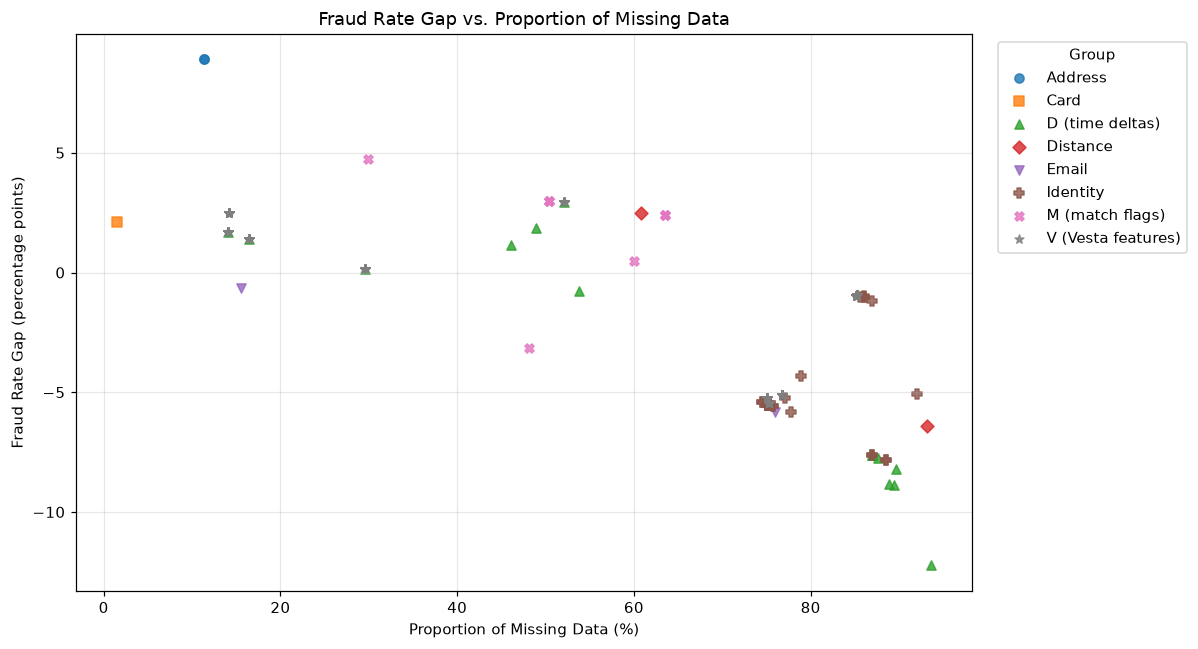

In [23]:
import numpy as np
import matplotlib.pyplot as plt

profile = tables["missingness"]
selected = profile.loc[profile["pct_missing"].between(1, 99)]

groups_copy = groups.copy()
groups_copy.name = "group"
groups_copy.index.name = "column"
selected_w_group = selected.join(groups_copy, on="column", how="left")

fig, ax = plt.subplots(figsize=(11, 6))
rng = np.random.default_rng(0) # Jitter to prevent overlap

markers = ["o", "s", "^", "D", "v", "P", "X", "*"]
for idx, (group, data) in enumerate(selected_w_group.groupby("group", dropna=False)):
    ax.scatter(
        data["pct_missing"], data["rate_gap_pp"],
        label=str(group), alpha=0.8, marker=markers[idx]
    )

ax.set(
    title="Fraud Rate Gap vs. Proportion of Missing Data",
    xlabel="Proportion of Missing Data (%)",
    ylabel="Fraud Rate Gap (percentage points)",
)
ax.legend(title="Group", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
save(fig, "fraud_rate_gap")

The chart below ranks the same comparison differently: the ten largest **absolute** gaps in fraud rate (missing
minus present, in percentage points) among columns with at least 1% of rows on each side, without keeping one
column per block, so columns that go missing together can appear side by side. The full per-column profile for all
436 columns (dtype, % missing, distinct values, fraud rate when missing and present) is in
`reports/eda/missingness.csv` and `reports/data_profile.md`.

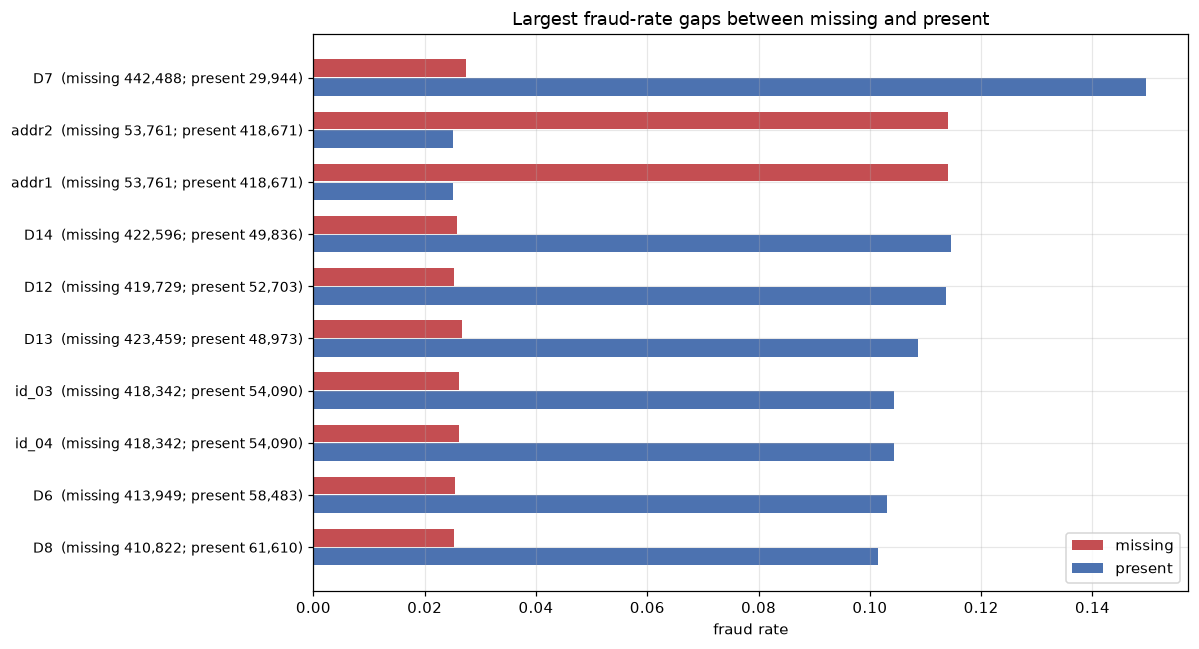

In [24]:
profile = tables["missingness"]
selected = profile.loc[profile["pct_missing"].between(1, 99)]
selected = selected.loc[selected["rate_gap_pp"].abs().sort_values(ascending=False).head(10).index]
fig, ax = plt.subplots(figsize=(11, 6))
y = np.arange(len(selected))
ax.barh(y - 0.18, selected["fraud_rate_missing"], height=0.34, label="missing", color=RED)
ax.barh(y + 0.18, selected["fraud_rate_present"], height=0.34, label="present", color=BLUE)
ax.set_yticks(y, [f"{r.column}  (missing {r.missing_rows:,}; present {r.present_rows:,})" for r in selected.itertuples()],
              fontsize=9)
ax.invert_yaxis(); ax.set_xlabel("fraud rate"); ax.legend(loc="lower right")
ax.set_title("Largest fraud-rate gaps between missing and present")
fig.tight_layout(); save(fig, "missingness_rates")

**Identity record by product.** Identity records are concentrated in some products, so `has_identity` and `ProductCD` partly measure the same thing. Look at fraud rates within each cell, not only overall.

In [25]:
cell = tr.groupby(["ProductCD", "has_identity"], observed=True)["isFraud"].agg(n="size", rate="mean")
cell.unstack("has_identity")

n               rate          
has_identity         0        1         0         1
ProductCD                                          
C               5711.0  50699.0  0.058484  0.119470
H                101.0  29590.0  0.029703  0.046435
R                129.0  32074.0  0.023256  0.036353
S                 26.0   8101.0  0.038462  0.061968
W             346001.0      NaN  0.020691       NaN

## 4. Fraud over time

Is the fraud rate stable across the six months, or does it drift? Drift is one reason a time-based validation score
can be lower than a training score. Weeks start at the first training day; a grey week has fewer than seven
observed days, so its volume isn't comparable. Relative days don't identify calendar dates or weekdays.

`TransactionDT` is seconds from an unknown start, so hour 0 further below is not midnight. The *shape* of the daily
cycle is still meaningful.

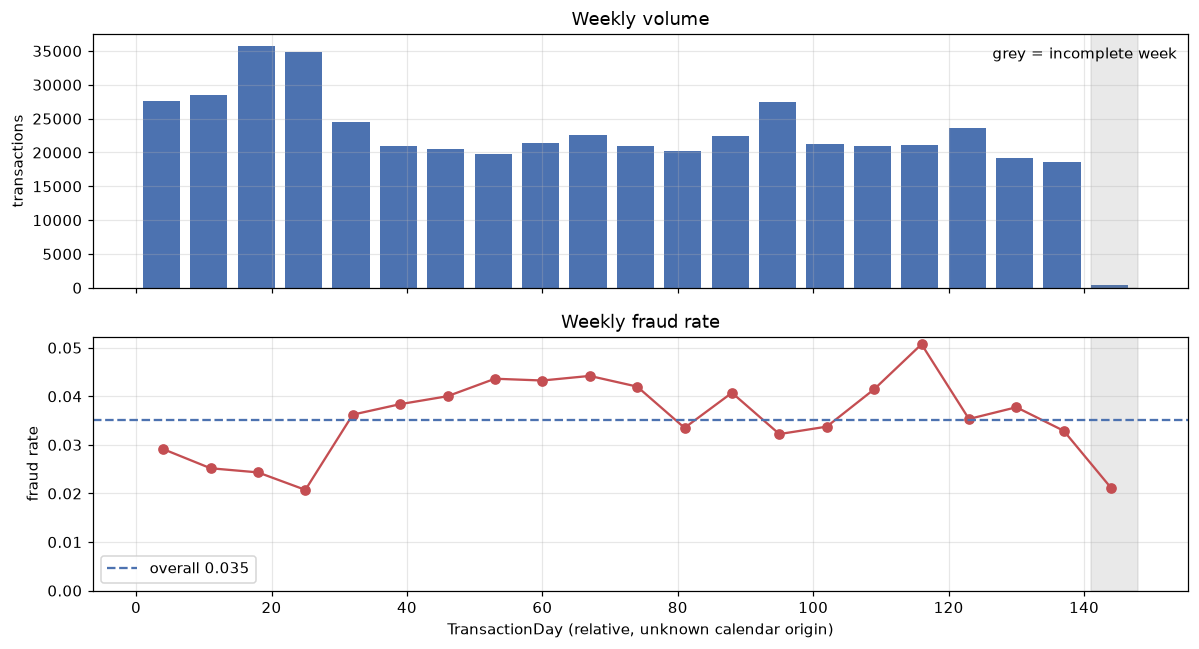

complete weeks: fraud rate from 2.1% (days 22-28) to 5.1% (days 113-119)


,days 1-30,days 31-60,days 61-90,days 91-120,days 121-141
n,134339.0000,89399.00,92189.0000,98615.0000,57890.0000
rate,0.0253,0.04,0.0404,0.0395,0.0345


In [26]:
weekly = tables["weekly"]
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
x = weekly["start_day"].to_numpy()
axes[0].bar(x, weekly["rows"], width=5.5, align="edge", color=BLUE)
axes[0].set_ylabel("transactions"); axes[0].set_title("Weekly volume")
axes[1].plot(x + 3, weekly["fraud_rate"], marker="o", color=RED)
axes[1].axhline(OVERALL, ls="--", color=BLUE, label=f"overall {OVERALL:.3f}")
axes[1].set_ylabel("fraud rate"); axes[1].set_xlabel("TransactionDay (relative, unknown calendar origin)")
axes[1].set_ylim(bottom=0); axes[1].legend(loc="lower left"); axes[1].set_title("Weekly fraud rate")
for ax in axes:
    for row in weekly.loc[~weekly["complete_interval"]].itertuples():
        ax.axvspan(row.start_day, row.end_day + 1, color="grey", alpha=0.17)
axes[0].text(0.99, 0.95, "grey = incomplete week", transform=axes[0].transAxes, ha="right", va="top")
fig.tight_layout(); save(fig, "time")

complete = weekly[weekly["complete_interval"]]
lo, hi = complete.loc[complete["fraud_rate"].idxmin()], complete.loc[complete["fraud_rate"].idxmax()]
print(f"complete weeks: fraud rate from {lo.fraud_rate:.1%} (days {lo.start_day}-{lo.end_day}) "
      f"to {hi.fraud_rate:.1%} (days {hi.start_day}-{hi.end_day})")

# 30-day blocks, the same bins as the time-based CV folds in src/split.py
first = tr["TransactionDay"].min()
block = (tr["TransactionDay"] - first) // 30
t30 = tr.groupby(block)["isFraud"].agg(n="size", rate="mean")
t30.index = [f"days {first + 30 * b}-{min(first + 30 * b + 29, tr.TransactionDay.max())}" for b in t30.index]
t30.round(4).T

**What this shows.** The fraud rate drifts: 2.5% in days 1–30, about 4.0% in each of the next three 30-day
blocks, and 3.5% in days 121–141. Over complete weeks it ranges from 2.1% (days 22–28) to 5.1% (days 113–119).
Volume is highest in the first month. Part of this can be a change in transaction mix rather than in fraud
behaviour, but either way a model fitted on earlier months sees a different base rate later.

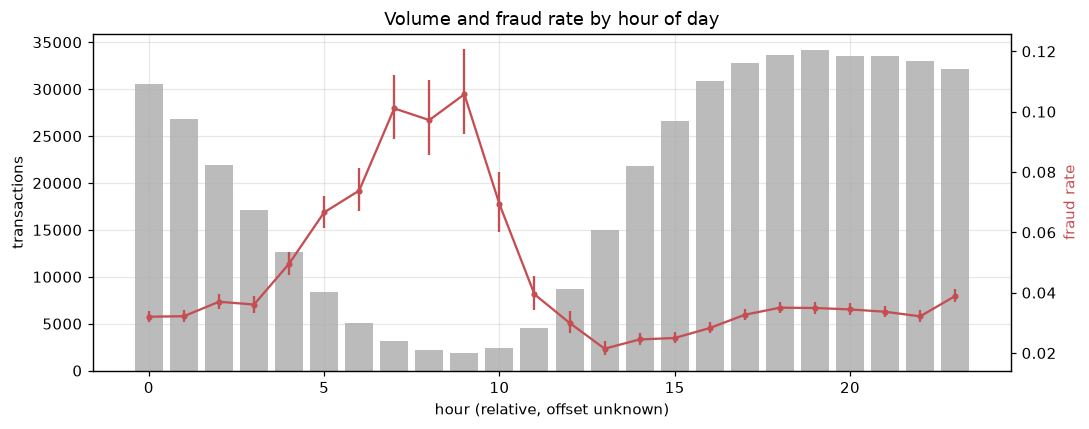

In [27]:
hour = (tr["TransactionDT"] % 86400) // 3600
h = rate_table(tr, hour).sort_index()

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(h.index, h["n"], color="#BBBBBB", label="volume")
ax1.set_xlabel("hour (relative, offset unknown)"); ax1.set_ylabel("transactions")
ax2 = ax1.twinx()
ax2.errorbar(h.index, h["rate"], yerr=[h["rate"] - h["lo"], h["hi"] - h["rate"]], color="#C44E52", marker="o", ms=3)
ax2.set_ylabel("fraud rate", color="#C44E52"); ax2.grid(False)
ax1.set_title("Volume and fraud rate by hour of day")
fig.tight_layout(); plt.show()

The hourly fraud rates in numbers:

In [28]:
h[["n", "rate"]].round(4).T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
n,30557.000,26772.0000,21923.000,17102.0000,12603.0000,8392.0000,5065.0000,3156.0000,2181.0000,1844.0000,2450.0000,4536.0000,8733.00,14977.0000,21796.0000,26616.000,30829.0000,32774.0000,33654.000,34155.0000,33543.0000,33583.0000,33051.0000,32140.0000
rate,0.032,0.0322,0.037,0.0361,0.0496,0.0666,0.0738,0.1011,0.0972,0.1057,0.0694,0.0395,0.03,0.0214,0.0245,0.025,0.0283,0.0327,0.035,0.0349,0.0345,0.0337,0.0322,0.0389


**What this shows.** Fraud depends strongly on the (relative) hour. The quiet hours 6 to 10, with the fewest
transactions, have 6.9% to 10.6% fraud, against 2.1% to 3.9% for the busy hours 13 to 3. Hour of day is a clear
signal even though its offset is unknown.

## 5. Customer structure

Vesta labels fraud at the customer level: once a chargeback is reported, later transactions linked to the same
account, email or billing address are often labelled fraud too. If fraud clusters strongly within a customer,
that shapes both the features (a customer's history matters) and the validation design (random K-fold would put
the same customer on both sides of a split and inflate scores).

The data has no customer ID, so this section first compares ways of building one (5.1), then picks one and
measures how strongly fraud clusters within it (5.2).

### 5.1 Comparing customer keys

Vesta doesn't give a customer ID, so one has to be built from the columns available. Here we compare candidate
keys made from `card1`, `addr1`, the account start and the purchaser email domain, from coarse to strict. The
account start is `TransactionDay − D1`: D1 appears to count days since a card or account event, so the
difference should stay the same for one customer (7.1 and 7.2 look at this more closely). A useful customer key should:

- **group one customer's transactions together**, so a group's labels are consistent: if the previous transaction
  in the group was fraud, this one usually is too (label persistence), and groups with any fraud are mostly fraud
  (purity);
- **not split a customer into many pieces**, so most rows still have earlier history in their group. A key that
  is too strict makes every group pure trivially, because single-row groups are always pure, but leaves no
  history to learn from.

Purity is measured only on groups with at least two rows, so single-row groups don't inflate it.

In [29]:
def key_of(*parts):
    """Join columns into one text key; a missing value becomes its own placeholder."""
    out = None
    for s in parts:
        s = s.astype(object).fillna("?").astype(str)
        out = s if out is None else out + "_" + s
    return out

def key_parts(f):
    start = (f["TransactionDay"] - f["D1"]).round()
    return {"card1": f["card1"], "addr1": f["addr1"], "start": start, "email": f["P_emaildomain"]}

candidates = {
    "card1": ["card1"],
    "card1 + addr1": ["card1", "addr1"],
    "card1 + start": ["card1", "start"],
    "card1 + addr1 + start": ["card1", "addr1", "start"],
    "card1 + addr1 + start + email": ["card1", "addr1", "start", "email"],
}
p_tr, p_va = key_parts(tr), key_parts(va)
rows = {}
for name, cols in candidates.items():
    k_tr = key_of(*[p_tr[c] for c in cols])
    k_va = key_of(*[p_va[c] for c in cols])
    g = tr.groupby(k_tr)["isFraud"].agg(n="size", fraud="sum")
    multi = g[(g["n"] >= 2) & (g["fraud"] > 0)]
    prev = tr["isFraud"].groupby(k_tr).shift(1)
    rows[name] = {
        "groups": len(g),
        "rows with earlier history in group": prev.notna().mean(),
        "P(fraud | previous fraud)": tr["isFraud"][prev == 1].mean(),
        "P(fraud | previous not fraud)": tr["isFraud"][prev == 0].mean(),
        "purity: median fraud share (groups ≥2 rows with fraud)": (multi["fraud"] / multi["n"]).median(),
        "fraud rows in all-fraud groups ≥2 rows (share)":
            multi.loc[multi["fraud"] == multi["n"], "fraud"].sum() / tr["isFraud"].sum(),
        "val rows whose key appears in train": k_va.isin(set(k_tr)).mean(),
    }
key_compare = pd.DataFrame(rows).T
key_compare.round(3)

/var/folders/14/9z1c81gx4nz56mqrm1tnqwy80000gn/T/ipykernel_9554/3836921269.py:5: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  s = s.astype(object).fillna("?").astype(str)
/var/folders/14/9z1c81gx4nz56mqrm1tnqwy80000gn/T/ipykernel_9554/3836921269.py:5: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  s = s.astype(object).fillna("?").astype(str)
/var/folders/14/9z1c81gx4nz56mqrm1tnqwy80000gn/T/ipykernel_9554/3836921269.py:5: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call resul

,groups,rows with earlier history in group,P(fraud | previous fraud),P(fraud | previous not fraud),purity: median fraud share (groups ≥2 rows with fraud),fraud rows in all-fraud groups ≥2 rows (share),val rows whose key appears in train
card1,12730.0,0.973,0.386,0.023,0.083,0.010,0.990
card1 + addr1,36593.0,0.923,0.470,0.020,0.125,0.044,0.960
card1 + start,125908.0,0.733,0.663,0.013,0.350,0.287,0.500
card1 + addr1 + start,182535.0,0.614,0.768,0.010,0.556,0.438,0.486
card1 + addr1 + start + email,229158.0,0.515,0.852,0.007,1.000,0.521,0.445


**Findings.** Each column added to the key trades history for consistency:

| Key | Rows with earlier history | P(fraud \| previous fraud) | Purity (groups ≥2 rows) | Val rows seen in train |
| --- | --- | --- | --- | --- |
| card1 | 97.3% | 38.6% | 0.08 | 99.0% |
| card1 + addr1 | 92.3% | 47.0% | 0.13 | 96.0% |
| card1 + start | 73.3% | 66.3% | 0.35 | 50.0% |
| card1 + addr1 + start | 61.4% | 76.8% | 0.56 | 48.6% |
| card1 + addr1 + start + email | 51.5% | 85.2% | 1.00 | 44.5% |

- **The account start adds the most.** Adding it to card1 raises label persistence from 38.6% to 66.3% and purity
  from 0.08 to 0.35. card1 and addr1 alone mix many customers.
- **addr1 on top adds a further clear step** (66.3% → 76.8%, purity 0.35 → 0.56) for about 12 points less
  history.
- **Email makes groups purer still** (85.2%, purity 1.00) but leaves only half the rows with any history and
  44.5% of validation rows with a known customer.

`card1 + addr1 + start` keeps most of the consistency of the strictest key while leaving more rows with history.
The email version is stricter, with less history.

### 5.2 Fraud clustering under the chosen customer key

Based on 5.1, we use `card1 + addr1 + account start` as the customer key and call it **`uid`** from here on. A
missing `card1`, `addr1` or account start becomes its own placeholder value, so those rows keep a key.

Below, `uid` is compared with `card1` alone to show how strongly fraud clusters within a customer.

In [30]:
def make_uid(f):
    start = (f["TransactionDay"] - f["D1"]).round()
    return (f["card1"].fillna(-1).astype("int64").astype(str) + "_"
            + f["addr1"].fillna(-1).astype("int64").astype(str) + "_"
            + start.fillna(-9999).astype("int64").astype(str))

tr["uid"] = make_uid(tr)
va["uid"] = make_uid(va)

def cluster_stats(key):
    g = tr.groupby(key, observed=True)["isFraud"].agg(n="size", fraud="sum")
    g["share"] = g["fraud"] / g["n"]
    with_fraud = g[g["fraud"] > 0]
    fraud_rows = tr["isFraud"].sum()
    return pd.Series({
        "groups": len(g),
        "median rows per group": g["n"].median(),
        "share of groups with only 1 row": (g["n"] == 1).mean(),
        "groups with any fraud": len(with_fraud),
        "groups with mixed labels": ((g["fraud"] > 0) & (g["fraud"] < g["n"])).sum(),
        "fraud rows in all-fraud groups (share)": with_fraud.loc[with_fraud["share"] == 1, "fraud"].sum() / fraud_rows,
        "median fraud share in groups with any fraud": with_fraud["share"].median(),
    }), g

s_card, g_card = cluster_stats("card1")
s_uid, g_uid = cluster_stats("uid")
pd.DataFrame({"card1": s_card, "uid": s_uid})

,card1,uid
groups,12730.000000,182535.000000
median rows per group,4.000000,1.000000
share of groups with only 1 row,0.265515,0.581593
groups with any fraud,1532.000000,6610.000000
groups with mixed labels,1350.000000,2516.000000
fraud rows in all-fraud groups (share),0.017893,0.587987
median fraud share in groups with any fraud,0.100000,1.000000


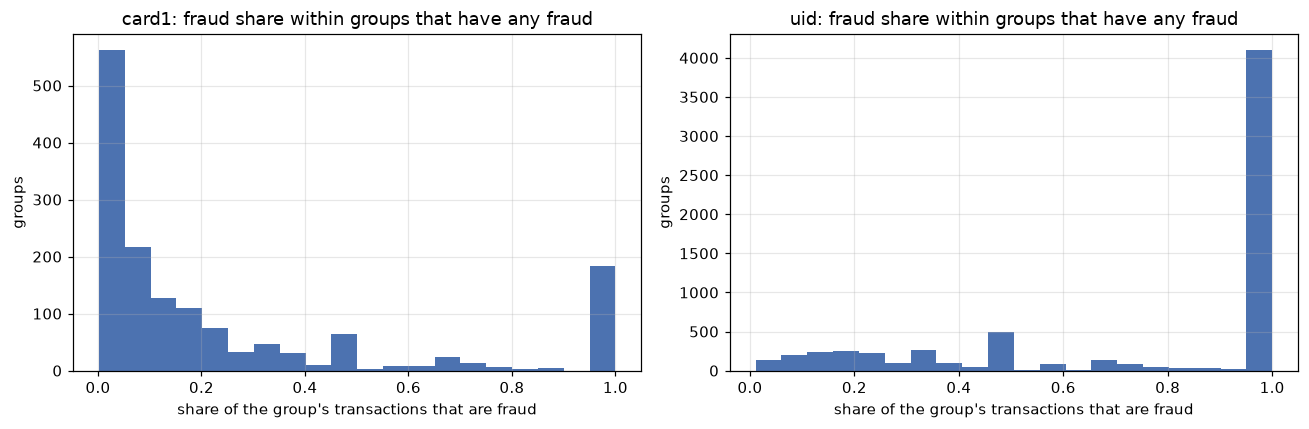

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, g, name in [(axes[0], g_card, "card1"), (axes[1], g_uid, "uid")]:
    ax.hist(g.loc[g["fraud"] > 0, "share"], bins=20, color="#4C72B0")
    ax.set_title(f"{name}: fraud share within groups that have any fraud")
    ax.set_xlabel("share of the group's transactions that are fraud"); ax.set_ylabel("groups")
fig.tight_layout(); plt.show()

**Label persistence.** How likely is a transaction to be fraud given that the same uid's previous transaction was fraud? A large gap versus the overall rate is consistent with customer-level labelling.

Caution for modelling: using past *labels* as a feature assumes the label is known at prediction time. Chargebacks arrive with a delay of days to weeks, so a feature like "previous transaction was fraud" would be unrealistically strong. Use this only as EDA evidence.

In [32]:
prev = tr.groupby("uid")["isFraud"].shift(1)
rate_table(tr, prev.map({0.0: "previous not fraud", 1.0: "previous fraud"}))

,n,fraud,rate,lo,hi
previous not fraud,278322,2791,0.010028,0.009664,0.010405
(missing),182535,4919,0.026948,0.026215,0.027701
previous fraud,11575,8889,0.767948,0.760170,0.775549


**Overlap with later data.** How many validation rows belong to a customer already seen in the training block? Labels are not used here.

In [33]:
overlap = pd.Series({
    "val rows whose card1 appears in train": va["card1"].isin(set(tr["card1"])).mean(),
    "val rows whose uid appears in train": va["uid"].isin(set(tr["uid"])).mean(),
})
overlap.map("{:.1%}".format)

val rows whose card1 appears in train    99.0%
val rows whose uid appears in train      48.6%
dtype: object

## 6. Categorical features vs fraud

Bars show the fraud rate with a 95% interval, and each label shows the row count; `(missing)` is its own group.
Wide intervals mean the rate is noise. High-cardinality columns show their 15 most frequent values only; rare values
are candidates for a shared "other" group. All rates are unadjusted for other columns and time, and email domain
rates say nothing about the providers themselves.

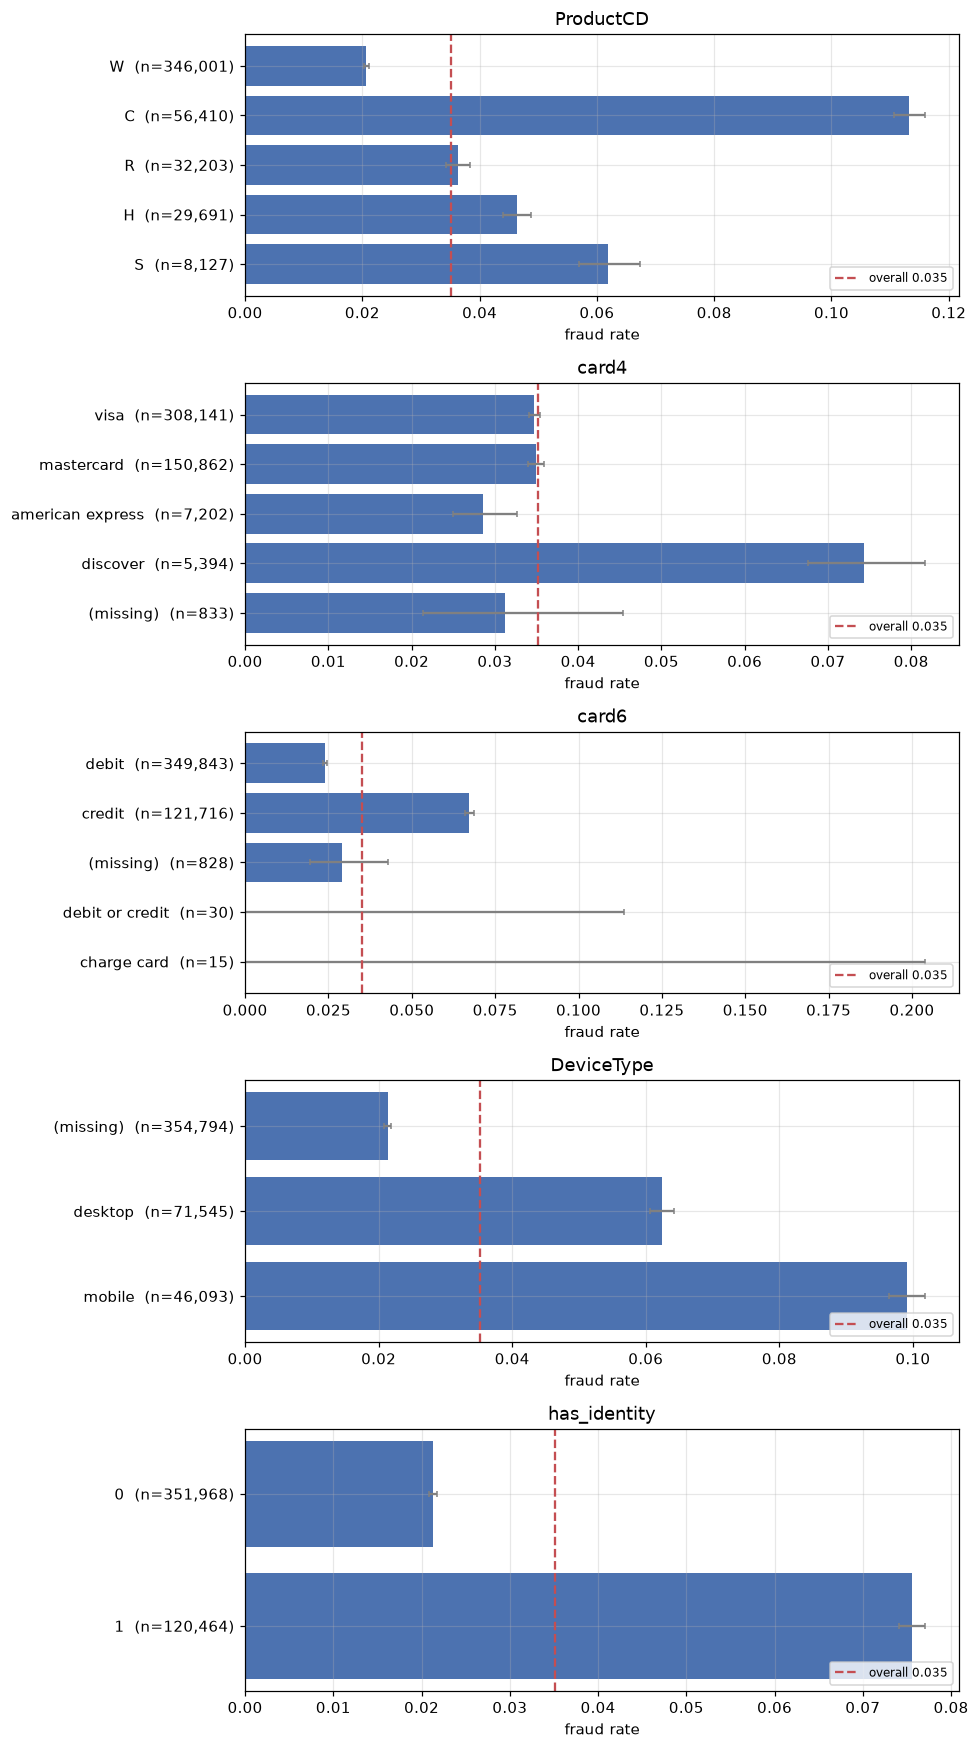

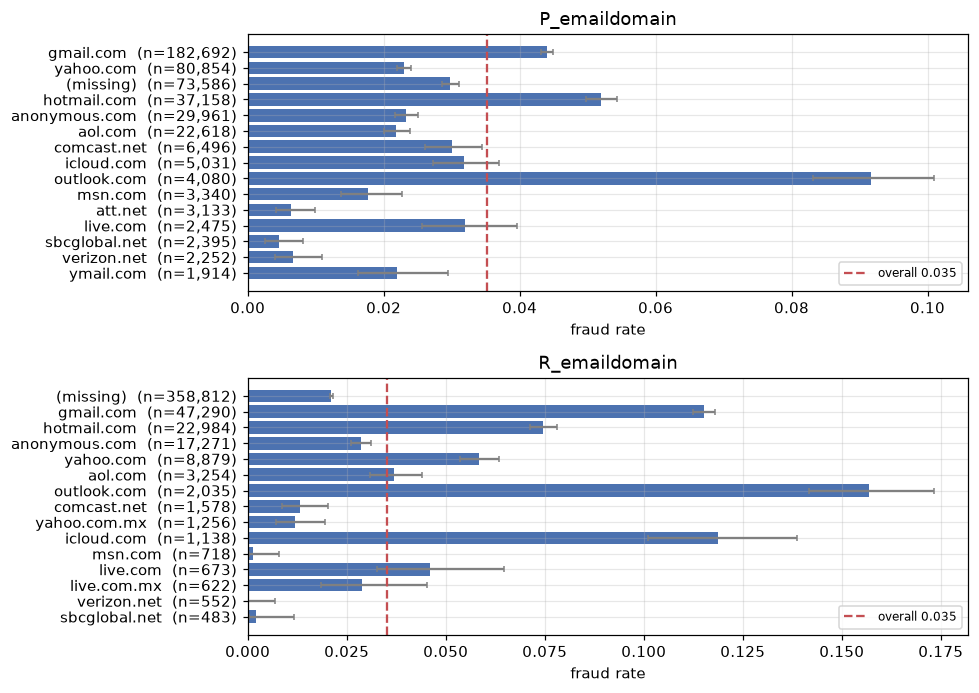

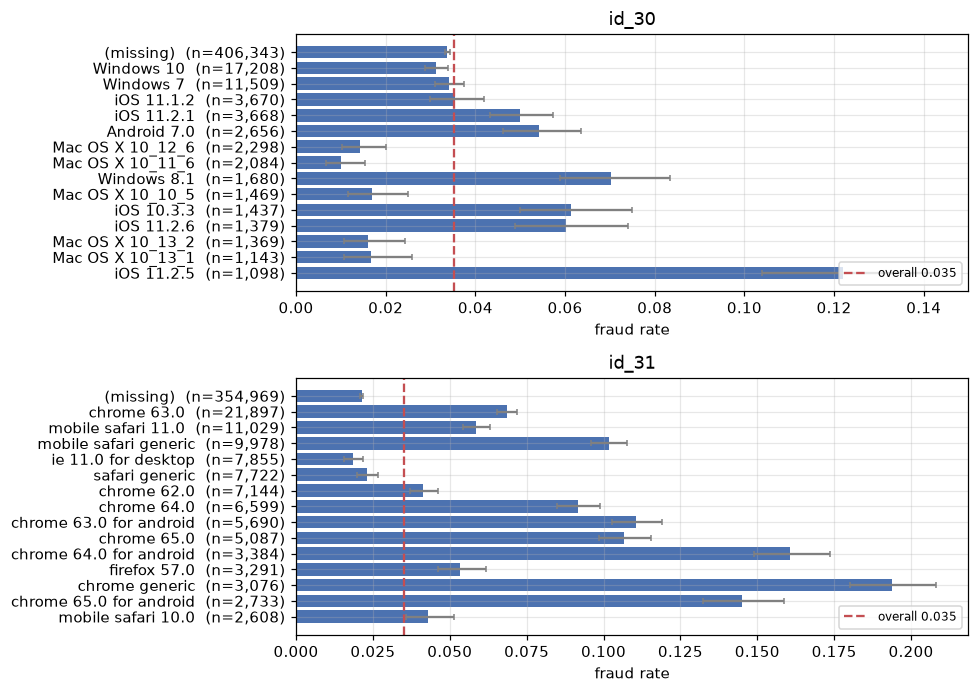

In [34]:
def rate_panels(specs, name=None):
    fig, axes = plt.subplots(len(specs), 1, figsize=(9, 3.2 * len(specs)))
    for ax, (col, top) in zip(np.atleast_1d(axes), specs):
        plot_rate(rate_table(tr, col, top=top), col, ax)
    fig.tight_layout()
    save(fig, name) if name else plt.show()

rate_panels([("ProductCD", None), ("card4", None), ("card6", None), ("DeviceType", None), ("has_identity", None)],
            "categories")
rate_panels([("P_emaildomain", 15), ("R_emaildomain", 15)], "email_domains")
rate_panels([("id_30", 15), ("id_31", 15)])

In [35]:
# Match flags M1-M9 in one table: fraud rate for T, F and missing
m_cols = [f"M{i}" for i in range(1, 10) if f"M{i}" in tr.columns]
m_tab = pd.concat({c: rate_table(tr, c)["rate"] for c in m_cols}, axis=1).T
m_tab.style.format("{:.3f}").background_gradient(axis=None, cmap="Reds")

,(missing),T,F,M0,M2,M1
M1,0.050,0.020,0.000,nan,nan,nan
M2,0.050,0.018,0.035,nan,nan,nan
M3,0.050,0.017,0.031,nan,nan,nan
M4,0.019,nan,nan,0.038,0.111,0.027
M5,0.037,0.039,0.027,nan,nan,nan
M6,0.068,0.017,0.024,nan,nan,nan
M7,0.044,0.024,0.019,nan,nan,nan
M8,0.044,0.017,0.022,nan,nan,nan
M9,0.044,0.018,0.031,nan,nan,nan


In [36]:
# Does the purchaser email domain match the recipient domain?
both = tr["P_emaildomain"].notna() & tr["R_emaildomain"].notna()
match = np.where(~both, "one or both missing",
                 np.where(tr["P_emaildomain"].astype(object) == tr["R_emaildomain"].astype(object), "same domain", "different domain"))
rate_table(tr, pd.Series(match, index=tr.index))

,n,fraud,rate,lo,hi
one or both missing,366463,8059,0.021991,0.021521,0.022471
same domain,85848,7973,0.092873,0.090950,0.094833
different domain,20121,567,0.028180,0.025981,0.030558


The category charts above in numbers (fraud rate and rows), plus selected purchaser email domains:

In [37]:
cat_rates = pd.concat({c: rate_table(tr, c)[["n", "rate"]] for c in ["ProductCD", "card4", "card6", "DeviceType", "has_identity"]})
display(cat_rates.round(4).T)
value_rates("P_emaildomain", ["gmail.com", "yahoo.com", "hotmail.com", "outlook.com", "sbcglobal.net", "att.net"]).round(4)

ProductCD                                                       card4                                                     \
                W           C           R           H          S         visa   mastercard american express   discover (missing)   
n     346001.0000  56410.0000  32203.0000  29691.0000  8127.0000  308141.0000  150862.0000        7202.0000  5394.0000  833.0000   
rate       0.0207      0.1133      0.0363      0.0464     0.0619       0.0347       0.0349           0.0286     0.0743    0.0312   

           card6                                                      DeviceType                        has_identity               
           debit       credit (missing) debit or credit charge card    (missing)     desktop     mobile            0            1  
n     349843.000  121716.0000   828.000            30.0        15.0  354794.0000  71545.0000  46093.000  351968.0000  120464.0000  
rate       0.024       0.0673     0.029             0.0         0.0       0.0213      0.0624      0.099       0.0213       0.0755

,n,fraud,rate,lo,hi,share of all fraud
gmail.com,182692,8039,0.0440,0.0431,0.0450,0.4843
yahoo.com,80854,1854,0.0229,0.0219,0.0240,0.1117
hotmail.com,37158,1933,0.0520,0.0498,0.0543,0.1165
outlook.com,4080,374,0.0917,0.0832,0.1009,0.0225
sbcglobal.net,2395,11,0.0046,0.0026,0.0082,0.0007
att.net,3133,20,0.0064,0.0041,0.0098,0.0012


**What this shows.**

- **Product:** C has 11.3% fraud and W 2.1%; S, H and R are in between (6.2%, 4.6%, 3.6%).
- **Card:** credit 6.7% vs debit 2.4%. By network, Discover has 7.4% against about 3.5% for Visa and Mastercard
  and 2.9% for American Express.
- **Device and identity:** mobile 9.9%, desktop 6.2%, no device record 2.1%; with an identity record 7.6% vs 2.1%
  without.
- **Purchaser email:** outlook.com 9.2% and hotmail.com 5.2%, against 2.3% for yahoo.com and under 0.7% for
  sbcglobal.net and att.net. Same purchaser and recipient domain: 9.3% vs 2.8% for different domains.

### 6.1 Identity columns: what do they add beyond having an identity record?

The 38 `id_` columns are only filled when a transaction has an identity record (about a quarter of rows), and rows
with an identity record have much more fraud. So comparing "present vs missing" over all rows mostly measures
`has_identity` again. The real question is whether each column's **values** separate fraud from non-fraud **among
rows that have an identity record**.

For each column, within identity rows only:

- **missing in id rows:** how often the column is still empty when an identity record exists.
- **fraud if present / missing:** fraud rate within identity rows when the column is filled or empty.
- **spread:** the gap between the highest and lowest fraud rate across the column's values (numeric columns are
  split into five equal-sized groups). Only groups with at least 200 rows count. A spread near zero means the
  column adds nothing beyond `has_identity`.

In [38]:
idr = tr[tr["has_identity"] == 1]
id_base = idr["isFraud"].mean()
print(f"identity rows: {len(idr):,} ({len(idr) / len(tr):.1%} of the training block), fraud rate {id_base:.4f}")

rows = []
for c in [c for c in tr.columns if c.startswith("id_")]:
    s = idr[c]
    miss = s.isna()
    if pd.api.types.is_numeric_dtype(s) and s.nunique() > 10:
        grp = pd.qcut(s, 5, duplicates="drop").astype(str).where(s.notna(), "(missing)")
    else:
        grp = s.astype(object).where(s.notna(), "(missing)")
    t = rate_table(idr, grp, min_n=200)
    rows.append({
        "column": c,
        "missing overall": tr[c].isna().mean(),
        "missing in id rows": miss.mean(),
        "fraud if present": idr.loc[~miss, "isFraud"].mean() if (~miss).any() else np.nan,
        "fraud if missing": idr.loc[miss, "isFraud"].mean() if miss.sum() >= 200 else np.nan,
        "n groups": len(t),
        "spread": t["rate"].max() - t["rate"].min() if len(t) > 1 else np.nan,
        "riskiest group": f"{t['rate'].idxmax()} ({t['rate'].max():.3f})" if len(t) > 1 else "-",
        "safest group": f"{t['rate'].idxmin()} ({t['rate'].min():.3f})" if len(t) > 1 else "-",
    })
id_check = pd.DataFrame(rows).set_index("column").sort_values("spread", ascending=False)
with pd.option_context("display.max_rows", 50, "display.max_colwidth", 40):
    display(id_check.round(3))

identity rows: 120,464 (25.5% of the training block), fraud rate 0.0755


,missing overall,missing in id rows,fraud if present,fraud if missing,n groups,spread,riskiest group,safest group
column,,,,,,,,
id_33,0.869,0.487,0.045,0.107,28,0.386,855x480 (0.386),2736x1824 (0.000)
id_30,0.860,0.451,0.044,0.114,37,0.309,Android 5.1.1 (0.309),Mac (0.000)
id_31,0.751,0.025,0.077,0.028,41,0.256,android webview 4.0 (0.258),ie 11.0 for tablet (0.002)
id_03,0.886,0.551,0.104,0.052,3,0.164,"(0.0, 10.0] (0.216)",(missing) (0.052)
id_09,0.870,0.489,0.101,0.048,3,0.122,"(0.0, 25.0] (0.171)",(missing) (0.048)
id_14,0.856,0.434,0.044,0.117,5,0.117,"(-300.0, 720.0] (0.146)","(-660.001, -420.0] (0.029)"
id_22,0.991,0.965,0.078,0.075,3,0.107,"(14.0, 44.0] (0.177)","(9.999, 14.0] (0.069)"
id_17,0.753,0.031,0.076,0.048,4,0.099,"(191.0, 225.0] (0.127)","(166.0, 191.0] (0.028)"
id_35,0.751,0.022,0.077,0.024,3,0.095,F (0.119),(missing) (0.024)


**What this shows** (identity rows only, base fraud rate 7.6%):

- **Device, OS and browser carry the most signal.** `id_33` (screen), `id_30` (OS) and `id_31` (browser) have
  the largest spreads: 0.39, 0.31 and 0.26. Some screens, OS versions and browsers have almost no fraud
  (e.g. Mac 0.0%); others are far above the base rate (Android 5.1.1 30.9%). These columns have many values, so
  some of the spread comes from small groups. Grouping them (OS family, browser name) keeps the signal while
  being less noisy.
- **One block of columns is often empty even inside identity rows,** and that gap is itself a signal. `id_30`,
  `id_32`, `id_33`, `id_34` and `id_14` are missing in about 45% of identity rows. When they are missing, fraud is
  10.7 to 11.7%, against 4.4 to 4.5% when filled. This is the same "device type known but OS missing" red flag as 9.7.
  `id_03`, `id_04`, `id_09` and `id_10` go the other way: fraud is about 10% when filled vs 5% when missing.
- **The core flags add a little.** `id_15`, `id_28`, `id_29` and `id_35` to `id_38` are filled in 98% of identity
  rows. Most of their spread comes from the rare missing case (about 2.4% fraud). `id_15` = Found has 10.2% vs
  the base rate.
- **The 99%-missing columns** (`id_07`, `id_08`, `id_21` to `id_27`) are still empty in 96.5% of identity rows, so
  they cover only about 4,000 transactions. A few show something on those rows (`id_23` IP_PROXY:ANONYMOUS
  12.0% vs IP_PROXY:HIDDEN 5.5%), but they can't matter much overall.
- **Close to nothing:** `id_12` (spread 0.014) and `id_27` (0.003).

**Provisional decision:** drop `id_12` and `id_27`. Keep the block-missing pattern and the numeric id columns. The
device, OS, browser and screen columns look useful here, but this is over the whole training block; section 11.1
checks whether their link to fraud holds over time, and section 13 makes the final call (the OS and screen values
turn out not to). The 99%-missing columns cover too few rows to matter much either way; section 13 keeps them.

### 6.2 Grouped and combined categories

Four checks on categories that could be grouped or combined:

- the **recipient** email domain grouped by provider (the purchaser side is in section 6);
- card network and card type **together**, since section 6 shows them separately;
- **how many** of the T/F match flags (M1–M3, M5–M9) are true, false or missing in a row;
- whether `addr2` and `card3` take their **most common value**, since one value covers most rows.

In [39]:
providers = {"google": ["gmail"], "yahoo": ["yahoo", "ymail", "rocketmail"],
             "microsoft": ["hotmail", "outlook", "live", "msn"], "apple": ["icloud", "me.com", "mac.com"],
             "aol": ["aol", "aim.com"], "anonymous": ["anonymous", "protonmail"]}
def provider(d):
    if pd.isna(d):
        return np.nan
    d = str(d).lower()
    return next((p for p, keys in providers.items() if any(d.startswith(k) for k in keys)), "other")
r_prov = tr["R_emaildomain"].astype(object).map(provider)
print("Recipient email provider"); display(rate_table(tr, r_prov).round(4))

combo = tr["card4"].astype(object).fillna("?") + " " + tr["card6"].astype(object).fillna("?")
print("Card network and type"); display(rate_table(tr, combo, min_n=500).round(4))

m_tf = tr[["M1", "M2", "M3", "M5", "M6", "M7", "M8", "M9"]].astype(object)
m_counts = pd.concat({k: rate_table(tr, s)[["n", "rate"]].sort_index() for k, s in
                      [("true", (m_tf == "T").sum(axis=1)), ("false", (m_tf == "F").sum(axis=1)),
                       ("missing", m_tf.isna().sum(axis=1))]}, axis=1)
print("Number of M flags (of 8) that are true / false / missing"); display(m_counts.round(4))

for col in ["addr2", "card3"]:
    mode = tr[col].mode().iloc[0]
    s = np.select([tr[col].isna(), tr[col] == mode], ["(missing)", f"most common ({mode:g})"], "any other value")
    print(f"{col}: most common value vs the rest"); display(rate_table(tr, pd.Series(s, index=tr.index)).round(4))

Recipient email provider


,n,fraud,rate,lo,hi
(missing),358812,7586,0.0211,0.0207,0.0216
google,47370,5446,0.1150,0.1121,0.1179
microsoft,28002,2147,0.0767,0.0736,0.0798
anonymous,17311,531,0.0307,0.0282,0.0333
yahoo,10622,548,0.0516,0.0475,0.0560
other,5231,84,0.0161,0.0130,0.0198
aol,3284,121,0.0368,0.0309,0.0438
apple,1800,136,0.0756,0.0642,0.0887


Card network and type


,n,fraud,rate,lo,hi
visa debit,238826,6055,0.0254,0.0247,0.0260
mastercard debit,110604,2312,0.0209,0.0201,0.0218
visa credit,69303,4645,0.0670,0.0652,0.0689
mastercard credit,40228,2954,0.0734,0.0709,0.0760
american express credit,7077,202,0.0285,0.0249,0.0327
discover credit,5106,387,0.0758,0.0688,0.0834
? ?,823,24,0.0292,0.0197,0.0430


Number of M flags (of 8) that are true / false / missing


true             false         missing        
        n    rate         n    rate       n    rate
0  173903  0.0588  188674.0  0.0545   85639  0.0327
1   61124  0.0273  104776.0  0.0224   83198  0.0072
2   23759  0.0302   78519.0  0.0192    3181  0.0060
3   39899  0.0196   53469.0  0.0204   39128  0.0282
4   66211  0.0182   26050.0  0.0232   22492  0.0073
5   58989  0.0164   12522.0  0.0276     939  0.0096
6   32301  0.0182    6228.0  0.0369   57130  0.0363
7   13945  0.0253    2194.0  0.0925   50445  0.0065
8    2301  0.0404       NaN     NaN  130280  0.0730

addr2: most common value vs the rest


,n,fraud,rate,lo,hi
most common (87),414740,10063,0.0243,0.0238,0.0247
(missing),53761,6128,0.1140,0.1113,0.1167
any other value,3931,408,0.1038,0.0946,0.1137


card3: most common value vs the rest


,n,fraud,rate,lo,hi
most common (150),415837,10349,0.0249,0.0244,0.0254
any other value,55772,6226,0.1116,0.1090,0.1143
(missing),823,24,0.0292,0.0197,0.0430


**What this shows.**

- **Recipient provider:** a clear signal. Google 11.5%, Microsoft 7.7% and Apple 7.6%, against 3.1% for anonymous,
  1.6% for other providers and 2.1% when there is no recipient domain. Grouping by provider keeps this with 8 levels
  instead of 60 domains.
- **Card network and type together:** credit cards carry most of the risk (6.7% to 7.6% for Visa, Mastercard and
  Discover credit, against 2.1% to 2.5% for debit), but American Express credit has only 2.9%. So the combination
  separates fraud better than card type alone.
- **Counts of match flags:** all three counts separate fraud. No true flag at all has 5.9% fraud against 1.6% to 3.0%
  for one to seven; 7 false flags has 9.3% (2,194 rows). The missing count is not a steady scale but works like a code
  for which M flags are missing together: 0.6% to 0.7% for some counts, 7.3% when all 8 are missing.
- **Most common value:** for both columns, any other value is much riskier. `addr2` other than 87 has 10.4% fraud
  against 2.4% (3,931 rows); `card3` other than 150 has 11.2% against 2.5% (55,772 rows, 38% of all fraud).

## 7. Numeric features vs fraud

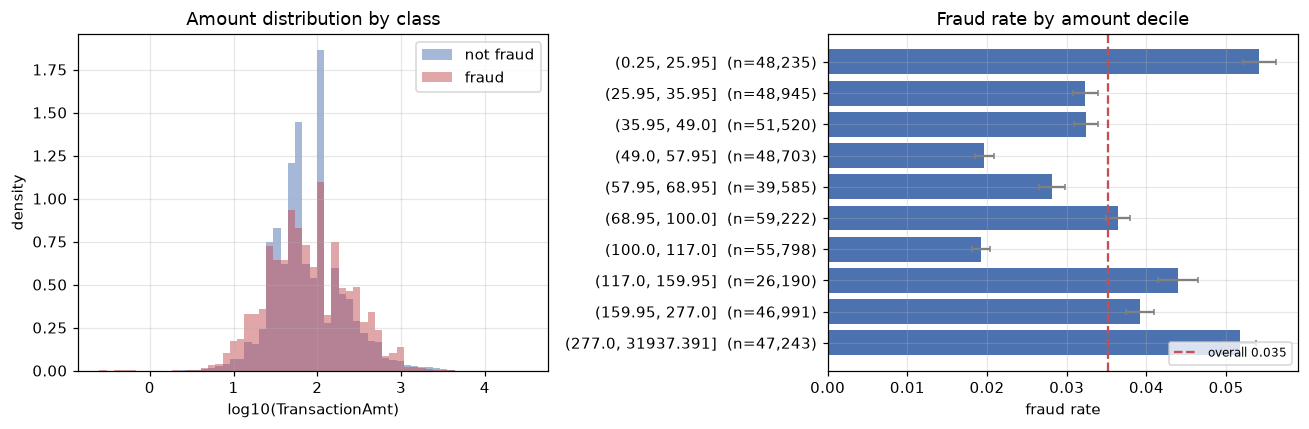

In [40]:
amt = tr["TransactionAmt"].astype("float64")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bins = np.linspace(np.log10(amt.min()), np.log10(amt.max()), 60)
for label, colr in [(0, "#4C72B0"), (1, "#C44E52")]:
    axes[0].hist(np.log10(amt[tr.isFraud == label]), bins=bins, density=True, alpha=0.5, color=colr,
                 label="fraud" if label else "not fraud")
axes[0].set_xlabel("log10(TransactionAmt)"); axes[0].set_ylabel("density"); axes[0].legend()
axes[0].set_title("Amount distribution by class")
plot_rate(rate_by_quantile(tr, amt, 10), "Fraud rate by amount decile", axes[1])
fig.tight_layout(); save(fig, "amounts")

Amount summary per class, and fraud rate in fixed amount bands (the bands used in `reports/eda_findings.md`):

In [41]:
display(tables["amount_summary"].set_index("isFraud").round(2))
bands = tables["amount_bins"].set_index("group")
bands.assign(rate=bands["fraud_rate"]).loc[:, ["rows", "rate"]].T.round(4)

,rows,mean,median,p95,p99,max
isFraud,,,,,,
0,455833,133.87,68.50,433.0,1104.0,31937.39
1,16599,149.04,76.13,500.0,994.0,5191.00


group,<10,10–<25,25–<50,50–<100,100–<250,250–<500,500–<1000,1000+
rows,5171.0000,29608.0000,114936.0000,128794.0000,140442.0000,34185.0000,13455.0000,5841.0000
rate,0.0777,0.0662,0.0311,0.0288,0.0299,0.0546,0.0559,0.0228


**Unusual decimals.** Amounts with more than two decimal places may come from currency conversion, which hints at a foreign purchase. (Values are stored as float32, so we compare against whole cents with a tolerance.)

In [42]:
cents = amt * 100
odd = (np.abs(cents - cents.round()) > 1e-2)
whole = (amt % 1 == 0)
kind = pd.Series(np.select([odd, whole], ["more than 2 decimals", "whole number"], "exact cents"), index=tr.index)
rate_table(tr, kind)

,n,fraud,rate,lo,hi
whole number,244682,8839,0.036124,0.035392,0.036871
exact cents,176653,1979,0.011203,0.010722,0.011704
more than 2 decimals,51097,5781,0.113138,0.110420,0.115913


**Specific amounts.** The decile chart hides what happens at individual price points. Below: the most common amounts (likely standard product prices), and the round amounts of \$100 or more that account for the most fraud. `share of all fraud` is that amount's fraud count divided by all fraud in the training block.

In [43]:
amt_key = amt.round(2)
common = amt_key.value_counts().head(10).index
round_big = amt_key[(amt_key >= 100) & (amt_key % 50 == 0)]
round_top = tr.loc[round_big.index].groupby(round_big)["isFraud"].sum().sort_values(ascending=False).head(10).index
left = value_rates(amt_key, list(common))
right = value_rates(amt_key, list(round_top))
print("Most common amounts"); display(left.round(4))
print("Round amounts >= $100 with the most fraud"); display(right.round(4))

Most common amounts


,n,fraud,rate,lo,hi,share of all fraud
59.00,23652,478,0.0202,0.0185,0.0221,0.0288
117.00,22453,578,0.0257,0.0238,0.0279,0.0348
107.95,18683,128,0.0069,0.0058,0.0081,0.0077
57.95,18368,68,0.0037,0.0029,0.0047,0.0041
100.00,17702,444,0.0251,0.0229,0.0275,0.0267
50.00,15042,301,0.0200,0.0179,0.0224,0.0181
49.00,12321,382,0.0310,0.0281,0.0342,0.0230
226.00,9099,307,0.0337,0.0302,0.0377,0.0185
39.00,8615,193,0.0224,0.0195,0.0257,0.0116
29.00,8322,179,0.0215,0.0186,0.0249,0.0108


Round amounts >= $100 with the most fraud


,n,fraud,rate,lo,hi,share of all fraud
150.0,7112,497,0.0699,0.0642,0.0760,0.0299
100.0,17702,444,0.0251,0.0229,0.0275,0.0267
200.0,5580,367,0.0658,0.0596,0.0726,0.0221
300.0,2116,305,0.1441,0.1298,0.1598,0.0184
250.0,2944,184,0.0625,0.0543,0.0718,0.0111
500.0,1233,111,0.0900,0.0753,0.1073,0.0067
450.0,259,87,0.3359,0.2812,0.3955,0.0052
400.0,608,66,0.1086,0.0862,0.1358,0.0040
350.0,252,39,0.1548,0.1153,0.2046,0.0023
1000.0,307,8,0.0261,0.0133,0.0506,0.0005


**Amount deciles and cents.** The decile chart above in numbers (the log scale only changes how a linear model
sees the amount; the ranking is the same), and the fraud rate for the most common cents endings.

In [44]:
display(rate_by_quantile(tr, amt, 10)[["n", "rate"]].round(4).T)
cents_val = (np.round(amt * 100) % 100).astype(int)
top_cents = cents_val.value_counts().head(8).index
cents_grp = cents_val.where(cents_val.isin(top_cents), -1).map(lambda v: "other" if v < 0 else f".{v:02d}")
rate_table(tr, cents_grp).round(4)

,"(0.25, 25.95]","(25.95, 35.95]","(35.95, 49.0]","(49.0, 57.95]","(57.95, 68.95]","(68.95, 100.0]","(100.0, 117.0]","(117.0, 159.95]","(159.95, 277.0]","(277.0, 31937.391]"
n,48235.0000,48945.0000,51520.0000,48703.0000,39585.0000,59222.0000,55798.0000,26190.0000,46991.0000,47243.0000
rate,0.0542,0.0323,0.0324,0.0196,0.0281,0.0364,0.0192,0.0439,0.0392,0.0518


,n,fraud,rate,lo,hi
.00,245185,8908,0.0363,0.0356,0.0371
.95,132135,942,0.0071,0.0067,0.0076
other,61780,5862,0.0949,0.0926,0.0972
.50,17878,356,0.0199,0.0180,0.0221
.97,6570,133,0.0202,0.0171,0.0239
.99,4887,112,0.0229,0.0191,0.0275
.47,1814,46,0.0254,0.0191,0.0337
.36,1169,108,0.0924,0.0771,0.1103
.71,1014,132,0.1302,0.1109,0.1523


**What this shows.**

- **Amount:** the relationship is U-shaped, not steady: 5.4% in the cheapest tenth, 2.0% around \$50 to \$58, and 5.2%
  in the most expensive tenth. A log scale doesn't add information (it keeps the same order); it only spreads out
  the long right tail (mean \$134, 75th percentile \$125, maximum \$31,937, section 2.3) for linear models. The fixed bands
  above show the risk doesn't keep rising at the very top: \$250 to \$1,000 has 5.5% to 5.6% fraud, but \$1,000 or
  more has 2.3%.
- **Cents:** a strong signal. `.95` endings have 0.7% fraud and `.00` 3.6%, while amounts with an uncommon ending
  have 9.5%, and some single endings are far higher (`.71` 13.0%, `.36` 9.2%). This overlaps with the decimals
  check above (uncommon endings are often converted amounts).

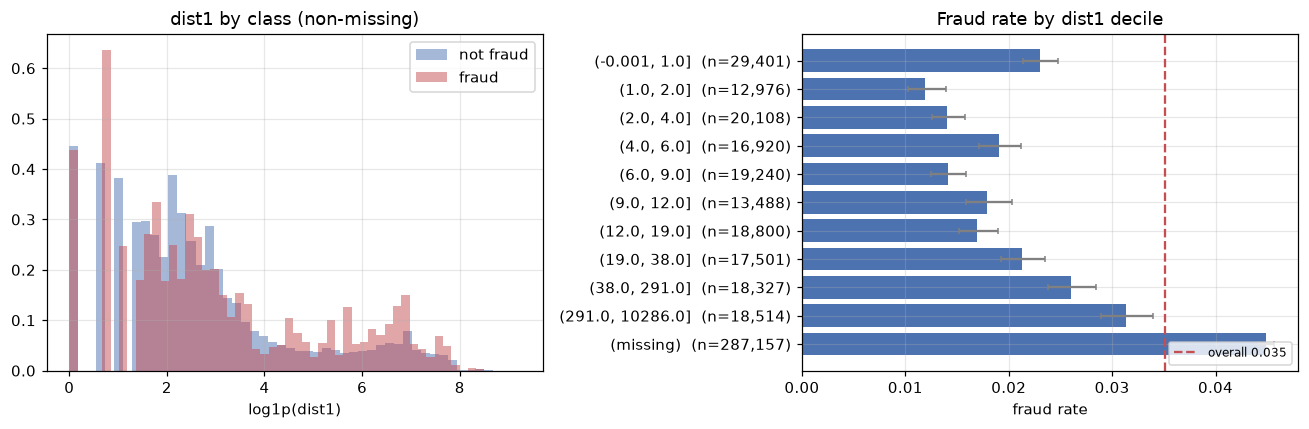

dist1 missing: 4.5% fraud; present: 2.0%


In [45]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
d1 = tr["dist1"].astype("float64")
for label, colr in [(0, "#4C72B0"), (1, "#C44E52")]:
    axes[0].hist(np.log1p(d1[(tr.isFraud == label) & d1.notna()]), bins=50, density=True, alpha=0.5,
                 color=colr, label="fraud" if label else "not fraud")
axes[0].set_xlabel("log1p(dist1)"); axes[0].legend(); axes[0].set_title("dist1 by class (non-missing)")
plot_rate(rate_by_quantile(tr, d1, 10), "Fraud rate by dist1 decile", axes[1])
fig.tight_layout(); plt.show()
print(f"dist1 missing: {tr.loc[d1.isna(), 'isFraud'].mean():.1%} fraud; present: {tr.loc[d1.notna(), 'isFraud'].mean():.1%}")

**C columns (masked counts).** Median and 95th percentile by class.

In [46]:
c_cols = [f"C{i}" for i in range(1, 15) if f"C{i}" in tr.columns]
def p95(s):
    return s.quantile(0.95)

c_summary = tr.groupby("isFraud")[c_cols].agg(["median", p95]).T.unstack()
c_summary.columns = [f"{stat} ({'fraud' if cls else 'not fraud'})" for cls, stat in c_summary.columns]
c_summary.round(1)

,median (not fraud),p95 (not fraud),median (fraud),p95 (fraud)
C1,1.0,19.0,2.0,122.0
C2,1.0,21.0,2.0,126.0
C3,0.0,0.0,0.0,0.0
C4,0.0,1.0,1.0,26.1
C5,0.0,10.0,0.0,1.0
C6,1.0,14.0,1.0,34.1
C7,0.0,1.0,0.0,20.0
C8,0.0,2.0,1.0,52.0
C9,1.0,9.0,0.0,5.0
C10,0.0,2.0,1.0,40.1


**Fraud rate by C value.** Medians only show that fraud has higher counts. The rate at each value shows the shape: does risk rise steadily with the count, and are there single values (such as 0) that stand out?

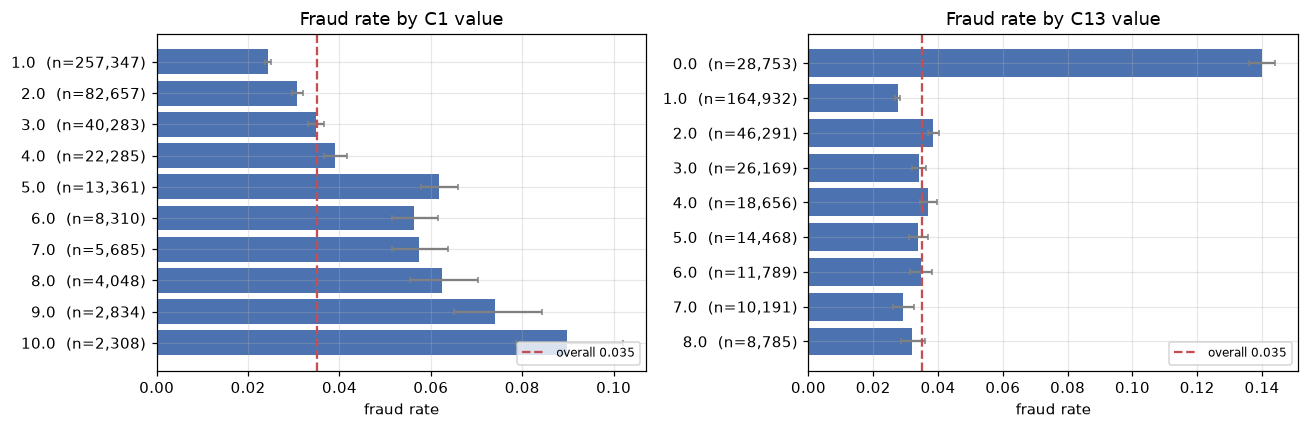

n  fraud    rate      lo      hi  share of all fraud
C1  1.0   257347   6256  0.0243  0.0237  0.0249              0.3769
    2.0    82657   2542  0.0308  0.0296  0.0320              0.1531
    3.0    40283   1402  0.0348  0.0331  0.0366              0.0845
    4.0    22285    869  0.0390  0.0365  0.0416              0.0524
    5.0    13361    825  0.0617  0.0578  0.0660              0.0497
    6.0     8310    468  0.0563  0.0516  0.0615              0.0282
    7.0     5685    326  0.0573  0.0516  0.0637              0.0196
    8.0     4048    253  0.0625  0.0554  0.0704              0.0152
    9.0     2834    210  0.0741  0.0650  0.0843              0.0127
    10.0    2308    207  0.0897  0.0787  0.1020              0.0125
C13 0.0    28753   4021  0.1398  0.1359  0.1439              0.2422
    1.0   164932   4551  0.0276  0.0268  0.0284              0.2742
    2.0    46291   1784  0.0385  0.0368  0.0403              0.1075
    3.0    26169    892  0.0341  0.0320  0.0364              0.0537
    4.0    18656    689  0.0369  0.0343  0.0397              0.0415
    5.0    14468    488  0.0337  0.0309  0.0368              0.0294
    6.0    11789    408  0.0346  0.0315  0.0381              0.0246
    7.0    10191    296  0.0290  0.0260  0.0325              0.0178
    8.0     8785    281  0.0320  0.0285  0.0359              0.0169

In [47]:
c1_tab = value_rates(tr["C1"].astype("float64"), [float(v) for v in range(1, 11)])
c13_tab = value_rates(tr["C13"].astype("float64"), [float(v) for v in range(0, 9)])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_rate(c1_tab, "Fraud rate by C1 value", axes[0])
plot_rate(c13_tab, "Fraud rate by C13 value", axes[1])
fig.tight_layout(); plt.show()
display(pd.concat({"C1": c1_tab, "C13": c13_tab}).round(4))

**D columns against time.** If a D column is "days since some fixed event", it grows steadily with TransactionDay, so the same value means different things early and late in the data. Subtracting it from TransactionDay gives a version that should be stable per customer. Flat lines on the right-hand side support normalising.

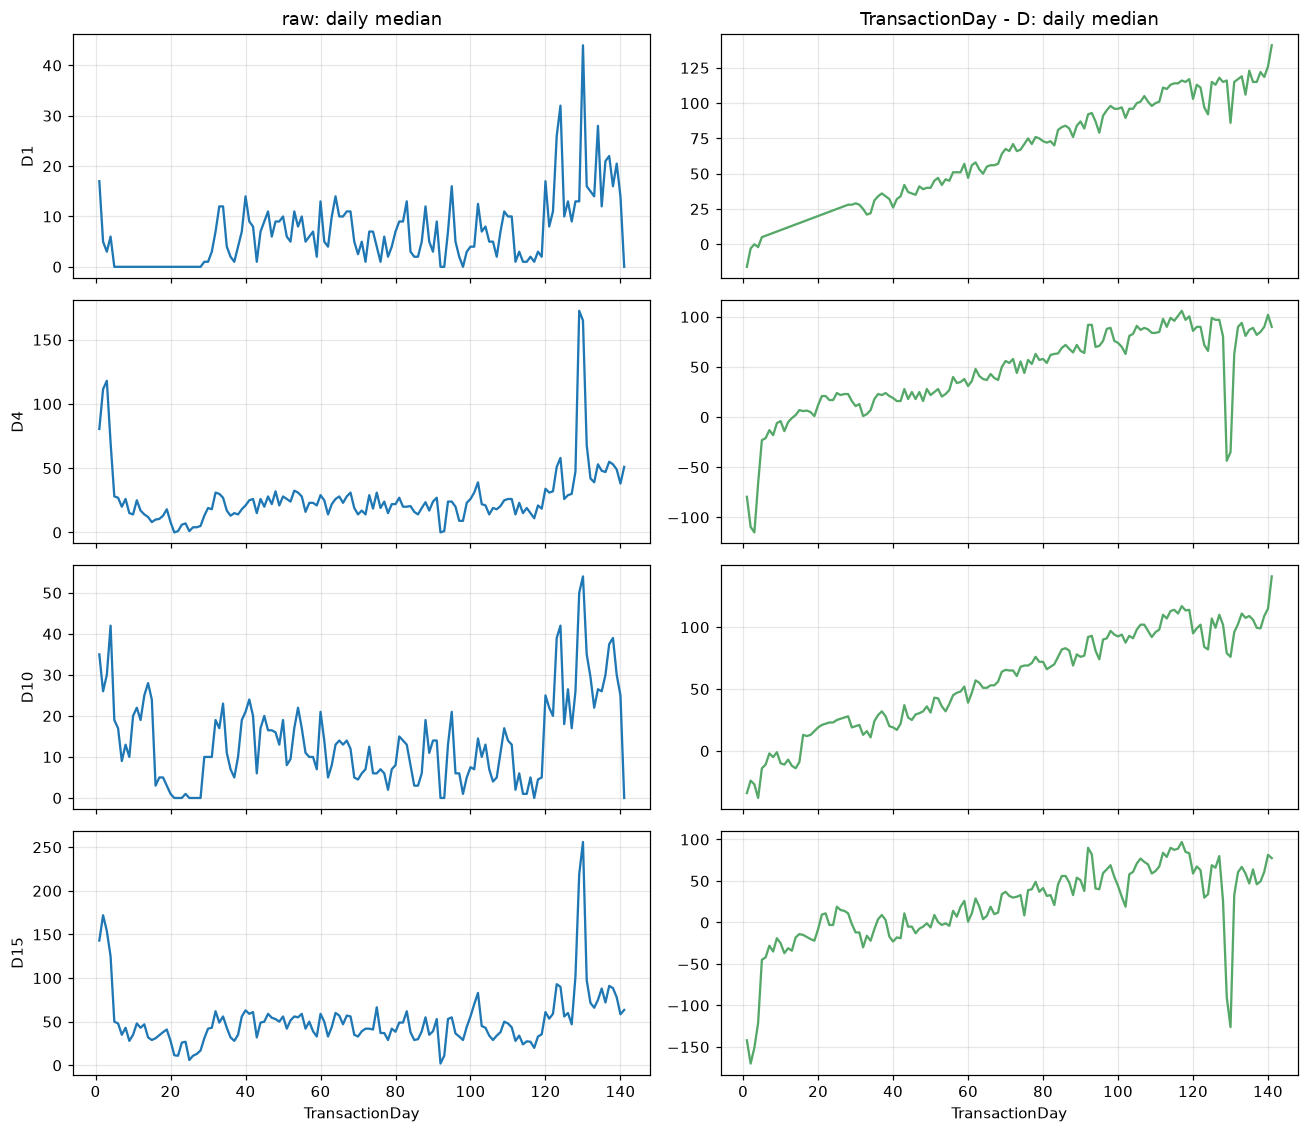

In [48]:
d_show = [c for c in ["D1", "D4", "D10", "D15"] if c in tr.columns]
fig, axes = plt.subplots(len(d_show), 2, figsize=(12, 2.6 * len(d_show)), sharex=True)
axes = np.atleast_2d(axes)
for i, c in enumerate(d_show):
    raw = tr.groupby("TransactionDay")[c].median()
    norm = (tr["TransactionDay"] - tr[c]).groupby(tr["TransactionDay"]).median()
    axes[i, 0].plot(raw.index, raw.values); axes[i, 0].set_ylabel(c)
    axes[i, 1].plot(norm.index, norm.values, color="#55A868")
axes[0, 0].set_title("raw: daily median")
axes[0, 1].set_title("TransactionDay - D: daily median")
axes[-1, 0].set_xlabel("TransactionDay"); axes[-1, 1].set_xlabel("TransactionDay")
fig.tight_layout(); plt.show()

**Account age (D1).** D1 is roughly the number of days since the card or account was first seen, so small values are new accounts. Fraud rate for D1 = 0 to 10 days:

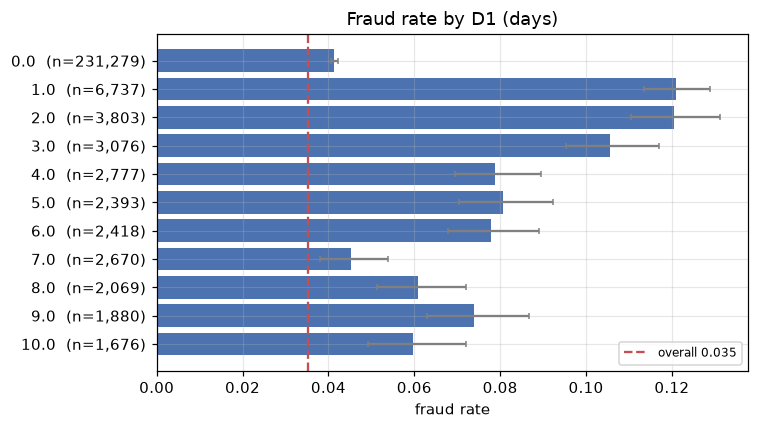

,n,fraud,rate,lo,hi,share of all fraud
0.0,231279,9553,0.0413,0.0405,0.0421,0.5755
1.0,6737,815,0.1210,0.1134,0.1290,0.0491
2.0,3803,458,0.1204,0.1105,0.1312,0.0276
3.0,3076,325,0.1057,0.0953,0.1170,0.0196
4.0,2777,219,0.0789,0.0694,0.0895,0.0132
5.0,2393,193,0.0807,0.0704,0.0922,0.0116
6.0,2418,188,0.0778,0.0677,0.0891,0.0113
7.0,2670,121,0.0453,0.0381,0.0539,0.0073
8.0,2069,126,0.0609,0.0514,0.0720,0.0076
9.0,1880,139,0.0739,0.0630,0.0867,0.0084


In [49]:
d1_tab = value_rates(tr["D1"].astype("float64"), [float(v) for v in range(0, 11)])
fig, ax = plt.subplots(figsize=(7, 4))
plot_rate(d1_tab, "Fraud rate by D1 (days)", ax)
fig.tight_layout(); plt.show()
d1_tab.round(4)

### 7.1 Feature values over time

Daily medians hide individual customers and short bursts. These plots show every transaction against `TransactionDay`: non-fraud in blue, fraud in red (drawn on top), and the validation block in grey. The validation rows have no labels here, so they show only whether the feature's range changes. The dashed line is the train/validation boundary.

What to look for:

- **D1 and D15:** a rising upper edge means the column counts days since a fixed event, so the same value means different things early and late. Fraud from a single account shows up as a diagonal (see the last panel); `TransactionDay − D1` turns each diagonal into a constant, which is why it works as part of the customer ID.
- **C13:** bursts of very large counts that occur once and don't come back. A model can memorise a burst like that under a random split, but it won't help on later months.
- **D1, fraud rows only:** with the non-fraud rows removed and the y-axis zoomed in, the fraud points form
  short diagonal lines rising one day per day. Each line is one account that keeps being labelled fraud.

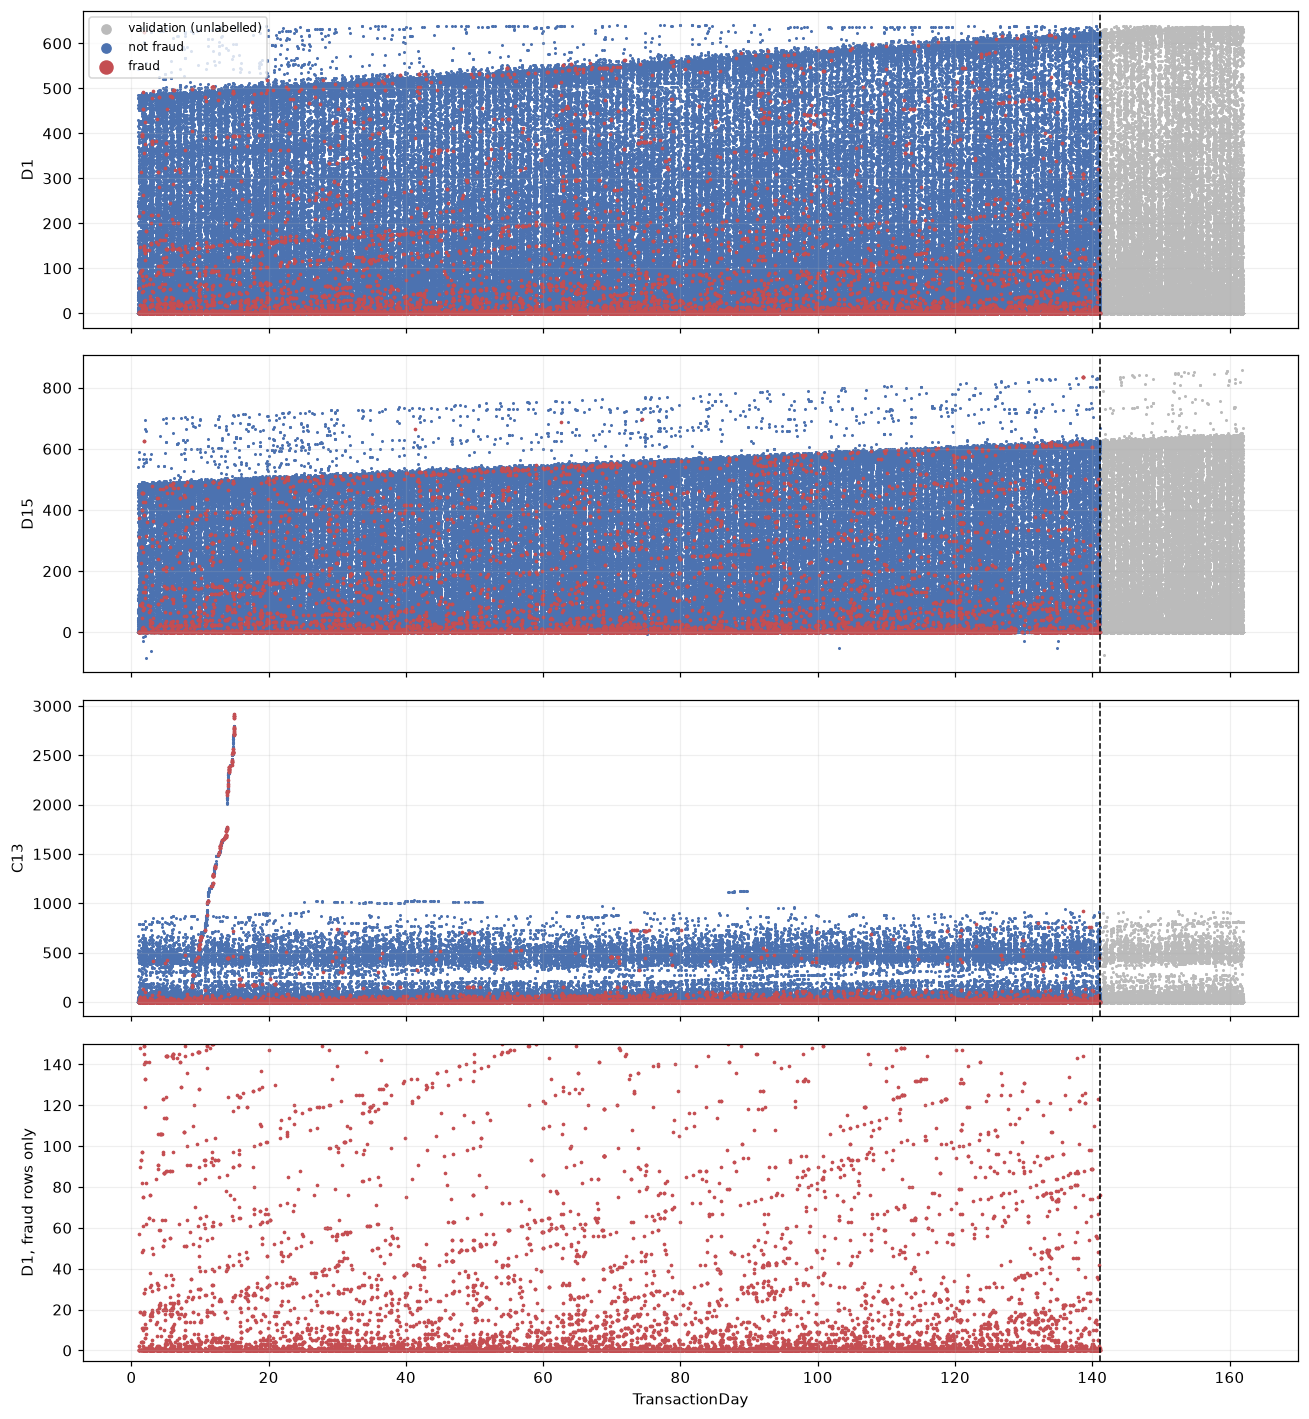

In [50]:
def over_time(col, ax, log=False):
    x_tr = tr["TransactionDT"] / 86400
    y_tr = tr[col].astype("float64")
    ax.scatter(va["TransactionDT"] / 86400, va[col].astype("float64"), s=1, c="#BBBBBB", rasterized=True,
               label="validation (unlabelled)")
    nf = tr["isFraud"] == 0
    ax.scatter(x_tr[nf], y_tr[nf], s=1, c="#4C72B0", rasterized=True, label="not fraud")
    ax.scatter(x_tr[~nf], y_tr[~nf], s=2, c="#C44E52", rasterized=True, label="fraud")
    ax.axvline(tr["TransactionDT"].max() / 86400, ls="--", color="black", lw=1)
    if log:
        ax.set_yscale("log")
    ax.set_ylabel(col + (" (log scale)" if log else ""))
    ax.grid(alpha=0.2)

fig, axes = plt.subplots(4, 1, figsize=(12, 13), sharex=True)
for ax, col in zip(axes[:3], ["D1", "D15", "C13"]):
    over_time(col, ax)
axes[0].legend(loc="upper left", markerscale=6, fontsize=8)

# Fraud rows only, low D1: each diagonal line is one account whose D1 grows by one per day
fr = tr[tr["isFraud"] == 1]
axes[3].scatter(fr["TransactionDT"] / 86400, fr["D1"].astype("float64"), s=2, c="#C44E52", rasterized=True)
axes[3].set_ylim(-5, 150); axes[3].set_ylabel("D1, fraud rows only")
axes[3].axvline(tr["TransactionDT"].max() / 86400, ls="--", color="black", lw=1); axes[3].grid(alpha=0.2)
axes[-1].set_xlabel("TransactionDay")
fig.tight_layout(); plt.show()

In [51]:
c13 = tr["C13"].astype("float64")
big = c13 > 2000
print(f"C13 above 2,000: {big.sum():,} training rows, all on days {tr.loc[big, 'TransactionDay'].min()}-"
      f"{tr.loc[big, 'TransactionDay'].max()}, fraud rate {tr.loc[big, 'isFraud'].mean():.1%}; maximum {c13.max():,.0f}; "
      f"validation rows above 2,000: {int((va['C13'] > 2000).sum())}")

C13 above 2,000: 506 training rows, all on days 13-15, fraud rate 11.1%; maximum 2,918; validation rows above 2,000: 0


### 7.2 D columns over time: drift and fixed dates

The plots above show D1 and D15 drifting: their upper edge rises about one day per calendar day. A column like that
means different things in different months, so cut-offs learned on early months would go stale on later ones. If a
D column counts days since a fixed event, then `TransactionDay − D` is the date of that event, which would stay the
same for a customer and mean the same thing in every month. Here we look at all 15 D columns.

Two checks for each D column, on training rows:

- **Drift:** split the block into 30-day bins, take the 99th percentile of the column in each bin, and fit a line
  against time. A slope near 1 means the column counts days from a fixed event; near 0 means it doesn't accumulate.
- **Constant per customer:** among `uid`s with at least two non-missing values, the share whose values all lie
  within 1 day of each other, before and after taking `TransactionDay − D`. If the share jumps after the
  subtraction, the column points to a fixed date for that customer. (D1 is 1.00 after the subtraction by
  construction, because `uid` is built from it.)

In [52]:
d_cols = [f"D{i}" for i in range(1, 16)]
day_ = tr["TransactionDay"].astype("float64")
bin30 = (day_ // 30).astype(int)
rows = {}
for c in d_cols:
    x = tr[c].astype("float64")
    q99 = x.groupby(bin30).quantile(0.99)
    g = pd.DataFrame({"u": tr["uid"], "raw": x, "norm": day_ - x}).dropna()
    g = g[g.groupby("u")["raw"].transform("size") >= 2]
    spread = g.groupby("u")[["raw", "norm"]].agg(lambda s: s.max() - s.min())
    rows[c] = {"missing": x.isna().mean(), "median": x.median(),
               "drift slope": np.polyfit(q99.index * 30, q99.to_numpy(), 1)[0],
               "constant per uid (raw)": (spread["raw"] <= 1).mean(),
               "constant per uid (day − D)": (spread["norm"] <= 1).mean()}
d_drift = pd.DataFrame(rows).T
d_drift.round(3)

,missing,median,drift slope,constant per uid (raw),constant per uid (day − D)
D1,0.002,1.000,0.940,0.364,1.000
D2,0.490,97.000,0.923,0.132,0.988
D3,0.461,8.000,0.115,0.100,0.133
D4,0.296,22.000,0.933,0.254,0.664
D5,0.537,10.000,0.796,0.098,0.102
D6,0.876,0.000,0.729,0.452,0.638
D7,0.937,0.000,0.672,0.293,0.297
D8,0.870,41.833,-0.066,0.419,0.534
D9,0.870,0.667,0.000,1.000,0.670
D10,0.141,12.000,0.940,0.315,0.647


**Findings.**

| Column(s) | Drift slope | Constant per uid: raw → `day − D` | What it suggests |
| --- | --- | --- | --- |
| D1 | 0.94 | 0.36 → 1.00 | Counts from a fixed date (1.00 by construction) |
| D4, D10, D11, D15 | 0.93–0.97 | 0.22–0.32 → 0.65–0.76 | Count from a fixed date |
| D2 | 0.92 | 0.13 → 0.99 | Counts from a fixed date, which matches D1's where present |
| D3, D5, D7 | 0.12–0.80 | about the same before and after (0.10–0.30) | Not a fixed date; possibly days since the previous transaction |
| D8, D9 | about 0 | — | No drift. D9 is a fraction between 0 and 1 (looks like time of day) |
| D6, D12, D13, D14 | 0.34–0.91 | mixed: small gain or a drop | About 88–90% missing and mostly 0; no clear pattern |

D1, D4, D10, D11 and D15 behave like "days since a fixed date", and D2 repeats D1. D4, D10, D11 and D15 are also
the D columns that the large V blocks share their missing pattern with (section 3).

## 8. Behavioural feature preview

A quick check that the planned aggregates carry signal before building them properly. Each value uses **only earlier transactions of the same uid** (the table is time-sorted, so `shift` and cumulative sums look only backwards). No labels are used.

These are rough versions, good enough to see whether a signal exists.

In [53]:
g = tr.groupby("uid")
n_prior = g.cumcount()
secs_since_prev = g["TransactionDT"].diff()
prior_sum = g["TransactionAmt"].cumsum() - tr["TransactionAmt"]
prior_mean = (prior_sum / n_prior).where(n_prior > 0)
amt_ratio = tr["TransactionAmt"] / prior_mean

first_tx = pd.Series(np.where(n_prior == 0, "first seen", "seen before"), index=tr.index)
rate_table(tr, first_tx)

,n,fraud,rate,lo,hi
seen before,289897,11680,0.040290,0.039580,0.041012
first seen,182535,4919,0.026948,0.026215,0.027701


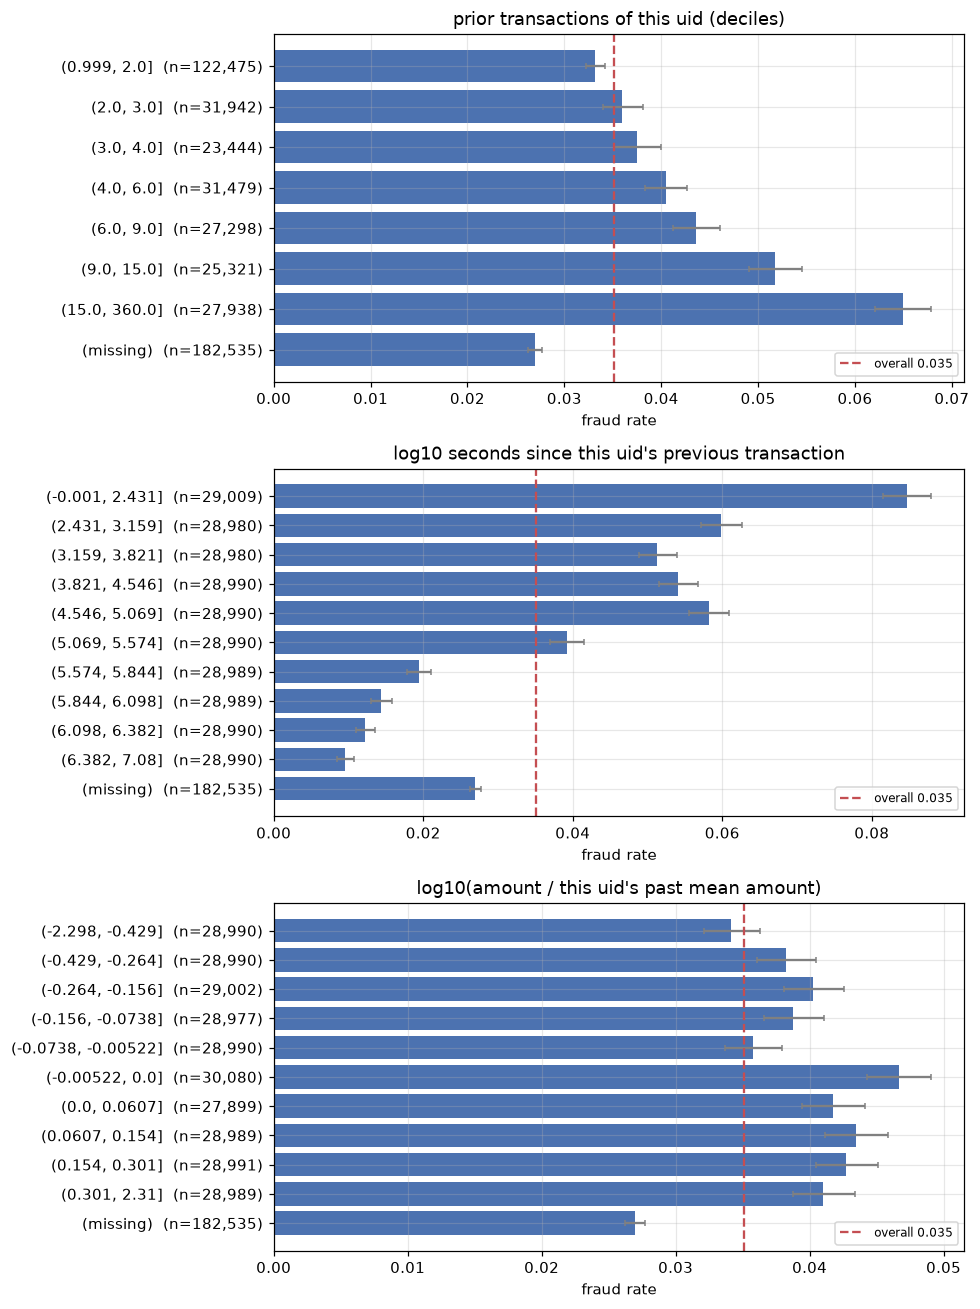

In [54]:
fig, axes = plt.subplots(3, 1, figsize=(9, 12))
plot_rate(rate_by_quantile(tr, n_prior.where(n_prior > 0), 10), "prior transactions of this uid (deciles)", axes[0])
plot_rate(rate_by_quantile(tr, np.log10(secs_since_prev + 1), 10), "log10 seconds since this uid's previous transaction", axes[1])
plot_rate(rate_by_quantile(tr, np.log10(amt_ratio), 10), "log10(amount / this uid's past mean amount)", axes[2])
fig.tight_layout(); plt.show()

In [55]:
for name, s in [("earlier transactions of this uid", n_prior.where(n_prior > 0)),
                ("seconds since this uid's previous transaction", secs_since_prev),
                ("amount / this uid's past mean amount", amt_ratio)]:
    print(name)
    display(rate_by_quantile(tr, s, 10)[["n", "rate"]].round(4).T)

earlier transactions of this uid


,"(0.999, 2.0]","(2.0, 3.0]","(3.0, 4.0]","(4.0, 6.0]","(6.0, 9.0]","(9.0, 15.0]","(15.0, 360.0]",(missing)
n,122475.0000,31942.000,23444.0000,31479.0000,27298.0000,25321.0000,27938.0000,182535.0000
rate,0.0332,0.036,0.0375,0.0405,0.0436,0.0517,0.0649,0.0269


seconds since this uid's previous transaction


,"(-0.001, 269.0]","(269.0, 1442.0]","(1442.0, 6622.8]","(6622.8, 35158.8]","(35158.8, 117186.0]","(117186.0, 375078.0]","(375078.0, 698603.4]","(698603.4, 1253255.2]","(1253255.2, 2412573.4]","(2412573.4, 12026611.0]",(missing)
n,29009.0000,28980.0000,28980.0000,28990.0000,28990.0000,28990.0000,28989.0000,28989.0000,28990.0000,28990.0000,182535.0000
rate,0.0847,0.0598,0.0513,0.0541,0.0582,0.0392,0.0194,0.0144,0.0122,0.0096,0.0269


amount / this uid's past mean amount


,"(0.00404, 0.373]","(0.373, 0.545]","(0.545, 0.699]","(0.699, 0.844]","(0.844, 0.988]","(0.988, 1.0]","(1.0, 1.15]","(1.15, 1.424]","(1.424, 2.002]","(2.002, 203.997]",(missing)
n,28990.0000,28990.0000,29002.0000,28977.0000,28990.0000,30080.0000,27899.0000,28989.0000,28991.0000,28989.000,182535.0000
rate,0.0341,0.0382,0.0403,0.0388,0.0358,0.0466,0.0417,0.0434,0.0427,0.041,0.0269


**Findings.**

- **History:** transactions from a customer seen before have more fraud (4.0%) than first-seen ones (2.7%), and the
  rate rises with the number of earlier transactions, from 3.3% (1 to 2) to 6.5% (16 or more). This fits labels that
  spread to a flagged customer's later transactions.
- **Time since the previous transaction:** a strong signal. Gaps under about 4.5 minutes have 8.5% fraud, falling
  steadily to 1.9% for gaps of 4 to 8 days and 1.0% for gaps over about 4 weeks.
- **Amount compared with the customer's average:** almost flat (3.4% to 4.7% across deciles). Section 9.5 looks at
  this in more detail.

### 8.1 How much do a customer's earlier values vary?

The checks above compare a transaction with the customer's past **average**. This one looks at the **spread**: the
standard deviation of the customer's earlier values, using only earlier transactions of the same `uid` and only
when there are at least two of them.

Two kinds of column are checked:

- **Amount.** A customer who always pays similar amounts versus one whose amounts vary a lot.
- **`TransactionDay − D` for D4, D10, D11 and D15.** Section 7.2 suggests these are fixed dates for one customer.
  If a `uid` really is one customer, their spread should be close to 0. A large spread means the `uid` mixes
  transactions whose dates disagree, for example different accounts that share card, address and D1.

Rows are grouped into: fewer than two earlier values, spread exactly 0, and three equal-sized groups of the positive
spreads. Fraud rates are shown for the whole training block and separately for its first and last 30 days, to see
whether the pattern holds over time.

In [56]:
def prior_std(key, x):
    """Standard deviation of x over earlier rows with the same key (missing x ignored; NaN if fewer than 2)."""
    x = x.astype("float64")
    present = x.notna().astype("float64")
    filled = x.fillna(0.0)
    n = present.groupby(key).cumsum() - present
    s1 = filled.groupby(key).cumsum() - filled
    s2 = (filled ** 2).groupby(key).cumsum() - filled ** 2
    var = (s2 - s1 ** 2 / n) / (n - 1)
    return np.sqrt(var.clip(lower=0)).where(n >= 2)

def spread_groups(sd):
    pos = sd[sd > 1e-9]
    cuts = pos.quantile([1 / 3, 2 / 3]).to_numpy()
    labels = np.select([sd.isna(), sd <= 1e-9, sd <= cuts[0], sd <= cuts[1]],
                       ["fewer than 2 earlier", "spread 0", "low spread", "medium spread"], "high spread")
    return pd.Series(labels, index=sd.index), cuts

order = ["fewer than 2 earlier", "spread 0", "low spread", "medium spread", "high spread"]
first30 = tr["TransactionDay"] <= tr["TransactionDay"].min() + 29
last30 = tr["TransactionDay"] >= tr["TransactionDay"].max() - 29
spread_cols = {"amount": tr["TransactionAmt"]}
spread_cols.update({f"day − {c}": tr["TransactionDay"] - tr[c] for c in ["D4", "D10", "D11", "D15"]})
spread_tabs = {}
for name, x in spread_cols.items():
    grp, cuts = spread_groups(prior_std(tr["uid"], x))
    t = rate_table(tr, grp).reindex(order)[["n", "rate"]]
    t["rate, first 30 days"] = tr.loc[first30, "isFraud"].groupby(grp[first30]).mean().reindex(order)
    t["rate, last 30 days"] = tr.loc[last30, "isFraud"].groupby(grp[last30]).mean().reindex(order)
    spread_tabs[f"{name} (cuts {cuts[0]:.3g}, {cuts[1]:.3g})"] = t
pd.concat(spread_tabs).round(4)

n    rate  rate, first 30 days  rate, last 30 days
amount (cuts 23, 54.5)       fewer than 2 earlier  258909  0.0286               0.0180              0.0356
                             spread 0               16602  0.0466               0.0354              0.0444
                             low spread             65640  0.0462               0.0441              0.0426
                             medium spread          65640  0.0443               0.0490              0.0445
                             high spread            65641  0.0378               0.0361              0.0393
day − D4 (cuts 2.04, 95.3)   fewer than 2 earlier  303899  0.0298               0.0199              0.0359
                             spread 0               59989  0.0407               0.0382              0.0407
                             low spread             36182  0.0396               0.0600              0.0351
                             medium spread          36180  0.0533               0.0641              0.0462
                             high spread            36182  0.0482               0.0411              0.0510
day − D10 (cuts 0.707, 62.8) fewer than 2 earlier  273704  0.0303               0.0197              0.0377
                             spread 0               83078  0.0515               0.0409              0.0628
                             low spread             42849  0.0357               0.0603              0.0257
                             medium spread          34251  0.0461               0.0546              0.0459
                             high spread            38550  0.0241               0.0289              0.0183
day − D11 (cuts 0.707, 69)   fewer than 2 earlier  352056  0.0369               0.0241              0.0489
                             spread 0               45329  0.0253               0.0301              0.0243
                             low spread             27968  0.0255               0.0376              0.0183
                             medium spread          22065  0.0497               0.0821              0.0424
                             high spread            25014  0.0260               0.0243              0.0206
day − D15 (cuts 0.577, 59.5) fewer than 2 earlier  276532  0.0303               0.0195              0.0377
                             spread 0               77779  0.0421               0.0406              0.0451
                             low spread             40420  0.0321               0.0512              0.0232
                             medium spread          38330  0.0526               0.0583              0.0612
                             high spread            39371  0.0413               0.0404              0.0367

**Findings.**

- **Most of the difference is "has history or not".** Rows with fewer than two earlier values have 2.9–3.7% fraud
  against 2.4–5.3% for the spread groups; that is the same split as "first seen vs seen before" above.
- **Amount spread: a weak pattern.** Customers whose amounts vary a lot have slightly less fraud (3.8%) than those
  with zero to medium spread (4.4–4.7%). In the last 30 days the ordering is similar (3.9% vs 4.3–4.5%), but in the
  first 30 days high spread (3.6%) ties with spread 0 (3.5%). The gap is small and not fully consistent.
- **`TransactionDay − D` spread: no clear or stable pattern.** A spread of 0 is not the safest group: for D10 it
  has 5.2% fraud against 2.4% for the highest spread, the opposite of what "a mixed-up `uid` is riskier" predicts.
  The low-spread group changes most over time (for example D10: 6.0% in the first 30 days, 2.6% in the last 30;
  D15: 5.1% → 2.3%). D4 and D11 show no consistent ordering either.

So the spread of a customer's amounts carries at most a small signal, while the spread of the `TransactionDay − D`
dates does not separate fraud in a way that holds over time.

### 8.2 C counts compared with the customer's past

Section 7 shows the raw C1 and C13 values carry signal. Here the count is compared with the customer's own past
average (earlier transactions of the same `uid` only): does a jump in the count, relative to the customer's usual
level, add risk?

In [57]:
c_rel = {}
for c in ["C1", "C13"]:
    x = tr[c].astype("float64")
    n_prev = tr.groupby("uid").cumcount()
    past_mean = ((x.groupby(tr["uid"]).cumsum() - x) / n_prev).where(n_prev > 0)
    r = x / past_mean
    b = pd.cut(r, [-0.01, 0.5, 0.9, 1.1, 2, np.inf], labels=["< 0.5x", "0.5-0.9x", "about the same", "1.1-2x", "> 2x"])
    b = b.astype(object).where(r.notna(), np.where(n_prev > 0, "past average 0", "no earlier transaction"))
    c_rel[c] = rate_table(tr, pd.Series(b, index=tr.index)).reindex(
        ["< 0.5x", "0.5-0.9x", "about the same", "1.1-2x", "> 2x", "past average 0", "no earlier transaction"])[["n", "rate"]]
pd.concat(c_rel, axis=1).round(4)

C1             C13        
                             n    rate       n    rate
< 0.5x                   26167  0.0360   28751  0.0702
0.5-0.9x                 33302  0.0238   17761  0.0251
about the same          170356  0.0333   80386  0.0364
1.1-2x                   44877  0.0472  118708  0.0330
> 2x                     15160  0.1412   37952  0.0438
past average 0              35  0.3714    6339  0.1120
no earlier transaction  182535  0.0269  182535  0.0269

**Findings.**

- **C1:** a jump is risky. A C1 more than twice the customer's past average has 14.1% fraud, against 3.3% for
  about the same.
- **C13:** the signal goes the other way. A C13 below half the past average has 7.0%, and a past average of 0 has
  11.2%, against 3.6% for about the same.

Both carry signal beyond the raw values in section 7, in different directions.

## 9. Domain-knowledge hypotheses: supported or not?

Card-fraud practice suggests a set of red flags. Some of them may not hold in this dataset, because Vesta's data is
e-commerce only, many fields are masked, and labels spread to later linked transactions after a chargeback
(section 5). Each hypothesis below is tested on the training block. Checks that use a customer's or device's history
only look at earlier transactions. Each one ends with a verdict.

All checks group by the `uid` customer proxy from section 5.

### 9.1 Account takeover: a known customer on a new device

**Hypothesis.** When someone takes over an account, the customer suddenly appears on a device they have never used.
So a transaction from a known customer on an unfamiliar device should be riskier than one on their usual device.

In [58]:
dev = tr["DeviceInfo"].astype(object)
has_dev = dev.notna()
prior_devs = has_dev.astype(int).groupby(tr["uid"]).cumsum() - has_dev.astype(int)   # earlier rows with a device
first_pair = ~pd.DataFrame({"uid": tr["uid"], "dev": dev}).duplicated()            # first time this uid uses this device
dev_status = pd.Series(np.select(
    [~has_dev, prior_devs == 0, first_pair],
    ["no device recorded", "no earlier device for this uid", "NEW device for this uid"],
    "device used before by this uid"), index=tr.index)
dev_tab = rate_table(tr, dev_status)
dev_tab["share of all fraud"] = dev_tab["fraud"] / tr["isFraud"].sum()
dev_tab.round(4)

,n,fraud,rate,lo,hi,share of all fraud
no device recorded,372896,9691,0.0260,0.0255,0.0265,0.5838
no earlier device for this uid,54353,2940,0.0541,0.0522,0.0560,0.1771
device used before by this uid,30888,2952,0.0956,0.0923,0.0989,0.1778
NEW device for this uid,14295,1016,0.0711,0.0670,0.0754,0.0612


**Verdict: not supported.** A known customer on a new device has 7.1% fraud, which is *lower* than the 9.6% for a
device the customer has used before. Both are above the 3.5% baseline, because having a device recorded at all is
risky in this data (2.6% fraud when no device is recorded). The likely reason is the labelling: once a customer is
fraudulent, their later transactions are labelled fraud too, and they keep using the same device. Here, "same device
as before" points to a known fraudster more than a new device points to a takeover.

**Also: a new browser, email domain or product.** The same check for the browser (`id_31`), the purchaser email
domain and the product code: is a value the known customer has never used before riskier than one they have used?

In [59]:
def novelty_status(col):
    v = tr[col].astype(object)
    has = v.notna()
    prior = has.astype(int).groupby(tr["uid"]).cumsum() - has.astype(int)
    first = ~pd.DataFrame({"uid": tr["uid"], "v": v}).duplicated()
    s = pd.Series(np.select([~has, prior == 0, first], ["not recorded", "no earlier value", "NEW for this uid"],
                            "used before by this uid"), index=tr.index)
    return rate_table(tr, s).reindex(["used before by this uid", "NEW for this uid", "no earlier value",
                                      "not recorded"])[["n", "rate"]]
pd.concat({"browser": novelty_status("id_31"), "email domain": novelty_status("P_emaildomain"),
           "product": novelty_status("ProductCD")}, axis=1).round(4)

browser         email domain           product        
                              n    rate            n    rate         n    rate
used before by this uid   38696  0.1057       203157  0.0427  280769.0  0.0408
NEW for this uid          19429  0.0785        30942  0.0373    9128.0  0.0241
no earlier value          59338  0.0573       164747  0.0278  182535.0  0.0269
not recorded             354969  0.0214        73586  0.0298       NaN     NaN

**Verdict: the same as for devices.** A new value is *less* risky than one the customer used before: browser
7.9% vs 10.6%, email domain 3.7% vs 4.3%, product 2.4% vs 4.1%. As in 9.1, this fits customer-level labelling.
The difference is clear for browser and product and small for email.

### 9.2 Card cycling: many cards on one device

**Hypothesis.** A fraudster with a batch of stolen cards tries them one after another from the same device. A
device that has already been used with several different cards should be riskier.

The device fingerprint is DeviceInfo + OS + browser + screen. A missing part counts as its own value.

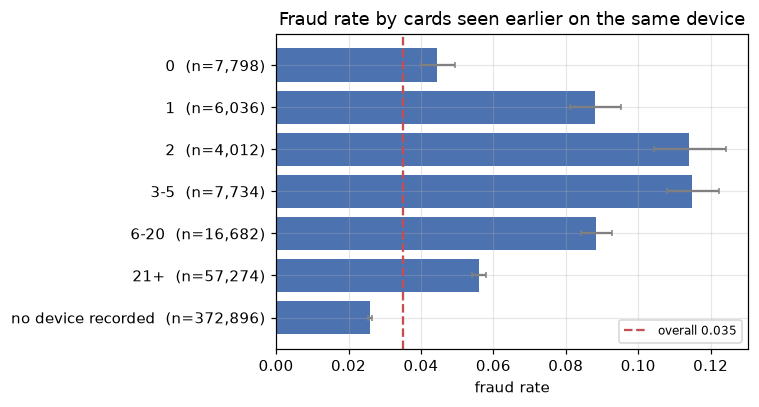

,n,fraud,rate,lo,hi
0,7798,347,0.0445,0.0401,0.0493
1,6036,531,0.0880,0.0811,0.0954
2,4012,457,0.1139,0.1044,0.1241
3-5,7734,889,0.1149,0.1080,0.1222
6-20,16682,1474,0.0884,0.0841,0.0928
21+,57274,3210,0.0560,0.0542,0.0580
no device recorded,372896,9691,0.0260,0.0255,0.0265


In [60]:
part = lambda c: tr[c].astype(object).fillna("?").astype(str)
fp = (part("DeviceInfo") + "|" + part("id_30") + "|" + part("id_31") + "|" + part("id_33")).where(has_dev)
first_card_on_fp = ~pd.DataFrame({"fp": fp, "card": tr["card1"]}).duplicated() & fp.notna()
cards_before = (first_card_on_fp.astype(int).groupby(fp).cumsum() - first_card_on_fp.astype(int)).where(fp.notna())
bucket = pd.cut(cards_before, [-0.5, 0.5, 1.5, 2.5, 5.5, 20.5, np.inf], labels=["0", "1", "2", "3-5", "6-20", "21+"])
fp_tab = rate_table(tr, bucket.astype(object).where(fp.notna(), "no device recorded"))
fp_tab = fp_tab.reindex(["0", "1", "2", "3-5", "6-20", "21+", "no device recorded"]).dropna(how="all")
fig, ax = plt.subplots(figsize=(7, 3.8))
plot_rate(fp_tab, "Fraud rate by cards seen earlier on the same device", ax)
fig.tight_layout(); plt.show()
fp_tab.round(4)

**Verdict: supported, but risk rises and then falls.** A device with no earlier card has 4.5% fraud. With 2 to 5
earlier cards it reaches about 11.5%, three times the baseline. With 21 or more cards it drops back to 5.6%, because
those fingerprints are common shared setups (the same phone model, OS and browser used by many people) rather than
one person's device. A simple "more cards = more risk" rule would miss this.

**Also: customers and transactions per device.** The same fingerprint, counting different customers (`uid`)
seen on it earlier, and all earlier transactions from it.

In [61]:
first_uid_on_fp = ~pd.DataFrame({"fp": fp, "u": tr["uid"]}).duplicated() & fp.notna()
uids_before = (first_uid_on_fp.astype(int).groupby(fp).cumsum() - first_uid_on_fp.astype(int)).where(fp.notna())
tx_before = fp.groupby(fp).cumcount().where(fp.notna())
labs = ["0", "1", "2", "3-5", "6-20", "21+", "no device recorded"]
def fp_buckets(x):
    b = pd.cut(x, [-0.5, 0.5, 1.5, 2.5, 5.5, 20.5, np.inf], labels=labs[:-1]).astype(object)
    return rate_table(tr, b.where(fp.notna(), "no device recorded")).reindex(labs)[["n", "rate"]]
pd.concat({"customers seen earlier": fp_buckets(uids_before),
           "transactions seen earlier": fp_buckets(tx_before)}, axis=1).round(4)

customers seen earlier         transactions seen earlier        
                                        n    rate                         n    rate
0                                    7798  0.0445                      7798  0.0445
1                                    5804  0.0829                      4388  0.0720
2                                    3757  0.0982                      3240  0.0901
3-5                                  7174  0.1047                      6637  0.0984
6-20                                15373  0.0995                     14840  0.0925
21+                                 59630  0.0575                     62633  0.0627
no device recorded                 372896  0.0260                    372896  0.0260

**Verdict: same shape as cards.** Customers seen earlier on the same device rise from 4.5% (none) to 10.5% (3 to
5), then fall to 5.8% (21+). Earlier transactions on the device follow the same pattern (4.5% → 9.8% → 6.3%). These
counts overlap heavily with the card count above.

### 9.3 Card testing: a tiny purchase, then a big one

**Hypothesis.** Fraudsters check that a stolen card works with a very small purchase, then spend. Tiny amounts,
and a large purchase right after a tiny one from the same customer, should be riskier.

In [62]:
amt = tr["TransactionAmt"].astype("float64")
prev_amt = amt.groupby(tr["uid"]).shift(1)
testing = pd.Series(np.select(
    [prev_amt.isna(), (prev_amt < 5) & (amt >= 10 * prev_amt), prev_amt < 5],
    ["no earlier transaction", "previous < $5, this one >= 10x larger", "previous < $5, this one not much larger"],
    "previous >= $5"), index=tr.index)
size = pd.Series(np.where(amt < 5, "under $5", "$5 or more"), index=tr.index)
display(rate_table(tr, size).round(4))
rate_table(tr, testing).round(4)

,n,fraud,rate,lo,hi
$5 or more,471512,16539,0.0351,0.0346,0.0356
under $5,920,60,0.0652,0.0510,0.0830


,n,fraud,rate,lo,hi
previous >= $5,289240,11624,0.0402,0.0395,0.0409
no earlier transaction,182535,4919,0.0269,0.0262,0.0277
"previous < $5, this one not much larger",525,42,0.0800,0.0597,0.1064
"previous < $5, this one >= 10x larger",132,14,0.1061,0.0642,0.1702


**Verdict: partly supported, but too rare to matter much.** Purchases under \$5 have 6.5% fraud, almost twice the
baseline, but there are only 920 of them (0.2% of rows). A large purchase right after a tiny one has 10.6% fraud,
but only on 132 rows, and the 95% interval runs from 6.4% to 17.0%. The pattern is real but covers very little
fraud.

### 9.4 Bursts: many transactions in a short time

**Hypothesis.** A stolen card is used as much as possible before it gets blocked, so several transactions from the
same customer within a day should be riskier.

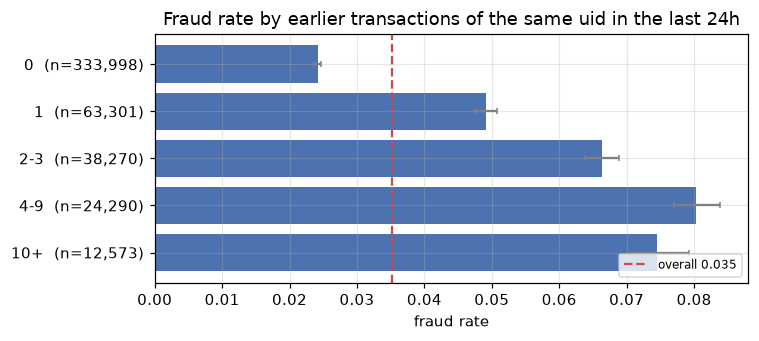

,n,fraud,rate,lo,hi
0,333998,8066,0.0241,0.0236,0.0247
1,63301,3108,0.0491,0.0474,0.0508
2-3,38270,2537,0.0663,0.0638,0.0688
4-9,24290,1951,0.0803,0.0770,0.0838
10+,12573,937,0.0745,0.0701,0.0792


In [63]:
# transactions by the same uid in the 24 hours before this one (earlier rows only)
codes = tr["uid"].astype("category").cat.codes.to_numpy().astype(np.int64)
t = tr["TransactionDT"].to_numpy().astype(np.int64)
order = np.lexsort((t, codes))                     # stable: ties keep time order
key = codes[order] * (1 << 26) + t[order]
pos = np.arange(len(key))
count_24h = np.empty(len(key), dtype=np.int64)
count_24h[order] = pos - np.searchsorted(key, key - 86400, side="left")
burst = pd.cut(pd.Series(count_24h, index=tr.index), [-0.5, 0.5, 1.5, 3.5, 9.5, np.inf],
               labels=["0", "1", "2-3", "4-9", "10+"])
burst_tab = rate_table(tr, burst.astype(object)).reindex(["0", "1", "2-3", "4-9", "10+"])
fig, ax = plt.subplots(figsize=(7, 3.2))
plot_rate(burst_tab, "Fraud rate by earlier transactions of the same uid in the last 24h", ax)
fig.tight_layout(); plt.show()
burst_tab.round(4)

**Verdict: supported.** With no earlier transaction from the same customer in the last 24 hours, fraud is 2.4%. It
rises to 4.9% with one, 6.6% with 2 to 3, and 8.0% with 4 to 9. This is one of the clearest behavioural signals.

**Also: other windows and the amount spent.** The same count over the last hour and the last 7 days, and the
amount the customer spent in the 24 hours before this transaction.

In [64]:
amt_sorted = tr["TransactionAmt"].to_numpy().astype("float64")[order]
csum = np.concatenate([[0.0], np.cumsum(amt_sorted)])
def window_prior(window):
    """Count and amount of the same uid's earlier transactions within `window` seconds (earlier rows only)."""
    left = np.searchsorted(key, key - window, side="left")
    cnt, tot = np.empty(len(key)), np.empty(len(key))
    cnt[order], tot[order] = pos - left, csum[pos] - csum[left]
    return pd.Series(cnt, index=tr.index), pd.Series(tot, index=tr.index)

out = {}
for name, w in [("last 1 hour", 3600), ("last 7 days", 7 * 86400)]:
    c, _ = window_prior(w)
    b = pd.cut(c, [-0.5, 0.5, 1.5, 3.5, 9.5, np.inf], labels=["0", "1", "2-3", "4-9", "10+"]).astype(object)
    out[name] = rate_table(tr, b).reindex(["0", "1", "2-3", "4-9", "10+"])[["n", "rate"]]
display(pd.concat(out, axis=1).round(4))
_, s24 = window_prior(86400)
sb = pd.cut(s24, [-0.01, 0.01, 50, 200, 1000, np.inf], labels=["$0", "up to $50", "$50-200", "$200-1,000", "over $1,000"])
print("Amount spent by the same customer in the previous 24 hours")
rate_table(tr, sb.astype(object)).reindex(["$0", "up to $50", "$50-200", "$200-1,000", "over $1,000"]).round(4)

last 1 hour         last 7 days        
              n    rate           n    rate
0        397575  0.0289      278495  0.0219
1         48651  0.0616       83952  0.0352
2-3       19660  0.0769       55543  0.0526
4-9        6015  0.0845       36268  0.0811
10+         531  0.1582       18174  0.0922

Amount spent by the same customer in the previous 24 hours


,n,fraud,rate,lo,hi
$0,333998,8066,0.0241,0.0236,0.0247
up to $50,23823,1347,0.0565,0.0537,0.0595
$50-200,53663,3144,0.0586,0.0566,0.0606
"$200-1,000",47014,3107,0.0661,0.0639,0.0684
"over $1,000",13934,935,0.0671,0.0631,0.0714


**Verdict: supported for all windows; the amount adds little beyond the count.** The 1-hour count rises from 2.9%
(none) to 6.2% (one) and 15.8% (10 or more, 531 rows); the 7-day count from 2.2% to 9.2%. Any spend in the previous
24 hours raises fraud from 2.4% to 5.7–6.7% depending on the amount, but the amount spent changes it only a little
(5.7% up to \$50, 6.7% over \$1,000), so most of that is the count again.

### 9.5 Spending spike: much more than the customer usually spends

**Hypothesis.** A thief spends more than the real customer usually does, so an amount far above the customer's
past average should be riskier.

In [65]:
prior_n = tr.groupby("uid").cumcount()
prior_mean_amt = ((amt.groupby(tr["uid"]).cumsum() - amt) / prior_n).where(prior_n > 0)
ratio = amt / prior_mean_amt
spike = pd.cut(ratio, [0, 0.5, 0.9, 1.1, 2, 5, np.inf],
               labels=["< 0.5x", "0.5-0.9x", "about the same", "1.1-2x", "2-5x", "> 5x"])
spike_tab = rate_table(tr, spike.astype(object).where(ratio.notna(), "no earlier transaction"))
spike_tab = spike_tab.reindex(["< 0.5x", "0.5-0.9x", "about the same", "1.1-2x", "2-5x", "> 5x",
                               "no earlier transaction"])
spike_tab.round(4)

,n,fraud,rate,lo,hi
< 0.5x,48989,1768,0.0361,0.0345,0.0378
0.5-0.9x,78331,3018,0.0385,0.0372,0.0399
about the same,68261,2861,0.0419,0.0404,0.0434
1.1-2x,65217,2839,0.0435,0.0420,0.0451
2-5x,23557,979,0.0416,0.0391,0.0442
> 5x,5542,215,0.0388,0.0340,0.0442
no earlier transaction,182535,4919,0.0269,0.0262,0.0277


**Verdict: not supported.** The fraud rate barely changes with how the amount compares with the customer's average:
3.6% to 4.4% across all bands. Spending more than 5x the usual amount has 3.9% fraud, no higher than spending about
the same. The only clear gap is between customers with and without history (about 4% vs 2.7%), which is the "seen
before" effect from section 8, not a spending spike.

**Also: other ways to compare the amount with the customer's past.** 9.5 used the customer's average. Here: the
amount against the previous amount and against the largest amount so far, and the spend over the last 24 hours
(including this transaction) against the customer's average daily spend so far.

In [66]:
prev_max = amt.groupby(tr["uid"]).cummax().groupby(tr["uid"]).shift(1)
bands = [0, 0.5, 0.9, 1.1, 2, 5, np.inf]
band_labels = ["< 0.5x", "0.5-0.9x", "about the same", "1.1-2x", "2-5x", "> 5x"]
def band_table(r):
    b = pd.cut(r, bands, labels=band_labels).astype(object).where(r.notna(), "no earlier transaction")
    return rate_table(tr, b).reindex(band_labels + ["no earlier transaction"])[["n", "rate"]]
cnt24, spend24 = window_prior(86400)
spent_before = amt.groupby(tr["uid"]).cumsum() - amt
first_day = tr.groupby("uid")["TransactionDay"].transform("min")
daily_avg = spent_before / (tr["TransactionDay"] - first_day + 1)
rel_daily = ((spend24 + amt) / daily_avg).where(prior_n > 0)
pd.concat({"vs previous amount": band_table(amt / prev_amt),
           "vs largest so far": band_table(amt / prev_max),
           "24h spend vs daily average": band_table(rel_daily)}, axis=1).round(4)

vs previous amount         vs largest so far         24h spend vs daily average        
                                        n    rate                 n    rate                          n    rate
< 0.5x                              39788  0.0321             98074  0.0408                       4523  0.0944
0.5-0.9x                            56630  0.0358             74215  0.0395                       5136  0.0724
about the same                     100201  0.0489             69135  0.0443                      21557  0.0580
1.1-2x                              54422  0.0354             30613  0.0340                      74864  0.0618
2-5x                                29324  0.0380             13655  0.0366                      54963  0.0492
> 5x                                 9532  0.0458              4205  0.0359                     128854  0.0179
no earlier transaction             182535  0.0269            182535  0.0269                     182535  0.0269

**Verdict: no spending spike, but one signal in the opposite direction.**

- **Against the previous amount:** no spike pattern. "About the same" is the riskiest band (4.9% vs 3.2% to 4.6%),
  which echoes the repeated amounts in 9.10.
- **Against the largest so far:** no signal (3.4% to 4.4% across bands), like the average in 9.5.
- **24-hour spend against the daily average:** a strong signal in the *opposite* direction. Spending more than 5
  times the usual daily amount has 1.8% fraud (128,854 rows), while spending less than half of it has 9.4%.

### 9.6 Anonymous email providers

**Hypothesis.** Fraudsters hide behind throwaway or privacy-focused email providers, so these should be riskier
than mainstream providers.

In [67]:
p_email = tr["P_emaildomain"].astype(object)
anon_domains = {"anonymous.com", "protonmail.com"}
email_kind = pd.Series(np.select([p_email.isna(), p_email.isin(anon_domains)],
                                 ["(missing)", "anonymous / privacy provider"], "mainstream provider"), index=tr.index)
display(rate_table(tr, email_kind).round(4))
rate_table(tr, p_email.where(p_email.isin(anon_domains))).drop("(missing)").round(4)

,n,fraud,rate,lo,hi
mainstream provider,368818,13676,0.0371,0.0365,0.0377
(missing),73586,2195,0.0298,0.0286,0.0311
anonymous / privacy provider,30028,728,0.0242,0.0226,0.0260


,n,fraud,rate,lo,hi
anonymous.com,29961,697,0.0233,0.0216,0.0250
protonmail.com,67,31,0.4627,0.3486,0.5808


**Verdict: not supported for anonymous.com, possibly true for protonmail.com.** anonymous.com, the largest privacy
provider, has 2.3% fraud, *below* mainstream providers (3.7%). protonmail.com has 46% fraud, but on only 67 rows,
so it doesn't change the overall picture. Fraud risk differs more between mainstream providers (section 6) than
between mainstream and anonymous ones.

### 9.7 Spoofed device: device type doesn't match the operating system

**Hypothesis.** Emulators and spoofing tools give inconsistent device information, for example "desktop" with a
mobile OS. Mismatches should be riskier.

In [68]:
os_raw = tr["id_30"].astype(object).str.lower()
os_family = pd.Series(np.select(
    [os_raw.isna(), os_raw.str.startswith(("ios", "android"), na=False),
     os_raw.str.startswith(("windows", "mac", "linux"), na=False)],
    ["(missing)", "mobile OS", "desktop OS"], "other OS"), index=tr.index)
dtype_ = tr["DeviceType"].astype(object).fillna("(missing)")
combo = dtype_ + " + " + os_family
rate_table(tr, combo).round(4)

,n,fraud,rate,lo,hi
(missing) + (missing),354794,7569,0.0213,0.0209,0.0218
desktop + desktop OS,43506,1369,0.0315,0.0299,0.0331
desktop + (missing),28026,3093,0.1104,0.1067,0.1141
mobile + (missing),23523,3046,0.1295,0.1253,0.1338
mobile + mobile OS,22518,1515,0.0673,0.0641,0.0706
mobile + desktop OS,44,4,0.0909,0.0359,0.2116
desktop + other OS,11,3,0.2727,0.0975,0.5657
mobile + other OS,8,0,0.0000,0.0000,0.3244
desktop + mobile OS,2,0,0.0000,0.0000,0.6576


**Verdict: can't be tested.** Real mismatches almost never occur: 2 rows of desktop with a mobile OS and 44 of
mobile with a desktop OS, out of 472,432. Something else stands out instead. Rows where the device type is recorded
but the OS is missing have 11.0% (desktop) and 13.0% (mobile) fraud, against 3.2% and 6.7% when the OS is present.
So *incomplete* device information is a red flag, not inconsistent information.

### 9.8 Day of week

**Hypothesis.** Fraud is more common on some days, for example weekends when fewer analysts are watching.
`TransactionDT` has an unknown start, so "day 0" isn't a known weekday. Only the differences between days mean
anything.

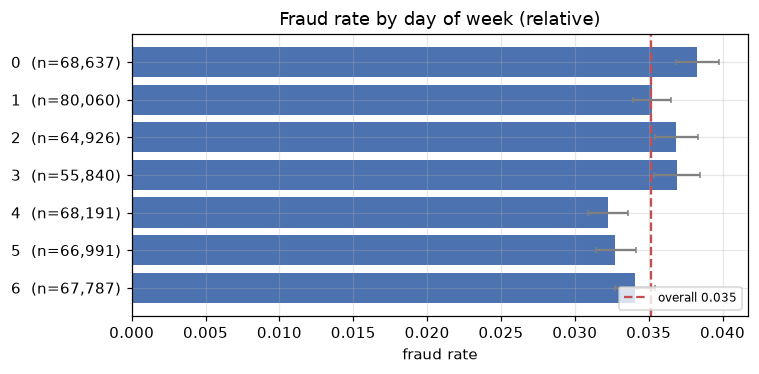

,n,fraud,rate,lo,hi
0,68637,2627,0.0383,0.0369,0.0397
1,80060,2818,0.0352,0.0339,0.0365
2,64926,2394,0.0369,0.0355,0.0383
3,55840,2061,0.0369,0.0354,0.0385
4,68191,2197,0.0322,0.0309,0.0336
5,66991,2193,0.0327,0.0314,0.0341
6,67787,2309,0.0341,0.0327,0.0355


In [69]:
dow = (tr["TransactionDT"] // 86400) % 7
dow_tab = rate_table(tr, dow).sort_index()
fig, ax = plt.subplots(figsize=(7, 3.5))
plot_rate(dow_tab, "Fraud rate by day of week (relative)", ax)
fig.tight_layout(); plt.show()
dow_tab.round(4)

**Verdict: not supported.** Fraud rates range from 3.2% to 3.8% across the seven days. That gap is small next to
the other signals in this section.

### 9.9 Unusual hour for this customer

**Hypothesis.** People shop at fairly regular times. A transaction far from the customer's usual hour may not be
the real customer.

The usual hour is the circular average of the customer's earlier hours (so 23:00 and 01:00 average to midnight,
not noon). The hour itself has an unknown offset, but distances between hours are still meaningful.

In [70]:
hour = ((tr["TransactionDT"] % 86400) // 3600).astype("float64")
ang = 2 * np.pi * hour / 24
g_uid = tr["uid"]
n_before = tr.groupby("uid").cumcount()
mean_sin = ((np.sin(ang).groupby(g_uid).cumsum() - np.sin(ang)) / n_before).where(n_before > 0)
mean_cos = ((np.cos(ang).groupby(g_uid).cumsum() - np.cos(ang)) / n_before).where(n_before > 0)
usual = (np.arctan2(mean_sin, mean_cos) * 24 / (2 * np.pi)) % 24
dev_h = (hour - usual).abs()
dev_h = np.minimum(dev_h, 24 - dev_h)
hour_dev = pd.cut(dev_h, [-0.01, 1, 3, 6, 12.01], labels=["within 1h", "1-3h", "3-6h", "6-12h"])
rate_table(tr, hour_dev.astype(object).where(dev_h.notna(), "no earlier transaction")) \
    .reindex(["within 1h", "1-3h", "3-6h", "6-12h", "no earlier transaction"]).round(4)

,n,fraud,rate,lo,hi
within 1h,72440,3277,0.0452,0.0437,0.0468
1-3h,81729,3282,0.0402,0.0388,0.0415
3-6h,73071,2744,0.0376,0.0362,0.0390
6-12h,62657,2377,0.0379,0.0365,0.0395
no earlier transaction,182535,4919,0.0269,0.0262,0.0277


**Verdict: not supported, and slightly the opposite.** Transactions within an hour of the customer's usual time have
4.5% fraud. Those 6 to 12 hours away have 3.8%. Customers with any history are riskier than new ones (about 4% vs
2.7%), but being at an odd hour for the customer doesn't add risk. As in 9.1, this fits customer-level labels:
a flagged customer's later transactions keep their usual rhythm.

### 9.10 Paying the same amount again and again

**Hypothesis.** Scripted fraud repeats the same amount. Then again, so do subscriptions and regular purchases, so
the direction isn't obvious.

In [71]:
amt_key = amt.round(2)
same_amt_before = pd.DataFrame({"uid": tr["uid"], "a": amt_key}).groupby(["uid", "a"]).cumcount()
rep = pd.cut(same_amt_before, [-0.5, 0.5, 1.5, 4.5, np.inf], labels=["0", "1", "2-4", "5+"])
rep = rep.astype(object).where(n_before > 0, "no earlier transaction")
rate_table(tr, rep).reindex(["0", "1", "2-4", "5+", "no earlier transaction"]).round(4)

,n,fraud,rate,lo,hi
0,175435,6245,0.0356,0.0347,0.0365
1,62706,2773,0.0442,0.0426,0.0459
2-4,40414,1950,0.0483,0.0462,0.0504
5+,11342,712,0.0628,0.0585,0.0674
no earlier transaction,182535,4919,0.0269,0.0262,0.0277


**Verdict: supported.** The more often a customer has paid this exact amount before, the riskier: 3.6% with no
earlier repeat, 4.4% with one, 4.8% with 2 to 4, and 6.3% with 5 or more. Repeated amounts look more like scripted
or repeated fraud than like harmless subscriptions.

### 9.11 One card, many billing regions or emails

**Hypothesis.** A card number that appears with many different billing regions or purchaser emails is being used
by several people, which suggests the card details were stolen.

`card1` is a coarse card identifier, so even honest cards can be shared by many customers. Watch for a jump at
small counts rather than at large ones.

In [72]:
def distinct_before(key, val):
    """Distinct non-missing values of `val` seen with `key` on earlier rows."""
    first = ~pd.DataFrame({"k": key, "v": val}).duplicated() & val.notna()
    return first.astype(int).groupby(key).cumsum() - first.astype(int)

def new_value(key, val):
    """1 if `key` has earlier non-missing values but never this one, 0 if seen before, NaN otherwise."""
    first = ~pd.DataFrame({"k": key, "v": val}).duplicated()
    n_prev = val.notna().astype(int).groupby(key).cumsum() - val.notna().astype(int)
    return pd.Series(np.where(val.isna() | (n_prev == 0), np.nan, first.astype(float)), index=key.index)

cuts, labels = [-0.5, 0.5, 1.5, 4.5, 20.5, np.inf], ["0", "1", "2-4", "5-20", "21+"]
card = tr["card1"]
for col, name in [("addr1", "billing regions"), ("P_emaildomain", "email domains")]:
    nb_ = pd.cut(distinct_before(card, tr[col].astype(object)), cuts, labels=labels).astype(object)
    print(f"Distinct {name} seen earlier with the same card1")
    display(rate_table(tr, nb_).reindex(labels).round(4))
flag = new_value(card, tr["addr1"].astype(object)).map({1.0: "new billing region for this card",
                                                        0.0: "billing region seen before"})
print("New billing region for this card1")
rate_table(tr, flag).round(4)

Distinct billing regions seen earlier with the same card1


,n,fraud,rate,lo,hi
0,18130,691,0.0381,0.0354,0.0410
1,50217,1132,0.0225,0.0213,0.0239
2-4,60542,1884,0.0311,0.0298,0.0325
5-20,140059,5960,0.0426,0.0415,0.0436
21+,203484,6932,0.0341,0.0333,0.0349


Distinct email domains seen earlier with the same card1


,n,fraud,rate,lo,hi
0,15740,355,0.0226,0.0203,0.0250
1,23524,530,0.0225,0.0207,0.0245
2-4,65564,1797,0.0274,0.0262,0.0287
5-20,253050,10016,0.0396,0.0388,0.0403
21+,114554,3901,0.0341,0.0330,0.0351


New billing region for this card1


,n,fraud,rate,lo,hi
billing region seen before,384272,9606,0.0250,0.0245,0.0255
(missing),65147,6413,0.0984,0.0962,0.1008
new billing region for this card,23013,580,0.0252,0.0233,0.0273


**Verdict: not supported at the `card1` level.** There is no steady rise with the number of billing regions
(3.8%, 2.3%, 3.1%, 4.3%, 3.4%) or email domains (2.3% at 0 to 4.0% at 5 to 20, then 3.4%). A new billing region for
the card has the same fraud rate as a known one (2.5% each). `card1` is too coarse: one value is shared by many
honest customers, so "many regions per card" is normal. The "(missing)" group in the last table (9.8%) mixes rows without an
`addr1` and each card's first transaction with one; rows without a billing address on their own have 11.4% fraud
(section 3).

### 9.12 One customer, many devices, emails or browsers

**Hypothesis.** A real customer uses a handful of devices and one or two email addresses. A customer that keeps
switching is suspicious.

In [73]:
cuts_u, labels_u = [-0.5, 0.5, 1.5, 2.5, np.inf], ["0", "1", "2", "3+"]
out = {}
for col, name in [("DeviceInfo", "devices"), ("P_emaildomain", "email domains"), ("id_31", "browsers")]:
    nd = pd.cut(distinct_before(tr["uid"], tr[col].astype(object)), cuts_u, labels=labels_u).astype(object)
    out[f"earlier {name}"] = rate_table(tr, nd).reindex(labels_u)[["n", "rate"]]
pd.concat(out, axis=1).round(4)

earlier devices         earlier email domains         earlier browsers        
                 n    rate                     n    rate                n    rate
0           397701  0.0273                214487  0.0278           391849  0.0262
1            41374  0.0716                176557  0.0349            40534  0.0679
2            12477  0.0798                 45338  0.0514            13890  0.0921
3+           20880  0.0851                 36050  0.0593            26159  0.0873

**Verdict: supported, with a caveat.** Fraud rises with the number of different devices (2.7% at 0 → 8.5% at 3+),
browsers (2.6% → 9.2% at 2) and email domains (2.8% → 5.9% at 3+) the customer used earlier. Part of the jump from
0 to 1 is just "device information is recorded at all", which is risky on its own (9.1). The rise from 1 to 3+ is
the cleaner evidence: 7.2% → 8.5% for devices, 3.5% → 5.9% for email domains.

### 9.13 Generic or outdated browsers

**Hypothesis.** Bots and emulators often report a generic browser, and fraud tools run old browser builds. Both
should be riskier.

"Versions behind" is how far a browser's version is below the newest version of the same browser seen so far.

In [74]:
br = tr["id_31"].astype(object)
br_low = br.str.lower()
generic = pd.Series(np.select([br.isna(), br_low.str.contains("generic", na=False)],
                              ["(missing)", "generic browser"], "named browser"), index=tr.index)
display(rate_table(tr, generic).round(4))

br_name = br_low.str.extract(r"^([a-z ]+?)\s*\d", expand=False).str.strip()
br_ver = br_low.str.extract(r"(\d+(?:\.\d+)?)", expand=False).astype("float64")
newest = br_ver.fillna(-np.inf).groupby(br_name).cummax().replace(-np.inf, np.nan)
behind = newest - br_ver
behind_b = pd.cut(behind, [-0.01, 0.01, 2, 10, np.inf], labels=["newest", "up to 2 behind", "2-10 behind", "10+ behind"])
rate_table(tr, behind_b.astype(object).where(behind.notna(), "no version")) \
    .reindex(["newest", "up to 2 behind", "2-10 behind", "10+ behind", "no version"]).round(4)

,n,fraud,rate,lo,hi
(missing),354969,7583,0.0214,0.0209,0.0218
named browser,95644,7059,0.0738,0.0722,0.0755
generic browser,21819,1957,0.0897,0.0860,0.0936


,n,fraud,rate,lo,hi
newest,69167,5012,0.0725,0.0706,0.0744
up to 2 behind,20431,1332,0.0652,0.0619,0.0687
2-10 behind,3111,286,0.0919,0.0823,0.1026
10+ behind,1157,131,0.1132,0.0962,0.1328
no version,378566,9838,0.0260,0.0255,0.0265


**Verdict: supported, modestly.** Generic browsers have 9.0% fraud against 7.4% for named ones. Browsers 10 or more
versions behind the newest seen have 11.3%, against 7.3% for the newest, though on only 1,157 rows. Browsers just
1 or 2 versions behind are not riskier (6.5%), so only clearly outdated builds stand out.

### 9.14 Device brand, screen size and email ending

**Hypothesis.** Fraud rings favour cheap, common Android phones and particular screen sizes, and foreign email
endings (`.mx`, `.de`, ...) may point to cross-border fraud. These are weaker, descriptive hypotheses: the checks
show whether any group stands out.

In [75]:
dinfo = tr["DeviceInfo"].astype(object).str.lower()
brand_rules = [("windows", "windows"), ("ios device", "apple"), ("macos", "apple"), ("sm-", "samsung"),
               ("samsung", "samsung"), ("moto", "motorola"), ("lg", "lg"), ("huawei", "huawei"),
               ("trident", "browser token"), ("rv:", "browser token"), ("pixel", "google"), ("redmi", "xiaomi")]
brand = pd.Series("other", index=tr.index, dtype=object)
for prefix, b in reversed(brand_rules):
    brand[dinfo.str.startswith(prefix, na=False)] = b
brand[dinfo.isna()] = "(missing)"
print("Device brand"); display(rate_table(tr, brand, min_n=500).round(4))

screen = tr["id_33"].astype(object)
print("Screen resolution (10 most common)"); display(rate_table(tr, screen.where(screen.notna()), top=11).round(4))

tld = tr["P_emaildomain"].astype(object).str.rsplit(".", n=1).str[-1]
print("Purchaser email ending")
rate_table(tr, tld, min_n=300).round(4)

Device brand


,n,fraud,rate,lo,hi
(missing),372896,9691,0.0260,0.0255,0.0265
windows,39722,2468,0.0621,0.0598,0.0645
apple,27926,1249,0.0447,0.0424,0.0472
browser token,10263,352,0.0343,0.0309,0.0380
samsung,9785,1126,0.1151,0.1089,0.1215
other,6562,1028,0.1567,0.1481,0.1657
motorola,2245,364,0.1621,0.1475,0.1780
lg,2111,238,0.1127,0.0999,0.1269
huawei,605,61,0.1008,0.0793,0.1274


Screen resolution (10 most common)


,n,fraud,rate,lo,hi
(missing),410619,13787,0.0336,0.0330,0.0341
1920x1080,14460,426,0.0295,0.0268,0.0323
1366x768,6669,436,0.0654,0.0597,0.0716
1334x750,5602,333,0.0594,0.0535,0.0659
2208x1242,4166,394,0.0946,0.0861,0.1038
1440x900,3792,92,0.0243,0.0198,0.0297
2048x1536,3110,54,0.0174,0.0133,0.0226
1600x900,3098,64,0.0207,0.0162,0.0263
1280x800,1882,75,0.0399,0.0319,0.0497
2560x1600,1818,41,0.0226,0.0167,0.0305


Purchaser email ending


,n,fraud,rate,lo,hi
com,374833,13937,0.0372,0.0366,0.0378
(missing),73586,2195,0.0298,0.0286,0.0311
net,19887,353,0.0178,0.0160,0.0197
mx,2087,34,0.0163,0.0117,0.0227
es,721,67,0.0929,0.0738,0.1163
gmail,411,8,0.0195,0.0099,0.0379
de,399,0,0.0000,-0.0000,0.0095
fr,358,5,0.0140,0.0060,0.0323


**Verdict: supported for device brand, mixed for screen size and email ending.**

- **Brand:** cheaper Android brands stand out. Motorola has 16.2% fraud, "other" brands 15.7%, Samsung 11.5% and
  LG 11.3%, against 4.5% for Apple and 6.2% for Windows.
- **Screen:** some resolutions differ a lot, from 0.5% (2560x1440) to 9.5% (2208x1242, a large phone). This is
  probably the device model showing through rather than a separate signal.
- **Email ending:** no consistent cross-border pattern. `.es` has 9.3% (721 rows), but `.mx` has 1.6% and `.de`
  0 of 399. Most of the difference is `.com` (3.7%) vs `.net` (1.8%).

### 9.15 Rare values

**Hypothesis.** Values that are rare so far (a card, billing region, email domain, device or exact amount that has
hardly been seen before) are riskier, because they fall outside normal traffic.

For each row, the frequency is the share of all earlier transactions with the same value. Rows are then split into
five equal groups from rarest to most common.

In [76]:
position = pd.Series(np.arange(1, len(tr) + 1), index=tr.index)
groups5 = ["rarest 20%", "2", "3", "4", "most common 20%"]
rows = {}
for col in ["card1", "addr1", "P_emaildomain", "DeviceInfo", "TransactionAmt"]:
    v = tr[col].astype(object) if col != "TransactionAmt" else amt_key
    seen = v.groupby(v).cumcount().where(v.notna())
    share = seen / position
    grp = pd.qcut(share.rank(method="first"), 5, labels=groups5)
    tab = rate_table(tr, grp.astype(object).where(share.notna(), "(missing)")).reindex(groups5)
    rows[col] = tab["rate"]
freq_tab = pd.DataFrame(rows).T
freq_tab.round(4)

,rarest 20%,2,3,4,most common 20%
card1,0.0260,0.0360,0.0443,0.0352,0.0342
addr1,0.0309,0.0227,0.0237,0.0237,0.0240
P_emaildomain,0.0267,0.0363,0.0270,0.0459,0.0446
DeviceInfo,0.1347,0.0413,0.0478,0.0770,0.0463
TransactionAmt,0.0688,0.0362,0.0268,0.0251,0.0187


**Verdict: supported for amounts and devices, slightly for billing regions; the opposite for cards and emails.**

- **Amount:** the rarest 20% of amounts have 6.9% fraud, falling steadily to 1.9% for the most common. This is
  the clearest result in the table: standard prices are safe.
- **Device:** the rarest 20% of device strings have 13.5% fraud, against 4 to 8% for the rest.
- **Billing region:** slightly: the rarest fifth of `addr1` values has 3.1%, against 2.3% to 2.4% for the rest.
- **Card, email:** the opposite of the hypothesis. Rare `card1` values are the *safest* (2.6% vs 3.4% to 4.4%), and
  rare email domains have 2.7% against 4.5% to 4.6% for the two most common fifths.

**Also: browsers.** The same rarity check for the browser string (`id_31`), which was not in the table above.

In [77]:
v = tr["id_31"].astype(object)
seen = v.groupby(v).cumcount().where(v.notna())
share = seen / position
grp = pd.qcut(share.rank(method="first"), 5, labels=groups5)
rate_table(tr, grp.astype(object).where(share.notna(), "(missing)")).reindex(groups5 + ["(missing)"]).round(4)

,n,fraud,rate,lo,hi
rarest 20%,23493,2738,0.1165,0.1125,0.1207
2,23492,2010,0.0856,0.0821,0.0892
3,23493,1793,0.0763,0.0730,0.0798
4,23492,894,0.0381,0.0357,0.0406
most common 20%,23493,1581,0.0673,0.0642,0.0706
(missing),354969,7583,0.0214,0.0209,0.0218


**Verdict: supported.** Rare browser strings are riskier: 11.7% for the rarest fifth, falling to 3.8% for the
fourth fifth (6.7% for the most common).

### 9.16 Summary

| Hypothesis | Verdict | Key numbers |
| --- | --- | --- |
| Known customer on a new device (account takeover) | Opposite direction (clear) | new device 7.1% vs known device 9.6% |
| ... new browser, email domain or product | Opposite direction (same pattern) | browser 7.9% vs 10.6%; product 2.4% vs 4.1% |
| Many cards on one device (card cycling) | Supported, rises then falls | 4.5% → 11.5% at 2 to 5 cards → 5.6% at 21+ |
| ... many customers or transactions on one device | Supported, same shape | customers 4.5% → 10.5% → 5.8% |
| Tiny purchase then a big one (card testing) | Partly supported, rare | under \$5: 6.5% (920 rows); tiny then 10x: 10.6% (132 rows) |
| Many transactions within 24 hours (burst) | Supported | 2.4% with none → 8.0% with 4 to 9 |
| ... within 1 hour or 7 days; amount spent in 24 hours | Supported; amount adds little beyond the count | 1h: 2.9% → 15.8% at 10+; 7d: 2.2% → 9.2% |
| Spending far above the customer's average | Not supported | 3.6% to 4.4% across all bands |
| ... above the previous or largest amount | Not supported | largest: 3.4% to 4.4%; previous: "about the same" riskiest (4.9%) |
| ... 24h spend far above the daily average | Opposite direction (clear) | > 5x: 1.8% vs < 0.5x: 9.4% |
| Anonymous email provider | Opposite direction (anonymous.com) | 2.3% vs 3.7% for mainstream |
| Device type doesn't match the OS | Can't be tested (46 rows) | missing OS with known device type: 11 to 13% |
| Day of week | Not supported | 3.2% to 3.8% |
| Unusual hour for this customer | Opposite direction, weak | within 1h of usual 4.5% vs 6 to 12h away 3.8% |
| Same amount paid again and again | Supported | 3.6% with no repeat → 6.3% with 5+ |
| One card with many billing regions or emails | Not supported (`card1` too coarse) | no steady rise; new region 2.5% = known region 2.5% |
| One customer with many devices, emails or browsers | Supported | devices 7.2% (1) → 8.5% (3+); emails 3.5% → 5.9% |
| Generic or outdated browser | Supported, modestly | generic 9.0% vs 7.4%; 10+ versions behind 11.3% |
| Device brand, screen size, email ending | Brand supported; screen and ending mixed | Motorola 16.2%, Samsung 11.5% vs Apple 4.5% |
| Rare values | Supported for amount, device, browser and (slightly) region; opposite for card and email | rarest amounts 6.9% vs most common 1.9%; rarest devices 13.5%; rarest browsers 11.7%; rarest `card1` 2.6% |

"Opposite direction" means the hypothesis didn't hold but the values still separate fraud the other way; it is
not the same as "reversed later" in section 11.1, which is about a pattern changing over time.

Several textbook red flags don't hold here. The main likely reason is the labelling: after a chargeback, Vesta also
labels later linked transactions as fraud, so many fraud rows are routine activity of an already-flagged customer
rather than the moment of attack, and much of the fraud comes from accounts that look fraudulent from the start.
Other possible factors: device details exist for only about a quarter of transactions, Vesta's own checks may
already block the most obvious cases, and `uid` is only an approximation of a customer.

## 10. Redundancy among C and D columns

V-column pruning is covered in section 13. Here we check the C and D groups, because highly correlated inputs make logistic regression coefficients unstable and hard to interpret. Pairwise-complete Pearson correlation.

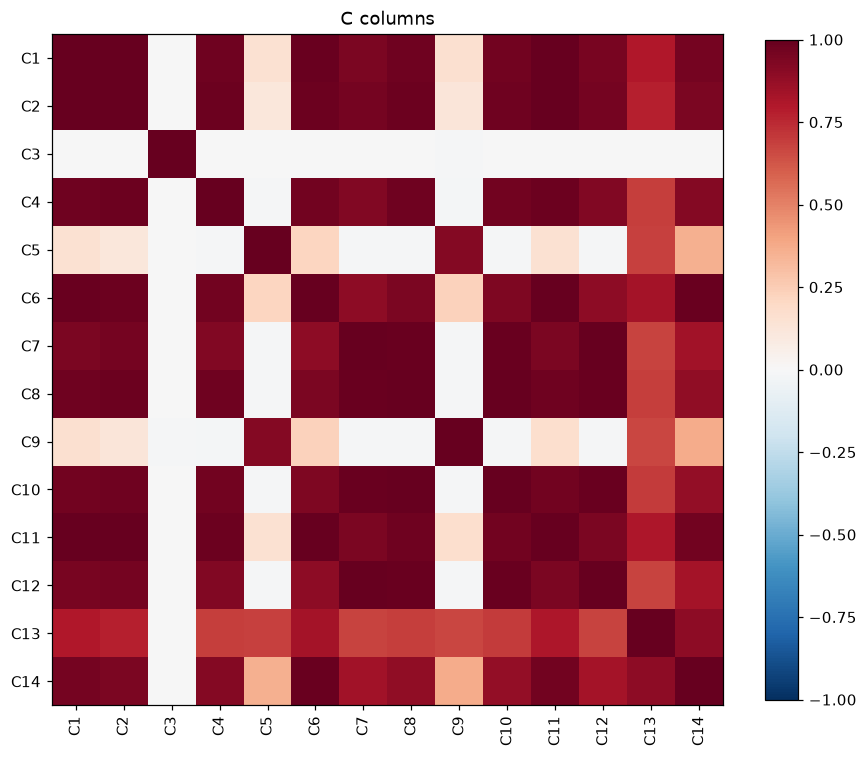

C pairs with |r| > 0.95:
C7   C12    1.000
C8   C10    0.997
C1   C11    0.997
     C2     0.995
C2   C11    0.995
C6   C11    0.993
C7   C10    0.989
C10  C12    0.988
C8   C12    0.988
C7   C8     0.988
C6   C14    0.986
C1   C6     0.985
C2   C8     0.981
     C6     0.979
C4   C11    0.979
C2   C4     0.977
     C10    0.976
C1   C8     0.974
     C4     0.973
C4   C8     0.972
C8   C11    0.971
C11  C14    0.967
C4   C6     0.967
     C10    0.966
C10  C11    0.966
C1   C10    0.965
     C14    0.958
C2   C12    0.956
     C7     0.955


In [78]:
def corr_heatmap(cols, title):
    corr = tr[cols].astype("float64").corr()
    fig, ax = plt.subplots(figsize=(0.45 * len(cols) + 2, 0.45 * len(cols) + 1.5))
    im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(range(len(cols)), cols, rotation=90); ax.set_yticks(range(len(cols)), cols)
    ax.grid(False); fig.colorbar(im, ax=ax, shrink=0.8); ax.set_title(title)
    fig.tight_layout(); plt.show()
    pairs = corr.where(np.triu(np.ones(corr.shape, bool), k=1)).stack()
    return pairs[pairs.abs() > 0.95].sort_values(key=np.abs, ascending=False)

high_c = corr_heatmap(c_cols, "C columns")
print("C pairs with |r| > 0.95:"); print(high_c.round(3).to_string() if len(high_c) else "none")

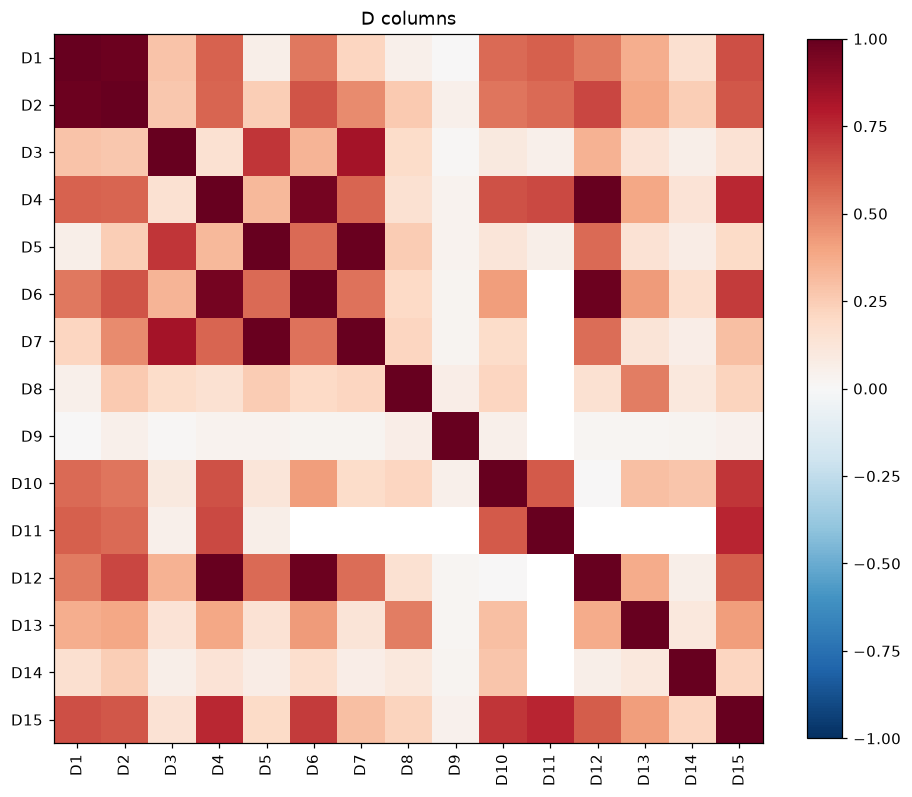

D pairs with |r| > 0.95:
D4  D12    1.000
D5  D7     0.989
D1  D2     0.982
D6  D12    0.978
D4  D6     0.955


In [79]:
d_cols = [f"D{i}" for i in range(1, 16) if f"D{i}" in tr.columns]
high_d = corr_heatmap(d_cols, "D columns")
print("D pairs with |r| > 0.95:"); print(high_d.round(3).to_string() if len(high_d) else "none")

## 11. Shift between training and validation blocks (no labels)

How different does the validation period look? This uses only features of the validation rows, never their labels.

In [80]:
def share(frame, col):
    s = frame[col].astype(object).where(frame[col].notna(), "(missing)")
    return s.value_counts(normalize=True)

for col in ["ProductCD", "card6", "DeviceType"]:
    if col in tr.columns:
        comp = pd.concat({"train": share(tr, col), "val": share(va, col)}, axis=1).fillna(0)
        comp["change (pts)"] = (comp["val"] - comp["train"]) * 100
        display(comp.round(3))

,train,val,change (pts)
ProductCD,,,
W,0.732,0.817,8.455
C,0.119,0.095,-2.410
R,0.068,0.043,-2.485
H,0.063,0.026,-3.641
S,0.017,0.018,0.081


,train,val,change (pts)
card6,,,
debit,0.741,0.776,3.574
credit,0.258,0.211,-4.644
(missing),0.002,0.013,1.080
debit or credit,0.000,0.000,-0.006
charge card,0.000,0.000,-0.003


,train,val,change (pts)
DeviceType,,,
(missing),0.751,0.829,7.798
desktop,0.151,0.104,-4.716
mobile,0.098,0.067,-3.081


In [81]:
qs = [0.05, 0.25, 0.5, 0.75, 0.95]
pd.DataFrame({
    "train amount": tr["TransactionAmt"].quantile(qs),
    "val amount": va["TransactionAmt"].quantile(qs),
}).round(2).assign(**{
    "has_identity train": tr["has_identity"].mean(),
    "has_identity val": va["has_identity"].mean(),
})

,train amount,val amount,has_identity train,has_identity val
0.05,20.00,20.95,0.254987,0.175433
0.25,42.95,44.00,0.254987,0.175433
0.50,68.95,68.50,0.254987,0.175433
0.75,125.00,125.00,0.254987,0.175433
0.95,441.95,445.00,0.254987,0.175433


In [82]:
# Category values that appear in validation but never in training (new devices, browsers, email domains)
for col in ["P_emaildomain", "id_30", "id_31", "DeviceInfo"]:
    if col in tr.columns:
        seen = set(tr[col].dropna().astype(str))
        v = va[col].dropna().astype(str)
        print(f"{col:15s} val rows with a value unseen in train: {(~v.isin(seen)).mean():.1%}")

P_emaildomain   val rows with a value unseen in train: 0.0%
id_30           val rows with a value unseen in train: 0.6%
id_31           val rows with a value unseen in train: 11.8%
DeviceInfo      val rows with a value unseen in train: 1.6%


### 11.1 Feature stability over time

The shift checks above compare value distributions. This check asks a different question: does each column's
**relationship with fraud** hold over time? A column whose signal fades or reverses would teach a model rules that
stop working on later months.

For each column, on its own, within the training block:

1. **Learn on the first 30 days.** Split the column into bins (each value is a bin when there are 20 or fewer
   distinct values, otherwise 20 quantile bins; missing is its own bin) and take each bin's fraud rate, shrunk
   towards the overall rate so tiny bins don't get extreme values.
2. **Score the last 30 days** of the training block with those rates (values never seen early get the overall rate)
   and compute the AUC.
3. **Measure the early signal out of sample:** split the first 30 days into two halves by time, score each half with
   rates learned on the other half, and compute the AUC. Scoring the same rows the rates were learned on would
   make pure noise look like a signal (about 0.52).

An AUC above 0.5 means the pattern ranks fraud above non-fraud; 0.5 means no signal; below 0.5 means the pattern
has reversed. Intervals use the Hanley-McNeil standard error. Because hundreds of columns are tested, a column is
only called unstable on strong evidence (99.9% intervals):

- **holds later:** late AUC above 0.5 (95% interval);
- **reversed later:** late AUC below 0.5 (99.9% interval);
- **faded later:** neither, but a clear early signal (early AUC above 0.5, 99.9% interval);
- **weak in both windows:** no clear signal in either window. For a column filled on very few rows this is expected
  whatever its signal on those rows, so this test can't judge it.

This tests each column alone, so it says nothing about how a column works in
combination with others. The function is `time_stability` in `src/feature_selection.py`.

In [88]:
from src.feature_selection import time_stability

EARLY_DAYS = LATE_DAYS = 30
early = tr[tr["TransactionDay"] <= tr["TransactionDay"].min() + EARLY_DAYS - 1]
late = tr[tr["TransactionDay"] >= tr["TransactionDay"].max() - LATE_DAYS + 1]

skip = {"TransactionID", "TransactionDT", "TransactionDay", "isFraud", "uid"}
stab_frame = tr.drop(columns=["uid"]).copy()
# for comparison: the D columns that 7.2 found to count from a fixed date, as TransactionDay - D
for c in ["D1", "D4", "D10", "D11", "D15"]:
    stab_frame[f"day − {c}"] = stab_frame["TransactionDay"] - stab_frame[c]
stab = time_stability(stab_frame, [c for c in stab_frame.columns if c not in skip])
stab = stab.rename(columns={"auc_early": "AUC early (out of sample)", "auc_late": "AUC late",
                            "late_low": "late 95% low", "late_high": "late 95% high"})
del stab_frame
group = pd.Series(np.select([stab.index.str.match(r"V\d+$"), stab.index.str.startswith("day − ")],
                           ["V", "day − D (for comparison)"], "other"), index=stab.index)
print(f"early window: days {early.TransactionDay.min()}-{early.TransactionDay.max()} ({len(early):,} rows, "
      f"{early.isFraud.sum():,} fraud); late window: days {late.TransactionDay.min()}-{late.TransactionDay.max()} "
      f"({len(late):,} rows, {late.isFraud.sum():,} fraud)")
pd.crosstab(stab["result"], group, margins=True)

/Users/domi_bryan/Documents/GitHub/bt4012/src/feature_selection.py:50: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return col_early.astype(object).fillna("(missing)"), col_late.astype(object).fillna("(missing)")
/Users/domi_bryan/Documents/GitHub/bt4012/src/feature_selection.py:50: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return col_early.astype(object).fillna("(missing)"), col_late.astype(object).fillna("(missing)")
/Users/domi_bryan/Documents/GitHub/bt4012/src/feature_selection.py:50: FutureWarning: Downcasting object dtype arrays on .fillna, .f

early window: days 1-30 (134,339 rows, 3,401 fraud); late window: days 112-141 (86,134 rows, 3,388 fraud)


col_0,V,day − D (for comparison),other,All
result,,,,
constant early,6,0,0,6
faded later,29,0,2,31
holds later,249,5,76,330
reversed later,36,0,5,41
weak in both windows,19,0,10,29
All,339,5,93,437


In [84]:
# Non-V columns whose early pattern does not hold later
cols_show = ["AUC early (out of sample)", "AUC late", "late 95% low", "late 95% high", "result"]
not_holding = stab[(group == "other") & (stab["result"] != "holds later")].sort_values("AUC late")
display(not_holding[cols_show].round(3))
print("V columns that reverse later:", ", ".join(stab.index[(group == "V") & (stab["result"] == "reversed later")]))
print("V columns whose signal faded later:", ", ".join(stab.index[(group == "V") & (stab["result"] == "faded later")]))
print("V columns weak in both windows:", ", ".join(stab.index[(group == "V") & (stab["result"] == "weak in both windows")]))
print("Constant in the early window (cannot be tested):", ", ".join(stab.index[stab["result"] == "constant early"]))

,AUC early (out of sample),AUC late,late 95% low,late 95% high,result
id_38,0.578,0.348,0.340,0.356,reversed later
card4,0.522,0.464,0.454,0.473,reversed later
id_14,0.559,0.476,0.466,0.485,reversed later
id_34,0.555,0.477,0.467,0.487,reversed later
id_32,0.556,0.478,0.469,0.488,reversed later
id_30,0.585,0.489,0.479,0.499,faded later
id_26,0.497,0.498,0.488,0.508,weak in both windows
id_25,0.484,0.498,0.488,0.508,weak in both windows
id_22,0.484,0.498,0.489,0.508,weak in both windows
id_08,0.485,0.500,0.490,0.510,weak in both windows


V columns that reverse later: V14, V25, V26, V27, V28, V55, V61, V65, V66, V68, V88, V89, V138, V141, V142, V151, V159, V160, V161, V162, V163, V285, V322, V323, V324, V325, V326, V327, V328, V329, V330, V334, V335, V337, V338, V339
V columns whose signal faded later: V41, V56, V62, V67, V100, V143, V144, V145, V146, V147, V148, V149, V150, V152, V153, V154, V155, V156, V157, V158, V164, V165, V166, V296, V298, V331, V332, V333, V336
V columns weak in both windows: V19, V20, V23, V24, V104, V117, V118, V119, V120, V121, V122, V286, V297, V299, V300, V305, V311, V319, V321
Constant in the early window (cannot be tested): V106, V107, V129, V135, V137, V281


**Why do some identity columns reverse or fade?** The OS, screen and related columns (`id_30`, `id_32`, `id_33`,
`id_34`, `id_14`) are the block found in 6.1, where "missing inside an identity record" had much more fraud. Here is
that pattern in the two windows, together with `id_38` and `card4`, which also reverse:

In [85]:
window = pd.Series(np.where(tr["TransactionDay"].isin(early["TransactionDay"]), "first 30 days",
                             np.where(tr["TransactionDay"].isin(late["TransactionDay"]), "last 30 days", None)),
                    index=tr.index)
in_window = window.notna()
id_state = pd.Series(np.select([tr["has_identity"] == 0, tr["id_30"].isna()],
                               ["no identity record", "identity record, id_30 missing"], "identity record, id_30 filled"),
                     index=tr.index)
for name, s in [("id_30 state", id_state), ("id_38", tr["id_38"].astype(object).fillna("(missing)")),
                ("card4", tr["card4"].astype(object).fillna("(missing)"))]:
    t = (tr[in_window].groupby([s[in_window], window[in_window]])["isFraud"].agg(n="size", rate="mean")
         .unstack().round(4))
    print(name); display(t)

id_30 state


n                       rate             
                               first 30 days last 30 days first 30 days last 30 days
identity record, id_30 filled          41539         6215        0.0151       0.0626
identity record, id_30 missing         16521        10818        0.0754       0.1378
no identity record                     76279        69101        0.0200       0.0218

id_38


n                       rate             
          first 30 days last 30 days first 30 days last 30 days
id_38                                                          
(missing)         77643        69532        0.0198       0.0220
F                 15855        12556        0.0129       0.1282
T                 40841         4046        0.0406       0.0608

card4


n                       rate             
                 first 30 days last 30 days first 30 days last 30 days
card4                                                                 
(missing)                    8            5        0.2500       0.0000
american express          4429          666        0.0099       0.0300
discover                  1931          919        0.0238       0.1219
mastercard               39627        28795        0.0291       0.0326
visa                     88344        55749        0.0244       0.0416

In [86]:
# D columns: raw values vs TransactionDay - D (see 7.2)
d_rows = [c for c in ["D1", "D4", "D10", "D11", "D15"]] + [f"day − {c}" for c in ["D1", "D4", "D10", "D11", "D15"]]
stab.loc[d_rows, cols_show].round(3)

,AUC early (out of sample),AUC late,late 95% low,late 95% high,result
D1,0.586,0.618,0.607,0.628,holds later
D4,0.596,0.557,0.547,0.567,holds later
D10,0.595,0.622,0.612,0.633,holds later
D11,0.538,0.674,0.664,0.684,holds later
D15,0.602,0.592,0.581,0.602,holds later
day − D1,0.558,0.604,0.594,0.614,holds later
day − D4,0.583,0.555,0.545,0.566,holds later
day − D10,0.566,0.569,0.559,0.579,holds later
day − D11,0.527,0.684,0.674,0.694,holds later
day − D15,0.587,0.579,0.569,0.589,holds later


**Findings.** Rates learned on days 1–30, scored on days 112–141 (about 3,400 fraud rows in each window):

| Result | V columns | Other columns |
| --- | --- | --- |
| Holds later | 249 | 76 |
| Reversed later | 36 | 5 |
| Faded later | 29 | 2 |
| Weak in both windows | 19 | 10 |
| Constant early (untestable) | 6 | 0 |

- **Most columns hold.** 325 of the 432 raw columns still rank fraud above non-fraud in the last month.
- **Five non-V columns reverse:** `id_38` (AUC 0.35), `card4`, and `id_32`, `id_34`, `id_14` from the OS/screen
  block. `id_30` (OS) and `id_33` (screen) fade. The tables above show why:
  - `id_30` filled in an identity record went from 41,539 rows at 1.5% fraud to 6,215 rows at 6.3%, so it went from
    safer than "no identity record" (2.0%) to riskier. The field was recorded far less often later, which looks like
    a change in data collection rather than in fraud. "Missing inside an identity record" stayed the riskiest state
    (7.5% → 13.8%), so the 6.1 finding still holds; it is the individual values that don't.
  - `id_38 = F` went from the safest value (1.3%) to the riskiest (12.8%), while `id_38 = T` fell from 40,841 rows
    to 4,046.
  - `card4`: Discover went from 2.4% to 12.2%, overtaking Visa and Mastercard.
- **Weak in both windows:** among non-V columns, `C3` and the rarely filled `id_07`, `id_08`, `id_21`–`id_27`.
  Most are filled on about 1% of rows, so their AUC over all rows stays near 0.5 regardless; this test says little
  about them.
- **V columns:** the whole V322–V339 block reverses or fades, along with parts of V14–V28, V55–V68 and V138–V163.
  Most of the other faded V columns are in V143–V166.
- **D columns:** raw and `TransactionDay − D` versions are about equally stable on their own (all hold). A
  start date learned in month 1 can't place customers who opened accounts later, so on its own the normalised
  version gains nothing; its value is in identifying customers (5.1, 7.2), not as a stand-alone predictor.

## 12. Findings to carry into the report

All numbers are from the training block (days 1 to 141, 472,432 rows, fraud rate 3.5%) unless a line says
validation. Each finding points to the decision it supports.

These are associations in the training period, not causes. Transactions from the same customer aren't
independent, so the 95% intervals shown are optimistic. No model is fitted in this notebook.
`reports/eda_findings.md` (written by `src/eda.py` when the notebook runs) has the short descriptive summary.

**Basics**

- **Fraud is rare.** 3.5% of training rows. → Use PR-AUC, not accuracy; no resampling.
- **Amounts have a long upper tail.** Legitimate: mean 133.87, median 68.50, maximum 31,937; fraud: mean
  149.04, median 76.13, maximum 5,191 (7). → Keep extreme amounts (nothing is clipped); use log amount for
  linear models.

**Time and validation**

- **Fraud rate drifts.** It is 2.5% in the first 30 days and about 4.0% in the next three months, then 3.5% in
  the last 21 days. Over complete weeks the rate ranges from 2.1% to 5.1% (4). → Split by time, and expect some gap between CV and
  later blocks.
- **Some patterns happen once.** C13 has a one-off burst on days 13 to 15 that reaches about 2,900, with 11% fraud
  (three times the baseline), and values above 2,000 never come back (7.1). → A random split would let a model
  memorise that burst. This is another reason
  for time-based CV.
- **The validation block looks different.** ProductCD W goes from 73% to 82% of rows, credit cards from 26% to
  21%, and rows with an identity record from 25% to 18%. 11.8% of validation rows use a browser version (id_31)
  never seen in training. → Expect validation scores to differ from CV, and prefer grouped features (browser family
  rather than exact version) over raw strings.

- **Some columns' link to fraud doesn't hold over time (11.1).** Fitting each column alone on days 1–30 and scoring
  days 112–141, 325 of the 432 raw columns still separate fraud, 41 reverse and 31 had a clear signal early that
  faded. These include `id_38` (AUC 0.35), `card4`, the OS/screen columns `id_30`, `id_32`, `id_33`, `id_34`,
  `id_14`, and the whole V322–V339 block. `id_30` was recorded far less often later (41,539 → 6,215 rows in an identity record), so its values changed
  meaning. → Excluded in section 13 as a proposal, or replaced with coarser versions (for example "missing inside an identity
  record" instead of the raw value); confirm with one model run before freezing.

**Customers**

- **Fraud is labelled per customer.** If a uid's previous transaction was fraud, the next one is fraud 76.8% of
  the time, compared with 1.0% when the previous one wasn't. 58.8% of fraud rows sit in uids where every row is fraud.
  → Customer-history features, time-based CV, and RQ3 (is a customer profile enough?).
- **Stricter customer keys trade history for consistency (5.1).** card1 alone gives 38.6%
  label persistence; adding the account start (`TransactionDay − D1`) raises it to 66.3%, and addr1 to 76.8%.
  Adding email raises it to 85.2% but leaves only 51.5% of rows with earlier history (61.4% for uid). → Use uid as
  the customer key for history features and grouping.
- **The spread of a customer's earlier values adds little (8.1).** Customers whose amounts vary most have
  slightly less fraud (3.8% vs 4.4–4.7%), but not in the first 30 days. The spread of `TransactionDay − D` for D4, D10, D11
  and D15 shows no consistent ordering, and its low-spread group changes over time (D10: 6.0% → 2.6%). → At most a
  weak candidate for amount; not for the D dates.
- **About half the validation rows come from new customers.** 48.6% of validation rows come from a uid seen in training (99.0%
  for card1). → History features can only help about half of the later rows. Report results separately for
  returning and new customers.
- **Account age matters.** Fraud rate is 12.1% at D1 = 1 and 12.0% at D1 = 2, against 4.1% at D1 = 0. D1 = 0
  covers 49% of rows and 58% of all fraud. → Keep D1 as a feature.
- **D columns count up with time.** The upper edge of D1 and D15 rises one day per day, and fraud from a single
  account forms short diagonals (7.1). Of the 15 D columns, D1, D4, D10, D11 and D15 count days from a fixed
  date: their top values rise 0.93–0.97 days per day, and after `TransactionDay − D` the value is constant for
  65–100% of customers instead of 22–36% (7.2). D2 repeats D1; the others don't count from a fixed date or are
  about 90% missing. → Add `TransactionDay − D` for D1, D4, D10, D11 and D15 next to the raw columns (not instead of them; 11.1).
  D1's version is also the account start in the customer ID.

**Missingness**

- **Missing is a signal, in both directions.** Fraud rate is 11.4% when addr2 is missing vs 2.5% when present.
  Rows with D7 present have 15.0% fraud vs 2.7% when missing. R_emaildomain, DeviceType and most id columns
  follow the same pattern (fraud more likely when present). → Keep NaN as its own value for tree models, and add
  missing indicators for linear models.
- **V columns go missing in blocks.** There are 14 blocks, and four of them are missing on the same rows as one D
  column: V1-V11 with D11 (identical), V12-V34 with D10, V35-V52 with D4 and V75-V94 with D15 (different on only 28
  to 36 rows; section 3). → Prune V columns within
  blocks, and use one missing-pattern feature per block instead of hundreds of per-column flags.
- **Identity records depend on product.** ProductCD W never has an identity record, and C almost always does. →
  Read has_identity together with ProductCD.

**Identity columns (6.1)**

- Among rows with an identity record, OS, browser and screen (`id_30`, `id_31`, `id_33`) separate fraud the most.
- Missing OS/screen inside an identity record has about 11% fraud vs about 4.4% when filled.
- `id_12` and `id_27` add almost nothing.
- The nine 99%-missing columns cover only about 4,000 transactions.

→ Drop `id_12` and `id_27`. Keep the browser (grouped) and the missing-inside-an-identity-record pattern; the raw OS
and screen values don't hold over time (11.1) and are excluded in section 13. The 99%-missing columns are kept.

**Categories**

- **Product and card type (6).** ProductCD C has 11.3% fraud vs 2.1% for W. Credit cards have 6.7% vs 2.4% for debit,
  and discover has 7.4%. → Keep ProductCD and card6 as categories. card4 on its own doesn't hold over time (11.1) and
  is excluded in section 13; card network and type together still separate fraud (6.2).
- **Email.** The purchaser's outlook.com has 9.2% fraud and hotmail.com 5.2%, while sbcglobal.net and att.net are
  under 0.7%. Same purchaser and recipient domain gives 9.3% vs 2.8% for different domains. → Group email domains by
  provider, and add a purchaser = recipient flag.
- **Device.** Mobile has 9.9% fraud, desktop 6.2%, and no device record 2.1%.
- **Grouped and combined categories (6.2).** Recipient provider: Google 11.5% vs other 1.6%. Credit cards 6.7–7.6%
  except American Express credit (2.9%). `card3` other than its most common value: 11.2% vs 2.5% (38% of fraud);
  `addr2` likewise 10.4% vs 2.4%. No true M flag: 5.9% vs 1.6–3.0%. → Worth grouped and combined features.
- **Hour (4).** The quiet hours 6 to 10 have 6.9–10.6% fraud vs 2.1–3.9% in busy hours. → Keep hour of day.

**Amounts and counts**

- **Decimals point to foreign purchases.** Amounts with more than two decimals have 11.3% fraud vs 1.1% for exact
  cents. → Add amount-decimals features. Cents endings separate fraud too (`.95` 0.7%, uncommon endings 9.5%; 7).
- **Some round amounts are risky, but not round amounts in general; standard prices are safe.** \$300 has 14.4%
  fraud and \$450 33.6%, but \$100 has 2.5% and whole-dollar amounts overall 3.6%, about the baseline (7). The very
  common \$57.95 and \$107.95 have 0.4% and 0.7%. → No general round-amount flag; how often an exact amount has
  been seen before (9.15) captures standard prices.
- **C counts.** Fraud rate rises with C1, from 2.4% at C1 = 1 to 9.0% at C1 = 10. C13 = 0 has 14.0% fraud and
  covers 24% of all fraud. The 95th percentile of C1 is 122 for fraud vs 19 for non-fraud. → Keep the raw C
  columns, and add C relative to the customer's own past values (8.2: C1 above twice its past average 14.1% vs
  3.3%; C13 below half 7.0% vs 3.6%).
- **dist1.** Fraud rate is 4.5% when dist1 is missing vs 2.0% when present, and it rises in the top deciles.

**Domain-knowledge hypotheses (section 9)**

- **Supported:**
  - many transactions from the same customer within 24 hours (2.4% → 8.0%);
  - several cards on the same device (up to 11.5% at 2 to 5 cards, falling again for widely shared devices);
  - the same amount paid repeatedly (3.6% → 6.3%);
  - a customer switching between many devices or emails (emails 3.5% → 5.9%);
  - generic or clearly outdated browsers (9.0% and 11.3%);
  - cheaper Android brands (Motorola 16.2%, Samsung 11.5% vs Apple 4.5%);
  - rare amounts, devices and browsers (6.9%, 13.5% and 11.7% in the rarest fifth), and slightly rare billing
    regions (3.1% vs 2.3–2.4%);
  - many customers or transactions on one device, and 1-hour and 7-day transaction counts (1h: 2.9% → 15.8%).

  → Worth building as past-only customer, device and frequency features.
- **Partly supported but rare:** card testing (tiny purchases 6.5%, on only 0.2% of rows). → Cheap to include, but
  expect a small effect.
- **Opposite direction, but a clear difference:** the hypothesis didn't hold, yet the values still separate fraud,
  the other way round:
  - a new device, browser, email or product for a known customer is *less* risky than a known one (device 7.1% vs
    9.6%, browser 7.9% vs 10.6%);
  - anonymous providers are safer than mainstream ones (anonymous.com and protonmail.com together 2.4% vs 3.7%;
    protonmail.com alone has 46%, but on only 67 rows);
  - 24-hour spend far above the customer's daily average is *safer* (1.8% vs 9.4% below half);
  - rare `card1` and email values are safer, not riskier (rarest `card1` fifth 2.6%);
  - the customer's usual hour is slightly riskier than an unusual one (4.5% vs 3.8%; weak).

  → Still usable as signals, as long as they hold over time; just not as the original red flags.
- **No signal:**
  - spending far above the usual, previous or largest amount;
  - many billing regions or emails per `card1`;
  - day of week.

  → Low priority. If they are built anyway, the model should be expected to ignore them.
- **Unexpected red flags:** device type recorded but OS missing (11 to 13% fraud) → worth a flag of its own. Missing
  billing address (11.4%, section 3) → already carried by keeping NaN for tree models and missing indicators for
  linear ones (Missingness above).

**Redundancy**

- **Many C pairs are near copies.** C7/C12 have r = 1.000, and C8/C10 and C1/C11 0.997. D4/D12 have r = 1.000. →
  Trees handle them, and regularised logistic regression copes; removing them inside the linear pipeline is optional
  (section 13).

## 13. Proposed columns to exclude from model inputs

This is a proposal for the group, based on the analysis above. All models should get the **same set of input
columns**, so that differences between models come from the models and not from what they were given. How each
model represents those columns (imputation, scaling, encoding) can differ, as long as it's fitted on training
rows only.

The result: **436 columns → 197 model inputs** (113 of them V columns), before any engineered features. The 436
are every column except the target, including the derived `uid` (section 2's 436 include the target instead). The code
cell below builds the list and checks the counts.

### Exclude

| Column(s) | Reason | Evidence |
| --- | --- | --- |
| `TransactionID` | Row identifier. It carries no information about the transaction. | none needed |
| `TransactionDT`, `TransactionDay` | Raw time. A model would learn "which period is this", and that doesn't carry over to later months. The fraud rate itself drifts between months. Keep them for building time-based features and splits only. | Section 4: 2.5% fraud in the first 30 days vs about 4% later; complete weeks 2.1% to 5.1% |
| `uid` | Built to group a customer's transactions. As an input, a model could memorise customers whose later transactions are labelled fraud, which doesn't carry over to new customers. | Section 5.2: 76.8% fraud after a fraud vs 1.0%; 48.6% of validation rows come from customers seen in training |
| `id_12`, `id_27` | Add nothing beyond whether an identity record exists. | Section 6.1: fraud-rate spread 0.014 and 0.003 within identity rows |
| Redundant V columns (197 of 339) | Inside each block of V columns that go missing together, many are near-copies. Pruning at \|r\| > 0.75 keeps 142. | Section 3: 14 V blocks with identical missing patterns. Threshold chosen in `notebooks/03_v_threshold.ipynb` |
| Columns whose link to fraud reversed or faded over time (7 non-V, 29 more V) | A model would learn a pattern that no longer holds in later months. Non-V: `id_38`, `card4`, `id_32`, `id_34`, `id_14` (reversed), `id_30`, `id_33` (faded). The V list is printed below. | Section 11.1: e.g. `id_38` AUC 0.58 early → 0.35 late; `id_30` was recorded far less often later (41,539 → 6,215 rows in an identity record) |

**V threshold.** r = 0.75 is chosen in `notebooks/03_v_threshold.ipynb` (logistic regression, the model most
affected by redundant columns, with the same expanding-window CV); see its section 6. On the whole training block
it keeps 142 of the 339 V columns. The stability exclusions were applied after that sweep, so the 197-column set
as a whole has not yet been tested with a model; a quick check with one model is advisable before freezing.

### Considered, but kept

| Column(s) | Why it was considered | Why it is kept |
| --- | --- | --- |
| `id_07`, `id_08`, `id_21` to `id_26` | 99% missing; weak in both windows in 11.1 | They are filled on about 1% of rows, so a test over all rows can't judge them. They have some signal where filled (e.g. `id_23` anonymous proxy 12.0% vs 5.5%, section 6.1), and they can't hurt much. A linear pipeline may drop them as a preprocessing step. |
| `C3` and V columns weak in both windows or constant early | No clear signal in 11.1 | No sign of a pattern that changes over time, only a weak one. Cheap to keep; tree models ignore them. |
| Near-duplicate C and D columns (e.g. C7/C12 r = 1.000, D2/D1 0.982) | Redundant | Tree models aren't affected, and regularised linear models cope. If the group wants them removed for logistic regression, do it inside the linear pipeline, keeping the column of each pair that is filled more often (e.g. keep `D4` over `D6`). |
| Raw D columns | D1, D4, D10, D11 and D15 count up with time (sections 7.1, 7.2), so a value means different things early and late | Their signal holds over time on its own (11.1: all hold, e.g. `D1` AUC 0.59 → 0.62), and `D1` is a strong signal (12% fraud at 1 to 2 days, section 7). `TransactionDay − D` versions of D1, D4, D10, D11 and D15 can be **added**; on their own they are no more stable than the raw columns, so they shouldn't replace them. |
| `id_31` (browser) | Many distinct values; 11.8% of validation rows have a browser version unseen in training (section 11) | Its signal holds over time (11.1). A grouped version (browser name) is more robust to new versions. The other OS/screen columns are excluded above; what survives from them is "missing inside an identity record" (7.5% → 13.8% fraud, 11.1), which a coarser flag can carry. |
| Mostly-missing columns (`dist2`, `D7`, M flags, identity columns) | Large share missing | Whether they are missing is itself a strong signal (section 3: e.g. 15.0% fraud when `D7` is present vs 2.7%). Keep the NaN for tree models, and add missing indicators for linear ones. |
| `card1`, `addr1` | Look like identifiers | They are coarse codes shared by many customers (12,730 `card1` values, median 4 rows each, section 5.2), not row IDs. Fraud rates differ by value (section 9.11). |

In [87]:
V_R = 0.75   # chosen in notebooks/03_v_threshold.ipynb (section 6)

from src.feature_selection import prune_v   # same greedy rule as src/data_profile.py

v_kept, v_drop = prune_v(tr, V_R)

ID_TIME = ["TransactionID", "TransactionDT", "TransactionDay", "uid"]
NO_INFO = ["id_12", "id_27"]
raw_stab = stab.loc[[c for c in stab.index if not c.startswith("day − ")]]
unstable = raw_stab.index[raw_stab["result"].isin(["reversed later", "faded later"])]
UNSTABLE = [c for c in tr.columns if c in set(unstable) and c not in set(ID_TIME + NO_INFO + v_drop)]

EXCLUDE = ID_TIME + NO_INFO + v_drop + UNSTABLE
assert len(EXCLUDE) == len(set(EXCLUDE)) and not [c for c in EXCLUDE if c not in tr.columns]
candidates = [c for c in tr.columns if c != "isFraud"]
kept = [c for c in candidates if c not in set(EXCLUDE)]
is_v = lambda c: c.startswith("V") and c[1:].isdigit()
print(f"columns in the joined table (excl. target): {len(candidates)}")
print(f"proposed exclusions: {len(EXCLUDE)}")
print(f"  identifiers/time: {len(ID_TIME)}, no added information: {len(NO_INFO)}")
print(f"  redundant V columns at r = {V_R}: {len(v_drop)} (V kept: {len(v_kept)} of 339)")
print(f"  signal reversed or faded over time (11.1), not already excluded: {len(UNSTABLE)} "
      f"({sum(map(is_v, UNSTABLE))} V, {sum(not is_v(c) for c in UNSTABLE)} other)")
print(f"columns left as model inputs: {len(kept)} (of which V: {sum(map(is_v, kept))})")
print()
print("Excluded for stability, non-V:", ", ".join(c for c in UNSTABLE if not is_v(c)))
print("Excluded for stability, V:", ", ".join(c for c in UNSTABLE if is_v(c)))

columns in the joined table (excl. target): 436
proposed exclusions: 239
  identifiers/time: 4, no added information: 2
  redundant V columns at r = 0.75: 197 (V kept: 142 of 339)
  signal reversed or faded over time (11.1), not already excluded: 36 (29 V, 7 other)
columns left as model inputs: 197 (of which V: 113)

Excluded for stability, non-V: card4, id_14, id_30, id_32, id_33, id_34, id_38
Excluded for stability, V: V14, V26, V27, V41, V56, V62, V65, V67, V68, V88, V89, V100, V138, V142, V146, V156, V160, V162, V166, V285, V296, V298, V322, V323, V325, V328, V329, V332, V335
